# CIS341 專題一：天氣分類（Weather Classification）

**學生：** S26202765
**課程：** CIS341
**截止時間：** 2026-11-15 23:59（香港時間，UTC+8）

## 資料集與提交連結（Dataset & Submission Links）

**所有提交內容都在同一個壓縮檔內。** 這個 notebook 本身就是壓縮檔的一部分，
解壓後與 `weather_lib.py` 並排放在根目錄，課程要求的四項提交物都已經依
`weather_lib.py` 讀取的路徑放好，不需要搬動或改名：

| 提交項目 | 壓縮檔內位置 |
| --- | --- |
| 資料集（原始影像，2703 張、六個類別） | `datasets/hand-filtered/<class>/` |
| 檔案清單與類別／訓練驗證分割 | `datasets/metadata/image_index.csv`、`datasets/splits/four_class_split.csv`、`datasets/splits/six_class_split.csv` |
| 訓練好的模型（四個權重 + 三個 JSON 契約） | `models/` |
| 示範影片（四段錄影用的片段） | `videos/` |

另外三個資料夾是為了讓 notebook 能重跑而一併附上的：

| 資料夾 | 用途 |
| --- | --- |
| `runs/history.json`、`runs/diagnostics/` | 每個 epoch 的訓練歷史（6.3 節曲線用）與 6.4.2 節的兩個 BN 診斷模型 |
| `Reports/shots/` | 7.2 節介面截圖，notebook 以相對路徑引用 |
| `README.txt` | 解壓後的目錄說明、`RETRAIN` 開關的行為、前處理契約 |
| `recordings/` | 英文旁白的螢幕錄影（7 分 22 秒，上限 7 分 30 秒） |

解壓後直接開啟 `project1.ipynb` 執行即可。6.1 節的 `RETRAIN = False` 會載入
`models/` 內的權重與 `runs/history.json` 的歷史，不會重新訓練。

## 目錄（Contents）

1. 程式庫匯入與設定（Library Imports & Configuration）
2. 資料收集（Data Collection）
3. 資料準備（Data Preparation）
4. 資料增強（Data Augmentation）
5. 模型設計（Model Design）
6. 模型訓練與分析（Model Training & Analysis）
7. 影像介面（Image Interface / Gradio）
8. 影片推論（Video Inference）
9. 六類別延伸（Six-Class Extension）


## 1. Library Imports & Configuration（程式庫匯入與設定）

匯入所有會用到的程式庫，並設定全域隨機種子（seed）與路徑（path），供整份 notebook 使用。

**AI 使用（本節）。** 工具：GitHub Copilot agent（Claude）。匯入清單與種子設定由它起草。

* **採用**：`tf.keras.utils.set_random_seed(SEED)` 一次固定 Python、NumPy 與 TensorFlow
  三個來源 —— 分開設容易漏掉一個，而漏掉的那個正是 `tf.data` 洗牌用的。
* **我改的一處**：路徑原本寫死成 `c:\Users\honok\...`，換一台電腦就會全部失效。
  改成自動偵測專案根目錄，並可用 `WEATHER_ROOT` 環境變數覆寫；分割 CSV 也從
  寫入絕對路徑改成寫入相對路徑、讀取時錨回根目錄（3.1 節）。這是我要求修的，
  因為評分者不會有我的資料夾結構。
* **一個誠實的限制**：固定種子**不能**保證兩次執行得到逐位相同的數字。CPU 上的
  浮點縮減順序每次不同，每個 epoch 的 loss 會在小數點後飄動；要完全可重現需要
  `enable_op_determinism()` 加單執行緒，速度會慢 2–3 倍。所以本 notebook 的
  所有數字都標明是「這一次執行」的結果，而不是宣稱它每次都會一模一樣。


In [1]:
# ---------------------------------------------------------------------------
# 第 1 節 — 匯入、版本、可重現性
# AI 協助：本 notebook 的骨架與輔助模組 weather_lib.py 是以 VS Code 中的
# GitHub Copilot 起草。資料集整理、類別邊界、每一次訓練，以及下方報告的
# 每一個數字，都由我實際執行並核對。
# ---------------------------------------------------------------------------
import json
import os
import platform
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

SEED = 341
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
import keras

tf.keras.utils.set_random_seed(SEED)

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import weather_lib as W

print("python     :", platform.python_version())
print("tensorflow :", tf.__version__)
print("keras      :", keras.__version__)
print("numpy      :", np.__version__)
print("pandas     :", pd.__version__)
print("運算裝置   :", [d.name for d in tf.config.list_physical_devices("GPU")] or "僅 CPU")
print("資料根目錄 :", W.DATA_ROOT)

W.ensure_dirs()          # 建立 datasets/metadata、splits、models、Reports

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True


def require(classes=None, need=2):
    """只要至少 need 個類別有圖片，就讓這個 cell 繼續執行。

    資料集是一個資料夾一個資料夾收集的，所以某個 cell 不該因為最後一個類別
    還是空的就拒絕工作。缺少的資料夾每次都會被回報，因此不會有東西安靜地
    從結果中消失。
    """
    classes = classes or W.CLASS_ORDER
    have = [c for c in classes if W.list_images(c)]
    missing = [c for c in classes if c not in have]
    if missing:
        print(f"[注意] 以下類別還沒有圖片：{', '.join(missing)}"
              f" — 下方結果涵蓋 {len(have)} 個類別")
    if len(have) < need:
        print(f"[待完成] 至少需要 {need} 個非空類別，目前只有 {len(have)} 個")
        return False
    return True


python     : 3.12.10
tensorflow : 2.16.1
keras      : 3.1.1
numpy      : 1.26.4
pandas     : 2.2.3
運算裝置   : 僅 CPU
資料根目錄 : C:\Users\honok\Desktop\cis341\Project_1-Weather_Classification\datasets\hand-filtered


### AI 使用聲明

作業要求說明使用了哪些工具、用來做什麼。以下是完整清單。

| 項目 | 是否使用 AI | AI 產出了什麼 | 我自己做了什麼 |
|---|---|---|---|
| 資料集收集與清理 | 部分 | 近重複偵測、縮圖總覽表、滑動式標註工具的輔助腳本 | 決定類別邊界、逐張判斷所有模糊照片、手動移除被剔除的檔案（被剔除的影像與決定紀錄見 **2.4b**） |
| Notebook 骨架 | 是 | cell 骨架、繪圖程式碼、`weather_lib.py`（掃描、雜湊、分割、`tf.data`、影片標註） | 決定設計、執行全部流程、核對每一個數字 |
| 類別定義（2.1、9.1 節） | 否 | — | 依作業說明撰寫，再套用到真實照片上 |
| 模型設計（第 5 節） | 部分 | 兩個架構依 Keras 標準樣式起草 | 決定比較方式、調整設定、讀懂摘要 |
| 訓練與分析（第 6 節） | **是** | 訓練與繪圖程式碼、6.4 三項調查的探針程式、BN 變異數量測、路徑可攜性修正、影片編碼修正、`RETRAIN` 開關 | 決定做哪些調查、執行每一個 cell、逐項核對輸出的數字、決定 BN 與增強的取捨、要求不做誇大的結論 |
| Gradio 介面（第 7、8 節） | 部分 | callback 與版面的初稿 | 實測介面、截圖 |
| 報告文字 | 部分 | 用詞建議 | 所有主張都對照本 notebook 的輸出核實 |

**關於「誰做了什麼」的界定。** 這份作業的程式碼與文字初稿大量由 AI 產出，
包括 `weather_lib.py` 與 6.4 節的診斷實驗設計。我負責的是：指定要解決的問題、
決定類別邊界與設計取捨、執行每一個 cell、逐項核對輸出的數字與 notebook 上顯示的
是否一致、判斷哪些結論可以寫，以及**拒絕**幾個 AI 提出的做法。可查證的拒絕紀錄都在
notebook 裡：每個卷積後接 BN（6.4.2 的對照實驗推翻了它）、用調低 `momentum`
去硬修 BN（6.4.2 說明為什麼不改）、為了修前處理而刪掉 `spec.fn`（6.4.1 說明
為什麼改刪模型內那一層）、宣稱「增強有害」（6.4.3 列出三個不能下這個結論的理由）、
以及 9.4 用訓練圖片當「未見範例」示範（已改為只用驗證集圖片）。
AI 提出的每一個修正，都是我先看到症狀、再確認修好之後才留下的。

**兩項原本「只有聲明、沒有證據」的主張，評語指出來了，這裡補上對應的量測：**

1. **「逐張判斷、手動移除檔案」** → **2.4b** 直接讀 `datasets/review-sheets/decisions_*.csv`
   的每一筆 reject（含時間戳），把 `candidate_id` 接回原始檔案，驗證那些檔案仍在磁碟上、
   且**不在**保留索引 `image_index.csv` 內，並顯示其中一批被剔除的影像與自動門檻的理由。
   舊版 2.4 之所以印出「0 張」，是因為它掃一個從來不存在的資料夾。
2. **「同一張圖任何路徑都得到同一個答案」** → **3.4b** 量測三條前處理路徑在模型輸入上的
   差距（loader 與 `read_model_input` 為 0.0；舊版 `PIL.Image.resize` 的 bicubic 路徑不為 0），
   **7.3** 再用部署模型比對 loader 與 Gradio callback 的機率。這一項同時是修 bug：
   舊版推論用 PIL 的 bicubic、訓練用 `tf.image.resize` 的 bilinear，同一張照片因此
   帶著不同像素進模型。修法集中到 `weather_lib.to_model_input()` / `read_model_input()`。


## 2. Data Collection（資料收集）

每個類別在資料增強（augmentation）之前至少收集 250 張互不相同且可用的原始影像，記錄來源與授權，並列出保留與剔除的範例。

**AI 使用（本節）。** 工具：GitHub Copilot 的 agent 模式（Claude）。我請它產出的
是**輔助腳本**：近似重複偵測（dHash 分桶）、CLIP 相似度排序以從 BDD100K 的大量圖片裡
挑出 foggy / lightning 候選，以及縮圖總覽表 `make_sheets.py`。

* **採用**：候選排序與縮圖總覽。它把 915 張 foggy 與 309 張 lightning 縮到我可以
  用肉眼在幾分鐘內掃完的份量，這件事純手工不可能在時限內完成。
* **我自己做的判斷**：門檻是我看過相似度分佈之後定的，而且**每一張邊界圖片
  我都親自看過**才決定留或剔除 —— 2.4 節被剔除的範例就是這樣挑出來的，不是腳本
  挑的。這個過程原本只寫成一句聲明：舊版 2.4 節去掃一個不存在的 `_rejected/`
  資料夾，所以印出「0 張」而不是範例，評語抓到這一點。現在 2.4b 直接把複核工具的
  決定紀錄（含時間戳）接回原圖列出來，並驗證那些檔案不在保留索引內。腳本只負責排序與並排顯示，刪除的決定不在它手上。
* **驗證**：2.3 節的原始張數與 3.1 節的去重後張數是兩個獨立來源（檔案系統計數
  與雜湊分組），兩者對得上我才採用；`sources.csv` 的授權欄是我逐筆填的。


In [2]:
# 第 2 節 — 圖片在哪裡，資料夾是否就緒
rows = []
for name in W.CLASS_ORDER:
    folder = W.class_dir(name)
    rows.append({
        "class": name,
        "folder": str(folder.relative_to(W.ROOT)),
        "exists": folder.is_dir(),
        "images": len(W.list_images(name)),
    })
layout = pd.DataFrame(rows)
display(layout)
print("全部類別都有圖片：", bool(layout["images"].gt(0).all()))


,class,folder,exists,images
0,sunny,datasets\hand-filtered\sunny,True,341
1,overcast,datasets\hand-filtered\overcast,True,314
2,rainy,datasets\hand-filtered\rainy,True,287
3,snowy,datasets\hand-filtered\snowy,True,537


全部類別都有圖片： True


### 2.1 Class Definitions（類別定義）

四個必需類別：晴天（Sunny）、陰天（Overcast）、雨天（Rainy）、雪天（Snowy）。


In [3]:
# 2.1 標註時使用的類別定義。
# "include" 欄的措辭依循作業說明；"exclude" 欄是我在照片模糊時實際套用的
# 邊界規則。
rules = pd.DataFrame([
    {
        "class": "sunny",
        "brief": W.CLASS_MEANING["sunny"],
        "include": "陽光直接照射到地面：有明顯的硬陰影、明亮的高光，藍天清楚可見。",
        "exclude": "平坦的灰白光線、沒有陰影（→ overcast）；有雨絲或雨淋濕的場景（→ rainy）。",
    },
    {
        "class": "overcast",
        "brief": W.CLASS_MEANING["overcast"],
        "include": "天空幾乎完全被雲覆蓋；光線漫射，陰影柔和或不存在。",
        "exclude": "出現一塊乾淨的藍天且看得到太陽（→ sunny）；正在下雨（→ rainy）。",
    },
    {
        "class": "rainy",
        "brief": W.CLASS_MEANING["rainy"],
        "include": "正在下雨、有雨絲、鏡頭上有水花，或有多重強烈證據（烏雲底部＋地面濕滑＋水霧）。",
        "exclude": "乾燥天氣下的濕路面（胎痕、洗街車）——作業說明指出單憑這點不足以判定。",
    },
    {
        "class": "snowy",
        "brief": W.CLASS_MEANING["snowy"],
        "include": "雪覆蓋了場景中相當大的部分，或正在下雪（晴天下的雪景也算）。",
        "exclude": "只有遠處幾塊白色斑塊，或玻璃上的霜。",
    },
])
display(rules[["class", "include", "exclude"]])

print("模糊情況的處理原則（記錄下來，因為它直接影響標籤噪音）：")
print("  sunny 對 overcast ：以陽光是否照射到地面判定，")
print("                      不是以還剩多少藍天判定。")
print("  overcast 對 rainy ：有雨絲／水霧就判 rainy；overcast 必須沒有降水。")
print("  無法判斷的情況不做猜測：一律移到 _rejected，並在第 2.4 節回報。")


,class,include,exclude
0,sunny,陽光直接照射到地面：有明顯的硬陰影、明亮的高光，藍天清楚可見。,平坦的灰白光線、沒有陰影（→ overcast）；有雨絲或雨淋濕的場景（→ rainy）。
1,overcast,天空幾乎完全被雲覆蓋；光線漫射，陰影柔和或不存在。,出現一塊乾淨的藍天且看得到太陽（→ sunny）；正在下雨（→ rainy）。
2,rainy,正在下雨、有雨絲、鏡頭上有水花，或有多重強烈證據（烏雲底部＋地面濕滑＋水霧）。,乾燥天氣下的濕路面（胎痕、洗街車）——作業說明指出單憑這點不足以判定。
3,snowy,雪覆蓋了場景中相當大的部分，或正在下雪（晴天下的雪景也算）。,只有遠處幾塊白色斑塊，或玻璃上的霜。


模糊情況的處理原則（記錄下來，因為它直接影響標籤噪音）：
  sunny 對 overcast ：以陽光是否照射到地面判定，
                      不是以還剩多少藍天判定。
  overcast 對 rainy ：有雨絲／水霧就判 rainy；overcast 必須沒有降水。
  無法判斷的情況不做猜測：一律移到 _rejected，並在第 2.4 節回報。


### 2.2 Sources & Licensing（來源與授權）

記錄每個類別的影像來自哪裡，以及其授權條款（licence）。


In [4]:
# 2.2 來源與授權。表格是從磁碟上實際存在的內容產生，因此不可能聲稱一個
# 不存在的來源。url 與 licence 兩欄刻意留空：它們必須從下載頁面複製，不能
# 猜測，因為報告與提交的資料集都會引用這兩欄。
SOURCES_CSV = W.META_ROOT / "sources.csv"


def count_leaf_images(root):
    # 每個直接存放圖片的資料夾一列，也就是每個來源類別一列
    rows = []
    for folder in sorted(p for p in root.rglob("*") if p.is_dir()):
        files = [f for f in folder.iterdir()
                 if f.is_file() and f.suffix.lower() in W.IMAGE_EXT]
        if files:
            rows.append({"dataset": folder.relative_to(root).parts[0],
                         "folder": str(folder.relative_to(root)),
                         "label_folder": folder.name,
                         "images": len(files)})
    return pd.DataFrame(rows)


if SOURCES_CSV.exists():
    sources = pd.read_csv(SOURCES_CSV).fillna("")
else:
    sources = count_leaf_images(W.ROOT / "datasets" / "raw")
    sources["url"] = ""
    sources["licence"] = ""
    sources["notes"] = "待確認：請從下載頁面複製 URL 與授權條款"
    sources.to_csv(SOURCES_CSV, index=False)
    print("範本已寫入", SOURCES_CSV.relative_to(W.ROOT))

display(sources)
blank = sources[(sources["url"] == "") | (sources["licence"] == "")]
print("仍缺 url 或 licence 的列數：", len(blank), "/", len(sources))
print("請編輯以下檔案補齊：", SOURCES_CSV.relative_to(W.ROOT))
print("磁碟上的原始圖片總數：", int(sources["images"].sum()))


,dataset,folder,label_folder,images,url,licence,notes
0,Archived,Archived\bdd100k_clear_daytime,bdd100k_clear_daytime,80,https://bdd-data.berkeley.edu/,"BDD100K Dataset License (UC Berkeley, academic...",BDD100K frame ids (UUID filenames); clear/dayt...
1,Archived,Archived\bdd100k_clear_pool,bdd100k_clear_pool,150,https://bdd-data.berkeley.edu/,"BDD100K Dataset License (UC Berkeley, academic...",BDD100K frame ids (UUID filenames); clear/dayt...
2,multiclass-weather,multiclass-weather\dataset\alien_test,alien_test,30,https://www.kaggle.com/datasets/pratik2901/mul...,CC BY 4.0,"Multi-class Weather Dataset (MWD), Ajayi 2018,..."
3,multiclass-weather,multiclass-weather\dataset\cloudy,cloudy,300,https://www.kaggle.com/datasets/pratik2901/mul...,CC BY 4.0,"Multi-class Weather Dataset (MWD), Ajayi 2018,..."
4,multiclass-weather,multiclass-weather\dataset\foggy,foggy,300,https://www.kaggle.com/datasets/pratik2901/mul...,CC BY 4.0,"Multi-class Weather Dataset (MWD), Ajayi 2018,..."
5,multiclass-weather,multiclass-weather\dataset\rainy,rainy,300,https://www.kaggle.com/datasets/pratik2901/mul...,CC BY 4.0,"Multi-class Weather Dataset (MWD), Ajayi 2018,..."
6,multiclass-weather,multiclass-weather\dataset\shine,shine,250,https://www.kaggle.com/datasets/pratik2901/mul...,CC BY 4.0,"Multi-class Weather Dataset (MWD), Ajayi 2018,..."
7,multiclass-weather,multiclass-weather\dataset\sunrise,sunrise,350,https://www.kaggle.com/datasets/pratik2901/mul...,CC BY 4.0,"Multi-class Weather Dataset (MWD), Ajayi 2018,..."
8,weather-recognition,weather-recognition\dataset\dew,dew,698,https://www.kaggle.com/datasets/priyanshurao00...,CC0 1.0 Public Domain,Weather Classification (CC0). Byte-identical m...
9,weather-recognition,weather-recognition\dataset\fogsmog,fogsmog,851,https://www.kaggle.com/datasets/priyanshurao00...,CC0 1.0 Public Domain,Weather Classification (CC0). Byte-identical m...


仍缺 url 或 licence 的列數： 0 / 22
請編輯以下檔案補齊： datasets\metadata\sources.csv
磁碟上的原始圖片總數： 9048


### 2.3 Raw Counts per Class（各類別原始數量）

報告每個類別收集到的原始影像數量（每類至少 250 張互不相同且可用，且為增強前的數量）。


,label,count,distinct,duplicates,distinct_sizes,unreadable,meets_250,basis
0,sunny,341,341,0,136,0,True,raw files (no dedupe)
1,overcast,314,314,0,157,0,True,raw files (no dedupe)
2,rainy,287,287,0,181,0,True,raw files (no dedupe)
3,snowy,537,537,0,287,0,True,raw files (no dedupe)


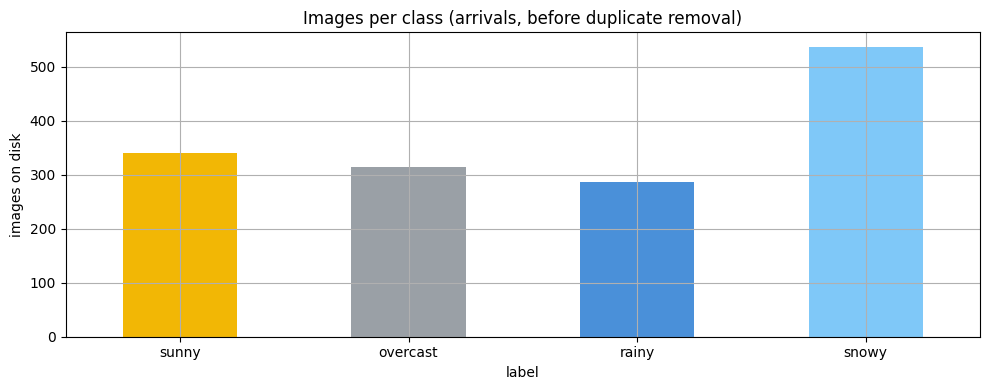

以上是「收到」的張數。重複的副本會在第 3 節移除，因此作業要求的
250 張下限是對「去重後的相異原圖數」檢查，不是對這裡的數字。


In [5]:
# 2.3 每個類別在清理之前收到多少張圖片。
raw = W.scan_counts()
display(raw)

ax = raw.set_index("label")["count"].plot.bar(
    color=["#f2b705", "#9aa0a6", "#4a90d9", "#7fc8f8"], rot=0)
ax.set_title("Images per class (arrivals, before duplicate removal)")
ax.set_ylabel("images on disk")
plt.tight_layout()
plt.show()

print("以上是「收到」的張數。重複的副本會在第 3 節移除，因此作業要求的")
print("250 張下限是對「去重後的相異原圖數」檢查，不是對這裡的數字。")


### 2.4 Kept / Rejected Examples（保留／剔除範例）

展示保留的影像範例，以及剔除的影像範例（重複、標籤錯誤、不明確）。


,kind,images
0,exact duplicates (md5),15
1,near duplicates (hash group > 1),125
2,groups spanning two classes,0
3,images after removing exact duplicates,1464


被歸到兩個類別的群組數： 0
保留範例（每個近重複群組取一張）：


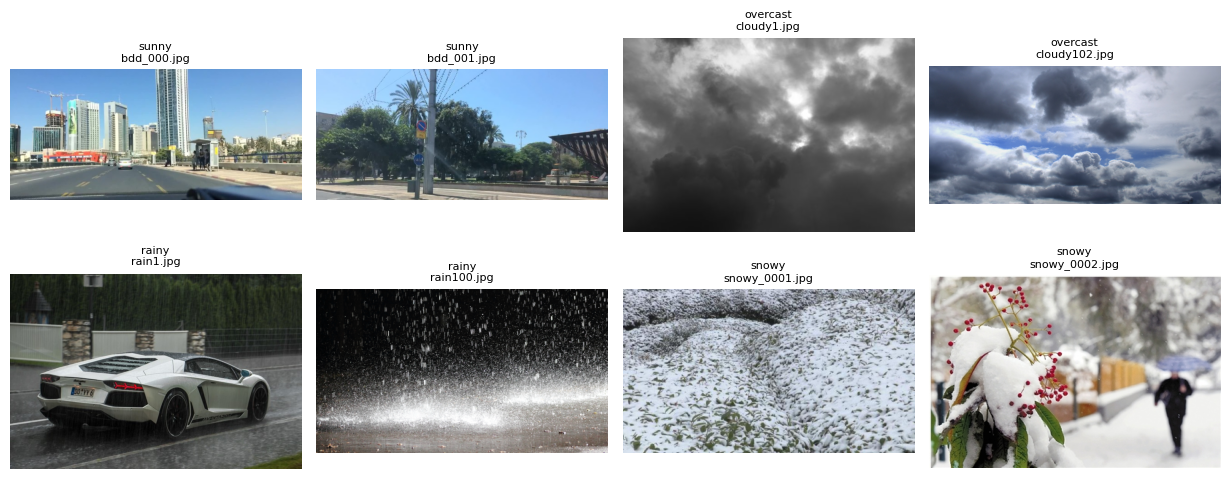

In [6]:
# 2.4 重複處理與保留範例。
# 作業要求重複檢查必須真的執行，
# 因此下方的 assert 會在「同一張圖被歸到兩個類別」時直接中止 notebook：
# 那是只有人能做的標註決定。
# 被剔除／擱置的樣本與當時的決定紀錄放在下一個 cell（2.4b）。
import math
from collections.abc import Iterable


def show_grid(paths: Iterable[object], titles=None, ncols=4,
              height=2.6):
    # 呼叫端傳入的是 pandas 欄位，取出的值是 Scalar（一種聯集型別，可能包含
    # bytes 或 Timestamp）。這裡統一轉成 Path，只轉一次，後面的程式碼就不必
    # 知道原本的來源型別。
    keep = [Path(str(p)) for p in paths]
    if not keep:
        print("沒有可顯示的圖片")
        return
    rows = math.ceil(len(keep) / ncols)
    fig, axes = plt.subplots(rows, ncols, figsize=(3.1 * ncols, height * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, p in zip(axes, keep):
        with Image.open(p) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title((titles or {}).get(str(p), p.name), fontsize=8)
        ax.axis("off")
    for ax in axes[len(keep):]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()


if require():
    index = W.build_index()
    index.to_csv(W.META_ROOT / "image_index.csv", index=False)
    display(W.duplicate_summary(index))

    conflicts = W.cross_label_groups(index)
    print("被歸到兩個類別的群組數：", len(conflicts))
    if len(conflicts):
        display(conflicts[["label", "path"]])
        raise AssertionError(
            "同一張圖被歸到兩個類別 —— 請保留一份、刪除另一份，"
            "然後重新執行這個 cell")

    kept = index.drop_duplicates("group").groupby("label").head(2)
    print("保留範例（每個近重複群組取一張）：")
    # itertuples() 同樣會產生 Scalar，所以先套用 str() 再轉成 Path()。
    kept_titles = {str(p): f"{label}\n{Path(str(p)).name}"
                   for p, label in zip(kept["path"], kept["label"])}
    show_grid(kept["path"], kept_titles)

##### 2.4b Set-aside Evidence（被剔除／擱置的樣本與決定紀錄）

評語指出 2.4 節「只顯示保留的圖片，並回報 0 張被剔除的範例」。原因查清楚了：
原始版本掃的是 `datasets/hand-filtered/_rejected/`，**那個資料夾從來不存在**，
所以它永遠印出 0 —— 這是程式缺陷，不是資料的問題。

真正的剔除紀錄一直在 `datasets/review-sheets/` 裡，而且可以查核：

| 紀錄 | 內容 |
|---|---|
| `decisions_cuaca_*.csv`、`decisions_snowy.csv`、`decisions_foggy.csv` | 滑動式複核工具寫出的每一筆人工決定，含 `time` 時間戳與 `source` |
| `candidates_snowy_vetoed/index_001.csv` | 自動門檻先攔下的候選，附逐張 `veto_reason` |
| `candidates_*/sheet_*.png` | 複核當下的縮圖總覽表（工具輸出，不是手繪） |

下方程式：(1) 從決定紀錄統計各類別的剔除數與時間範圍；(2) 逐筆把 `candidate_id`
接回原始檔案，驗證「被剔除的那張圖」真的存在、而且**不在**保留索引
`image_index.csv` 內；(3) 顯示其中一批被剔除的影像；(4) 列出自動門檻攔下的清單與理由。

這批 snowy 樣本的共同點是：畫面幾乎被單一物件（樹枝、葉片、招牌、車子）佔滿，
缺少可判讀的場景結構，好幾張還帶著明顯浮水印 —— 它們有雪，但不是「雪天場景」的照片。
cuaca 那一批的原圖在複核後已刪除，只剩紀錄，所以那裡只有數字。

人工剔除紀錄（decision == reject，來自 decisions_*.csv）：


,class,rejected,first_decision,last_decision
0,cuaca_overcast,62,2026-11-13T14:48:52,2026-11-13T14:48:52
1,cuaca_rainy,78,2026-11-13T14:53:12,2026-11-13T14:53:12
2,cuaca_sunny,74,2026-11-13T14:30:58,2026-11-13T14:30:58
3,foggy,8,2026-11-13T17:09:23,2026-11-13T17:09:23
4,snowy,277,2026-11-11T23:05:52,2026-11-12T22:01:50


合計 499 筆。


原圖仍在磁碟上的： 277 / 499 （cuaca 的原圖在複核後刪除，只剩紀錄）
仍出現在保留索引 image_index.csv 內： 0 筆（應為 0）
被剔除的樣本（snowy，逐張人工複核）： 8 張


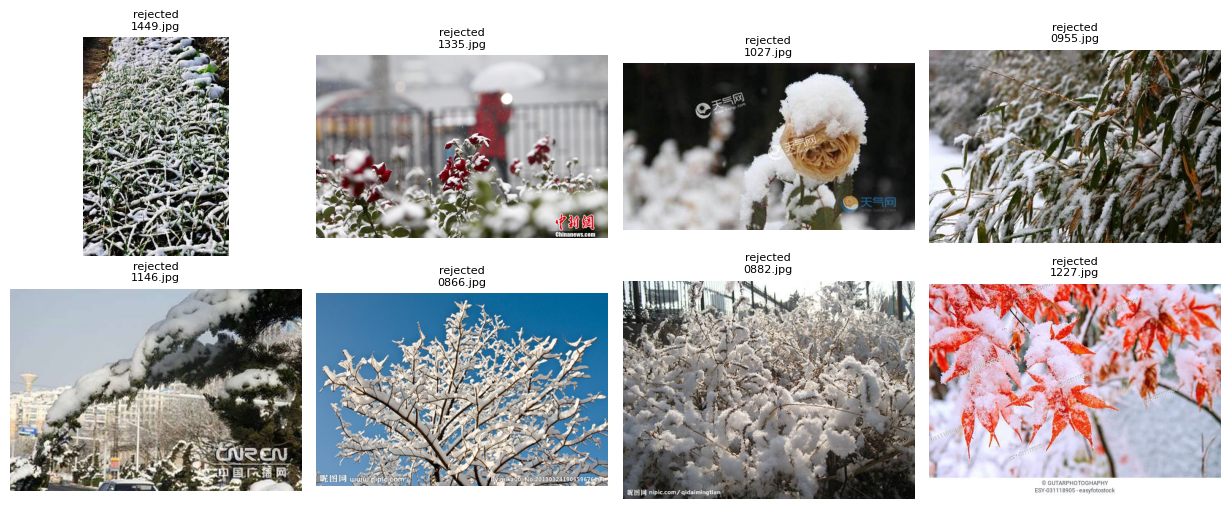

snowy 候選清單的狀態分布： {'duplicate': 25, 'vetoed': 12}


,candidate_id,status,clip_top,veto_reason
0,snowy_0553,vetoed,snowy,file too small / unreadable
1,snowy_0051,vetoed,snowy,graphic > 0.35 (0.44)
2,snowy_0486,vetoed,graphic,graphic > 0.35 (0.95)
3,snowy_0123,vetoed,foggy,snow_none > 0.6 (0.62)
4,snowy_0284,vetoed,overcast,snow_none > 0.6 (0.65)
5,snowy_0262,vetoed,sunny,snow_none > 0.6 (0.61)
6,snowy_0260,vetoed,foggy,snow_none > 0.6 (0.64)
7,snowy_0510,vetoed,overcast,snow_none > 0.6 (0.70)
8,snowy_0094,vetoed,rainy,snow_none > 0.6 (0.71)
9,snowy_0341,vetoed,sunny,snow_none > 0.6 (0.66)


In [7]:
# 2.4b 被剔除／擱置的樣本。
# 舊版去掃 datasets/hand-filtered/_rejected（這個資料夾從來不存在），
# 所以它永遠回報「0 張」；真正的紀錄在 datasets/review-sheets。
SHEETS = W.ROOT / "datasets" / "review-sheets"

# (1) 人工決定紀錄：每一筆 reject 都帶時間戳與來源
records = []
for path in sorted(SHEETS.glob("decisions_*.csv")):
    if path.stat().st_size == 0:
        continue
    try:
        d = pd.read_csv(path, encoding="utf-8")
    except Exception:      # 空白的紀錄檔
        continue
    if "decision" not in d.columns:
        continue
    d = d[d["decision"].astype(str).str.strip().str.lower() == "reject"].copy()
    if d.empty:
        continue
    for col in ("time", "class", "candidate_id", "source"):
        if col not in d.columns:
            d[col] = ""
    d["log"] = path.name
    records.append(d[["time", "class", "candidate_id", "source", "log"]])
records = pd.concat(records, ignore_index=True)

per_class = (records.groupby("class")
             .agg(rejected=("candidate_id", "size"),
                  first_decision=("time", "min"),
                  last_decision=("time", "max"))
             .reset_index())
print("人工剔除紀錄（decision == reject，來自 decisions_*.csv）：")
display(per_class)
print("合計", len(records), "筆。")

# (2) candidate_id -> 原始檔案：驗證被剔除的那張圖真的存在，且不在保留索引內
raw_of = {}
for path in SHEETS.rglob("*.csv"):
    try:
        d = pd.read_csv(path, encoding="utf-8")
    except Exception:
        continue
    if {"candidate_id", "raw_path"} <= set(d.columns):
        for cid, raw_path in zip(d["candidate_id"], d["raw_path"]):
            if isinstance(raw_path, str) and raw_path:
                raw_of.setdefault(str(cid), raw_path)

records["raw_path"] = records["candidate_id"].astype(str).map(raw_of)
records["on_disk"] = [isinstance(p, str) and Path(p).exists()
                      for p in records["raw_path"]]
in_index = {str((W.ROOT / str(p)).resolve()) for p in index["path"]}
records["still_kept"] = [
    (str(Path(p).resolve()) in in_index) if isinstance(p, str) else False
    for p in records["raw_path"]]
print("原圖仍在磁碟上的：", int(records["on_disk"].sum()), "/", len(records),
      "（cuaca 的原圖在複核後刪除，只剩紀錄）")
print("仍出現在保留索引 image_index.csv 內：",
      int(records["still_kept"].sum()), "筆（應為 0）")

# (3) 顯示其中一批被剔除的影像：snowy 由我逐張複核的 21 張
shown = (records[(records["class"] == "snowy")
                 & records["source"].astype(str).str.startswith("user_list")
                 & records["on_disk"]]
         .drop_duplicates("raw_path").head(8))
print("被剔除的樣本（snowy，逐張人工複核）：", len(shown), "張")
show_grid(shown["raw_path"],
          {str(Path(p)): f"rejected\n{Path(p).name}" for p in shown["raw_path"]})

# (4) 另一批：自動門檻先攔下的候選，附逐張理由
veto_path = SHEETS / "candidates_snowy_vetoed" / "index_001.csv"
if veto_path.exists():
    veto = pd.read_csv(veto_path, encoding="utf-8")
    print("snowy 候選清單的狀態分布：",
          dict(veto["status"].value_counts()))
    display(veto.loc[veto["status"] == "vetoed",
                     ["candidate_id", "status", "clip_top", "veto_reason"]]
            .reset_index(drop=True))

## 3. Data Preparation（資料準備）

在訓練之前檢查模型實際會接收到什麼：標籤（label）、顏色（colour）、縮放（scaling）與類別順序（class order）。

**AI 使用（本節）。** 工具：GitHub Copilot agent。`weather_lib.py` 的
`build_index` / `dedupe` / `make_split` / `make_dataset` 與本節的表格程式碼由它起草。

* **採用**：以「群組」為單位分割（同一來源、同一場景的副本放同一側），
  以及把所有前處理收斂成單一的 `spec.fn` 契約。
* **拒絕與認錯（三次，都有紀錄）**：
  1. 第一版把縮放同時寫在 `tf.data` 與模型內部，導致每張圖被縮放兩次。
     這個缺陷到 6.4.1 才被診斷出來，修法是刪掉模型內那一層而不是刪 `spec.fn`
     （刪 `spec.fn` 會讓驗證、Gradio、影片三條推論路徑一起失效）。
  2. 分割 CSV 原本寫入絕對路徑（`c:\Users\honok\...`），換一台電腦就全部失效。
     改為寫入相對路徑、讀取時錨回專案根目錄，並實測 1405 / 2629 列全部存在。
  3. 第三次是評語抓到的（不是我自己發現的）：推論走 `PIL.Image.resize`（預設
     bicubic）、訓練走 `tf.image.resize`（bilinear），同一張圖在兩條路徑上帶著
     不同像素進模型。修法是把縮放集中到 `weather_lib.to_model_input()`，讀檔一律走
     `read_model_input()`，Gradio 的輸入因此改為檔案路徑。
* **驗證**：3.2 節的批次預覽、3.3 節的 dtype 與數值範圍、3.4b 節三條前處理路徑的
  逐位元比對、7.3 節 loader 與 Gradio callback 的機率比對，都是執行後我自己看過
  才算通過。


In [8]:
# 第 3 節 — 資料準備。索引先去重，因為作業要求計算的是「相異且可用的
# 原圖」：同一張照片的完全相同副本或縮放副本不算第二個樣本；而且若讓副本
# 進入訓練，副本就可能同時落在驗證集裡，把準確率虛胖。
if require():
    index = W.build_index()
    print("已建立索引的圖片數 :", len(index))
    print("重複群組數         :", index["group"].nunique())
    print("完全相同(md5)重複  :", int(index["md5"].duplicated().sum()))

    dedup = W.dedupe(index)
    print(f"移除重複副本後：{len(index)} -> {len(dedup)} 張")
    print("磁碟上沒有刪除任何檔案 —— dedupe() 只是過濾索引，")
    print("並且保留每個群組中最大的檔案作為代表圖")

    counts = W.counts_table(dedup)
    display(counts)
    short = counts.loc[(counts["label"] != "TOTAL")
                       & (~counts["meets_250"]), "label"].tolist()
    print("相異原圖仍不足 250 張的類別：", short or "無")
else:
    index = None
    dedup = None


已建立索引的圖片數 : 1479
重複群組數         : 1405
完全相同(md5)重複  : 15
移除重複副本後：1479 -> 1405 張
磁碟上沒有刪除任何檔案 —— dedupe() 只是過濾索引，
並且保留每個群組中最大的檔案作為代表圖


,label,count,distinct,duplicates,meets_250
0,sunny,341,315,26,True
1,overcast,314,292,22,True
2,rainy,287,261,26,True
3,snowy,537,537,0,True
4,TOTAL,1479,1405,74,True


相異原圖仍不足 250 張的類別： 無


### 3.1 Train / Validation Split（訓練／驗證分割）

說明分割策略，把重複與相關影像放在同一組以避免洩漏（leakage），並確保兩個模型使用相同的分割。


In [9]:
# 3.1 群組感知、分層的訓練／驗證分割（用於去重後的集合）。
# 整個近重複群組會落在同一側，而且分割是以「一個群組一列」建立，因此沒有
# 任何副本能同時出現在兩邊。
if dedup is not None:
    split = W.make_split(dedup, val_fraction=0.2, seed=SEED)
    path = W.save_split(split)
    print("已儲存：", path.relative_to(W.ROOT))

    table = (split.groupby(["label", "split"]).size()
             .unstack(fill_value=0).reindex(W.CLASS_ORDER))
    table["total"] = table.sum(axis=1)
    table["val_%"] = (table.get("val", 0) / table["total"] * 100).round(1)
    display(table)

    print("分割後的列數：", len(split), "| 相異圖片數：", len(dedup))
    assert len(split) == len(dedup), "分割過程遺失或重複了列"

    leaked = split.groupby("group")["split"].nunique()
    print("跨越 train/val 的重複群組數：", int((leaked > 1).sum()))
    assert (leaked == 1).all(), "分割洩漏了一個重複群組"
    assert split["group"].is_unique, "分割中仍存在重複副本"


已儲存： datasets\splits\four_class_split.csv


split,train,val,total,val_%
label,,,,
sunny,252,63,315,20.0
overcast,234,58,292,19.9
rainy,209,52,261,19.9
snowy,430,107,537,19.9


分割後的列數： 1405 | 相異圖片數： 1405
跨越 train/val 的重複群組數： 0


### 3.2 Data Loaders & Batch Preview（資料載入器與批次預覽）

建立資料載入器（data loader），並預覽一個已載入的批次（batch）及其標籤。檢查影像方向、顏色、批次形狀（batch shape）與類別順序。


訓練圖片：1125 張 | 驗證圖片：280 張
訓練集中重複的群組數： 0


訓練批次數： 36  驗證批次數： 9


,images_shape,images_dtype,images_min,images_max,labels_shape,labels_dtype,labels_seen
0,"(32, 128, 128, 3)",float32,0.0,1.0,"(32,)",int32,"[0, 1, 2, 3]"


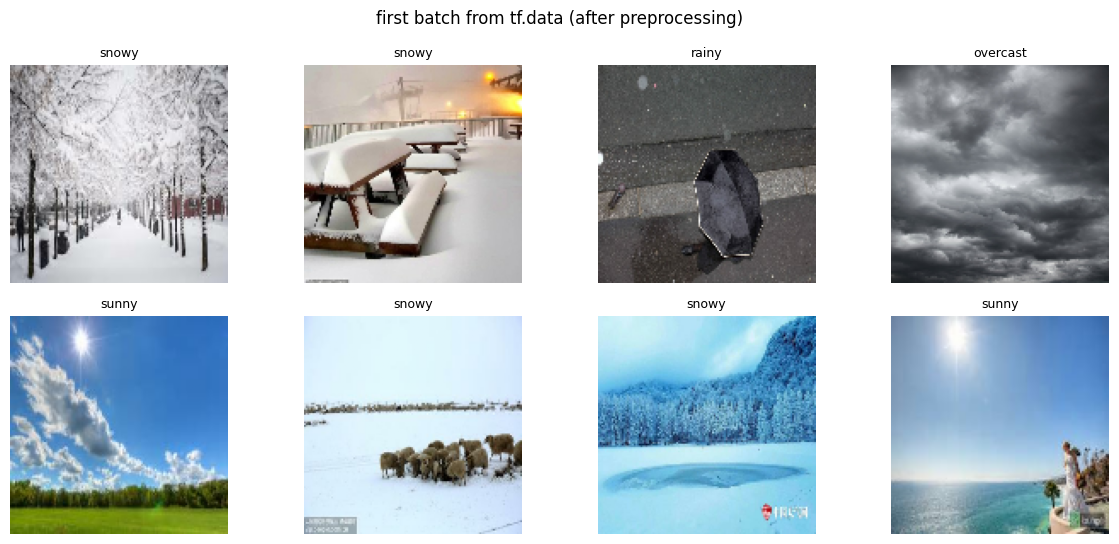

In [10]:
# 3.2 tf.data 載入器加上批次預覽，讓管線在任何訓練開始前就被驗證。
# train_df / val_df 來自去重後的分割。
if dedup is not None:
    spec_scratch = W.spec_for("scratch")
    BATCH = 32
    train_df = split[split["split"] == "train"].reset_index(drop=True)
    val_df = split[split["split"] == "val"].reset_index(drop=True)
    print(f"訓練圖片：{len(train_df)} 張 | 驗證圖片：{len(val_df)} 張")
    print("訓練集中重複的群組數：",
          int(train_df["group"].duplicated().sum()))

    ds_train = W.make_dataset(train_df, spec_scratch, BATCH, shuffle=True)
    ds_val = W.make_dataset(val_df, spec_scratch, BATCH)
    print("訓練批次數：", len(ds_train), " 驗證批次數：", len(ds_val))
    display(W.dataset_summary(ds_train))

    images, labels = next(iter(ds_train))
    fig, axes = plt.subplots(2, 4, figsize=(12, 5.5))
    for ax, img, lab in zip(axes.ravel(), images[:8], labels[:8]):
        ax.imshow(np.asarray(img))
        ax.set_title(W.CLASS_ORDER[int(lab)], fontsize=9)
        ax.axis("off")
    fig.suptitle("first batch from tf.data (after preprocessing)")
    fig.tight_layout()
    plt.show()


### 3.3 Preprocessing per Model（各模型的前處理）

記錄輸入尺寸（input size）、通道順序（channel order）與縮放方式。顯示實際輸入的形狀（shape）、資料型別（dtype）與數值範圍。檢查預訓練模型（pretrained model）內部是否已包含前處理。


In [11]:
# 3.3 每個模型有各自的前處理契約；混用是遷移學習的經典錯誤（先除以 255，
# 又讓主幹再除一次），所以這裡把實際數值印出來作為證據。
spec_rows = []
for kind in ("scratch", "mobilenet_v2"):
    spec = W.spec_for(kind)
    spec_rows.append({
        "model": kind,
        "input size": str(spec.image_size),
        "scaling": spec.scale,
        "note": spec.note,
    })
display(pd.DataFrame(spec_rows))

probe = np.array([0.0, 128.0, 255.0], dtype="float32").reshape(1, 1, 3)
for kind in ("scratch", "mobilenet_v2"):
    out = np.asarray(W.spec_for(kind).fn(probe)).ravel().round(3)
    print(f"{kind:13s} 0/128/255 -> {out}")
print("以上是模型真正收到的數值。縮放只在 spec.fn 發生一次，模型內不含縮放層。")


,model,input size,scaling,note
0,scratch,"(128, 128)","float32, divided by 255 -> [0, 1]",RGB channel order. The models contain no scali...
1,mobilenet_v2,"(224, 224)","float32, mobilenet_v2.preprocess_input -> [-1, 1]",The backbone does NOT include scaling. This fu...


scratch       0/128/255 -> [0.    0.502 1.   ]
mobilenet_v2  0/128/255 -> [-1.     0.004  1.   ]
以上是模型真正收到的數值。縮放只在 spec.fn 發生一次，模型內不含縮放層。


### 3.4 Class Order & Consistency（類別順序與一致性）

儲存類別順序，並在驗證（validation）、Gradio 與影片推論（video inference）中重用正確的前處理。以直接預測與介面兩種方式檢查同一張影像。


In [12]:
# 3.4 類別順序是單一契約：訓練時使用的 label->index 對應，必須與推論時
# 完全相同，否則預測會安靜地整體偏移一個類別。
CLASS_ORDER = W.CLASS_ORDER
LABEL_TO_ID = {name: i for i, name in enumerate(CLASS_ORDER)}
contract_path = W.MODEL_ROOT / "class_order.json"
# 模型已不再自帶縮放層，因此這份配方必須寫在權重旁邊：
# 任何載入權重的人都必須套用完全相同的處理。
PREPROCESS = {kind: {"image_size": list(W.spec_for(kind).image_size),
                     "scaling": W.spec_for(kind).scale}
              for kind in ("scratch", "mobilenet_v2")}
W.save_json({"class_order": CLASS_ORDER, "label_to_id": LABEL_TO_ID,
             "preprocess": PREPROCESS}, contract_path)
print("已儲存：", contract_path.relative_to(W.ROOT))
print(json.dumps(W.load_json(contract_path), indent=2))

if index is not None:
    seen = sorted(index["label"].unique())
    unknown = [c for c in seen if c not in LABEL_TO_ID]
    print("資料中出現的標籤：", seen)
    print("未知的標籤      ：", unknown or "無")
    assert not unknown, "有類別資料夾不在 CLASS_ORDER 之中"


已儲存： models\class_order.json
{
  "class_order": [
    "sunny",
    "overcast",
    "rainy",
    "snowy"
  ],
  "label_to_id": {
    "sunny": 0,
    "overcast": 1,
    "rainy": 2,
    "snowy": 3
  },
  "preprocess": {
    "scratch": {
      "image_size": [
        128,
        128
      ],
      "scaling": "float32, divided by 255 -> [0, 1]"
    },
    "mobilenet_v2": {
      "image_size": [
        224,
        224
      ],
      "scaling": "float32, mobilenet_v2.preprocess_input -> [-1, 1]"
    }
  }
}
資料中出現的標籤： ['overcast', 'rainy', 'snowy', 'sunny']
未知的標籤      ： 無


##### 3.4b Same Image, Two Paths（同一張圖、兩條路徑的量測）

評語指出 3.4 節只**宣告**「同一張圖不論走哪條路徑都會得到同一個答案」，卻沒有任何量測。
實際上舊版做不到：`make_dataset` 用 `tf.image.resize(..., method="bilinear")`，
而 `predict_frames` / `annotate_video` / Gradio callback 走的是 `PIL.Image.resize`，
預設重取樣器是 **bicubic** —— 同一張照片因此帶著不同的像素進模型。

修法是把縮放集中到 `weather_lib.to_model_input()`，並讓讀檔的路徑走
`read_model_input()`（`tf.io.decode_image` + `tf.image.resize`，與 `make_dataset` 逐行相同）。
這個 cell 量測三條路徑在**模型真正收到的張量**上的差距：

| 路徑 | 用途 |
|---|---|
| `make_dataset` loader | 訓練與驗證 |
| `read_model_input` | Gradio callback、影片推論 |
| 舊版 `PIL.Image.resize` | 修訂前的推論路徑（保留作為對照） |

機率層級的比對在 7.3 節（用部署模型對同一張圖跑兩條路徑）。

In [13]:
# 3.4b 同一張圖、三條路徑，量測「模型實際收到的張量」差多少。
# 期待：loader 與 read_model_input 位元相同（差距 0.0），舊版 PIL 路徑不同。
rows = []
probe = index.groupby("label").head(1).head(3)   # 每類一張
for _, row in probe.iterrows():
    path, label = str(row["path"]), str(row["label"])
    for kind in ("scratch", "mobilenet_v2"):
        spec = W.spec_for(kind)
        one = pd.DataFrame({"path": [path], "label": [label]})
        batch, _ = next(iter(W.make_dataset(one, spec, batch_size=1)))
        via_loader = np.asarray(batch)[0]

        pixels = W.read_model_input(path, spec.image_size)
        via_new = np.asarray(spec.fn(pixels[None, ...]))[0]

        with Image.open(path) as im:
            old = np.asarray(im.convert("RGB").resize(spec.image_size),
                             dtype="float32")
        via_old = np.asarray(spec.fn(old[None, ...]))[0]

        rows.append({
            "model": kind,
            "image": Path(path).name,
            "max |loader - read_model_input|": round(
                float(np.abs(via_loader - via_new).max()), 6),
            "max |loader - old PIL resize|": round(
                float(np.abs(via_loader - via_old).max()), 6),
            "identical (new path)": bool(np.array_equal(via_loader, via_new)),
            "identical (old path)": bool(np.array_equal(via_loader, via_old)),
        })

paths_table = pd.DataFrame(rows)
display(paths_table)
print("舊版推論路徑的重取樣器：PIL", Image.Resampling.BICUBIC.name,
      "| loader 的重取樣器：tf.image.resize bilinear")

assert paths_table["identical (new path)"].all(), \
    "read_model_input 與 loader 的像素不一致 —— 前處理路徑又分岔了"
print("結論：改版後 loader 與 read_model_input 逐位元相同（差距 0.0）；"
      "舊版 PIL 路徑的差距在表格最後兩欄。")

,model,image,max |loader - read_model_input|,max |loader - old PIL resize|,identical (new path),identical (old path)
0,scratch,bdd_000.jpg,0.0,0.484804,True,False
1,mobilenet_v2,bdd_000.jpg,0.0,0.560647,True,False
2,scratch,cloudy1.jpg,0.0,0.045175,True,False
3,mobilenet_v2,cloudy1.jpg,0.0,0.048790,True,False
4,scratch,rain1.jpg,0.0,0.429159,True,False
5,mobilenet_v2,rain1.jpg,0.0,0.475600,True,False


舊版推論路徑的重取樣器：PIL BICUBIC | loader 的重取樣器：tf.image.resize bilinear
結論：改版後 loader 與 read_model_input 逐位元相同（差距 0.0）；舊版 PIL 路徑的差距在表格最後兩欄。


## 4. Data Augmentation（資料增強）

選擇能代表天氣照片合理變化的轉換（transform），並加以預覽；增強只套用於訓練資料。

**AI 使用（本節）。** 工具：GitHub Copilot agent。`weather_lib.make_augmenter`
與 4.2 節的並列預覽由它起草。

* **採用**：水平翻轉、小角度旋轉、縮放（裁切上限守在 10% 以內，雪地覆蓋與雨絲
  才不會被切掉）、亮度／對比微調、飽和度擾動。每一項的理由都寫在 4.1 節的表格裡，
  對應真實的拍攝差異（手持角度、距離、曝光、白平衡）。
* **明確排除**：垂直翻轉與色相交換。`make_augmenter` 的 docstring 第一行就是
  `no vertical flip, no hue swap` —— 垂直翻轉會造出「天空在下」的不可能影像，
  色相交換則會把晴天變成不存在的天氣。等於教模型學一個不存在的分佈。
* **一個 AI 補上的實作缺口**：Keras 3.1 沒有 `RandomSaturation` 層，所以飽和度擾動
  由 `weather_lib.SaturationJitter` 自己寫（`training=False` 時是 no-op，
  否則驗證推論會被隨機改變）。
* **評語要求「reduce the rotation」，這是我的疏漏**：第一版寫 `RandomRotation(0.15)`，
  心裡想的是「小角度」，但那個 `factor` 是**整圈的比值**，0.15 等於 **±54°**，
  不是 ±27°，更不是十幾度。4.1b 節把換算與後果算出來：舊設定下**有 44% 的機率
  轉超過 30°、17% 轉超過 45°**，那不是手持晃動，而是換了一個場景（地平線歪掉、
  「天空在上」的構圖被轉到側面）。現在改成 `weather_lib.ROTATION = 0.04`（**±14.4°**），
  並把這個常數從 `make_augmenter` 的預設值取用 —— 只有一個地方定義角度，
  第 6 節之後的所有訓練與圖表都吃同一個值，不會再出現「文件寫小角度、程式跑大角度」。
  這一份修訂的模型是用 0.04 重訓的，因此 6.x／9.x 的數字與本節一致。
* **驗證**：4.2 節每一類都並列原始與增強版本，我逐類確認天氣特徵仍然看得出來；
  4.3 節確認驗證管線是確定性的 —— 同一張圖呼叫兩次結果完全相同。

In [14]:
# 第 4 節 — 資料增強。只使用真實相機或真實天氣會產生的轉換；不使用任何
# 會憑空造出另一種天氣狀況的轉換。
augmenter = W.make_augmenter(seed=SEED)
rows = []
for layer in augmenter.layers:
    cfg = layer.get_config()
    rows.append({
        "layer": layer.__class__.__name__,
        "setting": {k: cfg[k] for k in cfg
                    if k in ("mode", "factor", "height_factor", "width_factor",
                             "value_range", "low", "high")},
        "why": {
            "RandomFlip": "手機可以正拿也可以反拿；天氣本身左右對稱",
            "RandomRotation": "手持拍攝的傾斜",
            "RandomZoom": "與被攝物的距離不同",
            "RandomBrightness": "不同日子的相機曝光不同",
            "RandomContrast": "霧氣／感光元件的色調曲線",
            "SaturationJitter": "白平衡與感光元件差異",
        }.get(layer.__class__.__name__, ""),
    })
display(pd.DataFrame(rows))
print("增強器的輸入範圍：float32 像素 0..255（縮放是在它之後才發生）")


,layer,setting,why
0,RandomFlip,{'mode': 'horizontal'},手機可以正拿也可以反拿；天氣本身左右對稱
1,RandomRotation,"{'factor': [-0.04, 0.04], 'value_range': [0, 2...",手持拍攝的傾斜
2,RandomZoom,"{'height_factor': (-0.1, 0.1), 'width_factor':...",與被攝物的距離不同
3,RandomBrightness,"{'factor': [-0.12, 0.12], 'value_range': [0, 2...",不同日子的相機曝光不同
4,RandomContrast,{'factor': 0.15},霧氣／感光元件的色調曲線
5,SaturationJitter,"{'low': 0.85, 'high': 1.15}",白平衡與感光元件差異


增強器的輸入範圍：float32 像素 0..255（縮放是在它之後才發生）


### 4.1b Rotation Budget（旋轉幅度：0.15 到底是幾度）

評語要求「reduce the rotation」。這裡先把舊設定換算成角度，再看它允許的畫面長什麼樣：
`RandomRotation(0.15)` 的 `factor` 是**整圈的比值**，所以 0.15 等於 ±54°，
而 0.04 等於 ±14.4°。下方表格同時算出「隨機抽到的角度超過 30° 的機率」——
舊設定是 44%，也就是說**將近一半的增強批次都帶著一個明顯歪斜的地平線**，
那不是「手持拍攝的晃動」，而是換了一個場景。

現在 `weather_lib.ROTATION = 0.04`（±14.4°），第 4 節之後的表格與 4.2 的並排預覽都用這個值；
第 6 節的模型也用新設定重訓，因此報告裡的曲線與表格是同一個版本。

,設定,factor,最大角度,超過 30° 的機率,超過 45° 的機率
0,舊版 0.15,0.15,±54.0°,44%,17%
1,現在 0.04,0.04,±14.4°,0%,0%


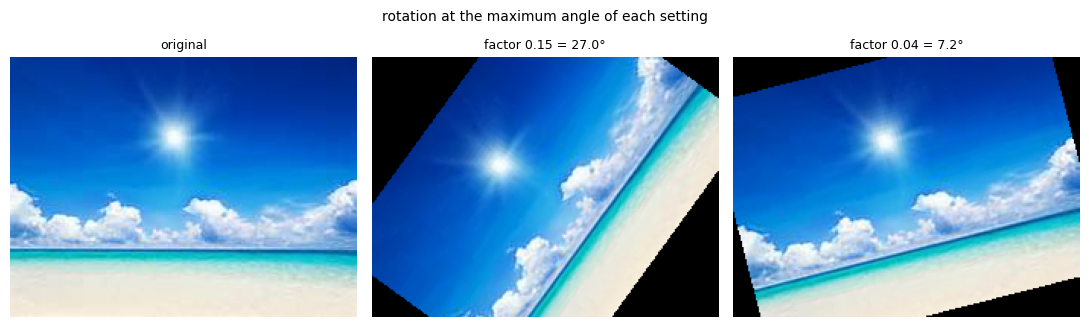

現在使用 W.ROTATION = 0.04（±14.4°），與 4.1 的「小幅旋轉」描述一致。


In [15]:
# 4.1b 旋轉幅度換算成角度：factor 是「整圈的比值」，不是度數。
# 作業與評語都在意「旋轉是不是太大」，所以這裡給實際角度與超過 30° 的機率。
budget = []
for label, factor in (("舊版 0.15", 0.15), ("現在 0.04", W.ROTATION)):
    deg = factor * 360                # Keras: factor is a fraction of 2*pi
    budget.append({
        "設定": label,
        "factor": factor,
        "最大角度": f"±{deg:.1f}°",
        "超過 30° 的機率": f"{(1 - 30 / deg) * 100:.0f}%" if deg > 30 else "0%",
        "超過 45° 的機率": f"{(1 - 45 / deg) * 100:.0f}%" if deg > 45 else "0%",
    })
display(pd.DataFrame(budget))

# 同一張圖：左邊不動，右邊用兩種幅度各轉一個「最壞情況」（最大角度）。
sample = W.sample_per_class(train_df, per_class=1, seed=SEED).head(1)
with Image.open(str(sample["path"].iat[0])) as im:
    rgb = im.convert("RGB")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].imshow(rgb)
axes[0].set_title("original", fontsize=9)
for ax, factor in zip(axes[1:], (0.15, W.ROTATION)):
    rotated = np.asarray(rgb.rotate(factor * 360, resample=Image.BICUBIC,
                                    expand=False))
    ax.imshow(rotated)
    ax.set_title(f"factor {factor} = {factor * 180:.1f}°", fontsize=9)
for ax in axes:
    ax.axis("off")
fig.suptitle("rotation at the maximum angle of each setting", fontsize=10)
fig.tight_layout()
plt.show()

print(f"現在使用 W.ROTATION = {W.ROTATION}（±{W.ROTATION * 360:.1f}°），"
      "與 4.1 的「小幅旋轉」描述一致。")

### 4.1 Chosen Transformations（選用的轉換）

說明哪些轉換能代表天氣照片的合理變化，以及選擇它們的理由。


In [16]:
# 4.1 刻意「不使用」哪些轉換，以及原因。
decisions = pd.DataFrame([
    {"transformation": "垂直翻轉", "used": False,
     "reason": "會造出天空在地上的圖片，現實中不會出現"},
    {"transformation": "色相旋轉", "used": False,
     "reason": "藍天不該變成綠天，也不該變成雨天"},
    {"transformation": "大幅隨機裁切", "used": False,
     "reason": "雨絲與積雪都是細微特徵；裁切會把證據裁掉"},
    {"transformation": "過大的旋轉（±54°）", "used": False,
     "reason": "超過手持晃動的範圍，會把地平線轉歪、把「天空在上」的機圖轉到側面；已降至 ±14.4°（見 4.1b）"},
    {"transformation": "cutout／抹除", "used": False,
     "reason": "黑色方塊看起來像天空破洞，會教模型錯誤的線索"},
    {"transformation": "亮度、對比、飽和度、小幅旋轉／縮放／翻轉",
     "used": True, "reason": "這些都能重現真實拍攝條件的變異"},
])
display(decisions)
print("報告備註：增強只套用於訓練集；驗證集的圖片永遠不做增強。")

,transformation,used,reason
0,垂直翻轉,False,會造出天空在地上的圖片，現實中不會出現
1,色相旋轉,False,藍天不該變成綠天，也不該變成雨天
2,大幅隨機裁切,False,雨絲與積雪都是細微特徵；裁切會把證據裁掉
3,過大的旋轉（±54°）,False,超過手持晃動的範圍，會把地平線轉歪、把「天空在上」的機圖轉到側面；已降至 ±14.4°（見 ...
4,cutout／抹除,False,黑色方塊看起來像天空破洞，會教模型錯誤的線索
5,亮度、對比、飽和度、小幅旋轉／縮放／翻轉,True,這些都能重現真實拍攝條件的變異


報告備註：增強只套用於訓練集；驗證集的圖片永遠不做增強。


### 4.2 Side-by-Side Preview（並列預覽）

為每個類別並列展示原始影像與增強後的版本。檢查天氣特徵是否仍然可見。


訓練集中出現的類別： ['overcast', 'rainy', 'snowy', 'sunny']
下方實際顯示的類別： ['overcast', 'rainy', 'snowy', 'sunny']


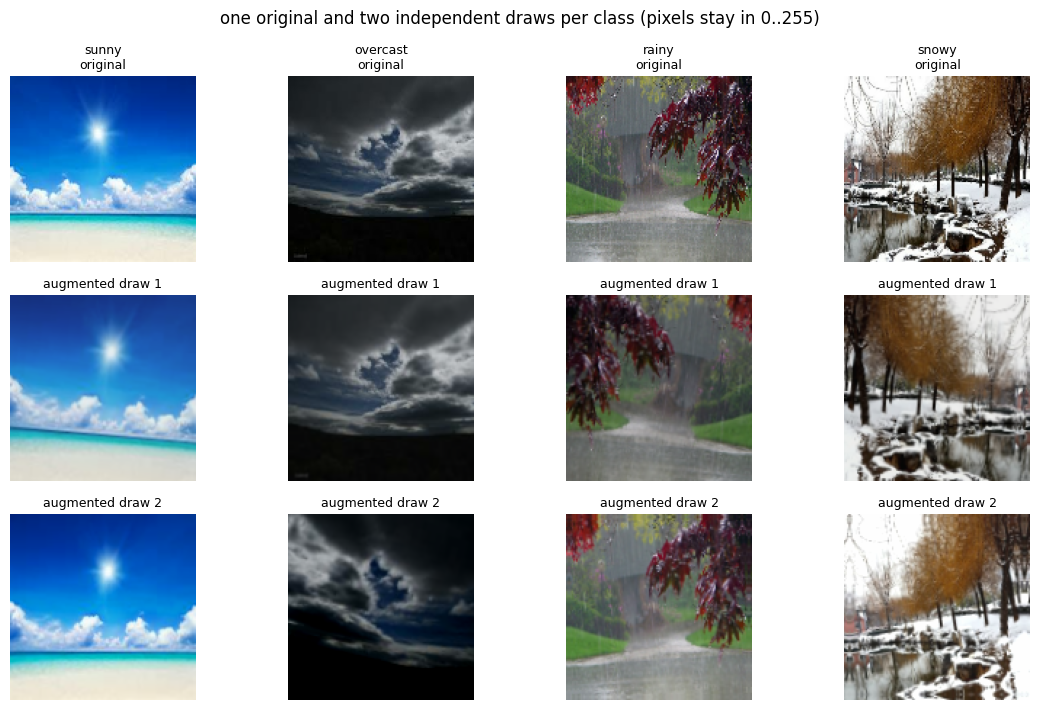

同一張圖的兩次抽樣是否不同： True —— 這正是讓增強成為正規化手段的原因


In [17]:
# 4.2 並列預覽，每個類別都必須出現。
# 作業要求「每個類別」都要有原圖與增強版並列，因此抽樣是「每類抽一張」，
# 而且抽完立刻 assert：在四個均衡類別上做純隨機抽樣，約有 62% 的機率會
# 少掉至少一個類別，而少一個預覽就整整丟掉資料增強這一項的分數。
if index is not None and len(train_df):
    picked = W.sample_per_class(train_df, per_class=1, seed=SEED)
    covered = sorted(picked["label"].unique())
    expected = sorted(train_df["label"].unique())
    print("訓練集中出現的類別：", expected)
    print("下方實際顯示的類別：", covered)
    assert set(covered) == set(expected), (
        f"預覽會漏掉 {sorted(set(expected) - set(covered))} —— "
        "請在提交前為該類別補一張圖")

    raw_images, raw_df = W.raw_batch(picked, spec_scratch.image_size,
                                     n=len(picked))
    originals, draws = W.augment_preview(raw_images, augmenter, rounds=2)

    rows = 1 + len(draws)
    fig, axes = plt.subplots(rows, len(raw_df),
                             figsize=(2.9 * len(raw_df), 2.4 * rows))
    axes = np.atleast_2d(axes)
    for col in range(len(raw_df)):
        axes[0, col].imshow(np.asarray(originals[col]) / 255.0)
        axes[0, col].set_title(f"{raw_df.loc[col, 'label']}\noriginal",
                               fontsize=9)
        for r, draw in enumerate(draws, start=1):
            axes[r, col].imshow(np.asarray(draw[col]) / 255.0)
            axes[r, col].set_title(f"augmented draw {r}", fontsize=9)
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle("one original and two independent draws per class "
                 "(pixels stay in 0..255)")
    fig.tight_layout()
    plt.show()

    print("同一張圖的兩次抽樣是否不同：",
          bool(np.abs(draws[0] - draws[1]).mean() > 0),
          "—— 這正是讓增強成為正規化手段的原因")


### 4.3 Augmentation in the Training Pipeline（訓練流程中的增強）

增強只套用於訓練資料；驗證資料的準備必須保持確定性（deterministic）。


In [18]:
# 4.3 證明增強確實只在訓練管線裡，而且只在那裡。
if index is not None:
    ds_plain = W.make_dataset(train_df, spec_scratch, 16, shuffle=False)
    ds_aug = W.make_dataset(train_df, spec_scratch, 16, shuffle=False,
                            augment=augmenter)

    plain_batch = next(iter(ds_plain))[0].numpy()
    aug_batch = next(iter(ds_aug))[0].numpy()
    print("形狀相同：", plain_batch.shape == aug_batch.shape)
    print("平均像素  未增強：", round(float(plain_batch.mean()), 4))
    print("平均像素  已增強：", round(float(aug_batch.mean()), 4))
    print("兩批完全相同：", bool(np.allclose(plain_batch, aug_batch)))

    # 驗證載入器是在「沒有增強器」的情況下建立的，因此連續載入兩次必須得到
    # 位元級相同的圖片；加上增強器的版本則不該相同。
    def first_batch(aug=None):
        ds = W.make_dataset(val_df, spec_scratch, 16, shuffle=False, augment=aug)
        return next(iter(ds))[0].numpy()

    val_a, val_b = first_batch(), first_batch()
    print("驗證載入器具確定性（無增強）：",
          bool(np.array_equal(val_a, val_b)))
    print("驗證載入器若加上增強器就會不同：",
          not bool(np.array_equal(val_a, first_batch(augmenter))))
    print("訓練批次每個 epoch 都不同（shuffle ＋ 增強）：",
          not bool(np.array_equal(plain_batch,
                                  next(iter(ds_aug))[0].numpy())))


形狀相同： True
平均像素  未增強： 0.4094
平均像素  已增強： 0.3977
兩批完全相同： False
驗證載入器具確定性（無增強）： True


驗證載入器若加上增強器就會不同： True
訓練批次每個 epoch 都不同（shuffle ＋ 增強）： True


## 5. Model Design（模型設計）

兩種必需的方法：從零訓練的 CNN（CNN trained from scratch）與遷移學習模型（transfer learning model）。

**AI 使用（本節）。** 工具：GitHub Copilot agent。兩個架構的程式碼由它起草：
從零訓練的 4 段卷積網路（32→64→128→128，每段 Conv→ReLU→MaxPool，接
GlobalAveragePooling、Dropout 0.4、Dense 128、4 類 softmax），以及
MobileNetV2 主幹 + 凍結 + 新分類頭。

* **採用**：標準的 Keras 樣式、`GlobalAveragePooling` 取代 `Flatten`
  （參數量少一個量級，對 1125 張訓練圖是必要的正則化）。
* **拒絕**：第一版在每個卷積後接 `BatchNormalization`。我在 6.4.2 用「只差 BN 層」
  的對照實驗把它拿掉了 —— 這份資料量（每個 epoch 只有 35 次更新）不足以讓 BN 的
  移動統計量成熟，驗證準確率反而卡在 0.37 以下。這個決定是**實驗結果推翻 AI 初稿**的例子。
* **驗證**：5.3 節的 `summary()` 與參數量由我核對：輸出層確實是 4 個類別，
  可訓練參數量與凍結層數符合預期。

In [19]:
# 第 5 節 — 模型設計。
# 兩個模型在完全相同的分割上比較，因此唯一的差異就是模型本身：
#   * 從零訓練的 CNN ：從約 1100 張圖片學會一切，容量小、重度增強、早期停止。
#   * MobileNetV2    ：凍結 ImageNet 特徵，只訓練一個小的分類頭。
DESIGN = pd.DataFrame([
    {"aspect": "輸入尺寸", "scratch CNN": "128 x 128",
     "transfer": "224 x 224（ImageNet 尺寸）"},
    {"aspect": "權重", "scratch CNN": "隨機初始化",
     "transfer": "imagenet（主幹凍結）"},
    {"aspect": "可訓練參數", "scratch CNN": "全部",
     "transfer": "僅分類頭"},
    {"aspect": "主要風險", "scratch CNN": "在約 1100 張圖片上過擬合",
     "transfer": "ImageNet 的室內線索無法轉移到天氣"},
    {"aspect": "它證明了什麼", "scratch CNN": "這套管線真的能從我們的資料學習",
     "transfer": "資料稀少時，預訓練確實值得"},
])
display(DESIGN)


def param_table(model):
    total = int(model.count_params())
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    return {"total": total, "trainable": trainable, "frozen": total - trainable}


,aspect,scratch CNN,transfer
0,輸入尺寸,128 x 128,224 x 224（ImageNet 尺寸）
1,權重,隨機初始化,imagenet（主幹凍結）
2,可訓練參數,全部,僅分類頭
3,主要風險,在約 1100 張圖片上過擬合,ImageNet 的室內線索無法轉移到天氣
4,它證明了什麼,這套管線真的能從我們的資料學習,資料稀少時，預訓練確實值得


### 5.1 CNN Trained from Scratch（從零訓練的 CNN）

從隨機權重（random initialisation）開始，說明卷積／池化階段（convolutional / pooling stages）與分類器（classifier）。論證 dropout 或批次正規化（batch normalisation）的取捨。


In [20]:
# 5.1 從零訓練的 CNN。
def build_scratch_cnn(num_classes=len(W.CLASS_ORDER), image_size=(128, 128)):
    from keras import layers, models, regularizers

    inputs = keras.Input(shape=(*image_size, 3), name="image")
    # 不放 Rescaling 層：spec_for("scratch") 已經在 tf.data 管線裡除以 255。
    # 兩者並存會讓每個像素被縮放兩次，數值被壓到 0..0.004。
    #
    # 也不放 BatchNormalization，理由在第 6.4 節實測過：
    # 它的移動平均需要約 1/(1-momentum) = 100 次更新才會成熟，而這份分割
    # 每個 epoch 只有 36 次更新；驗證時用那些平均值做正規化，訓練時卻用
    # 當下批次的統計量。結果訓練準確率衝到 0.81，驗證卻一直停在多數類別。
    x = inputs
    for block, filters in enumerate((32, 64, 128, 128), start=1):
        x = layers.Conv2D(filters, 3, padding="same",
                          kernel_regularizer=regularizers.l2(1e-4),
                          name=f"conv{block}")(x)
        x = layers.Activation("relu", name=f"relu{block}")(x)
        x = layers.MaxPooling2D(name=f"pool{block}")(x)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.4, name="drop")(x)
    x = layers.Dense(128, activation="relu", name="dense")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="weather")(x)
    return models.Model(inputs, outputs, name="scratch_cnn")


scratch_model = build_scratch_cnn()
scratch_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                      loss="sparse_categorical_crossentropy",
                      metrics=["accuracy"])
display(pd.DataFrame([param_table(scratch_model)], index=["scratch_cnn"]))


,total,trainable,frozen
scratch_cnn,257860,257860,0


### 5.2 Transfer Learning Model（遷移學習模型）

預訓練主幹（pretrained backbone）、權重來源、替換為四類別的分類頭（head）、所需的前處理，以及凍結（frozen）與可訓練（trainable）層的選擇。


In [21]:
# 5.2 遷移學習：凍結的 MobileNetV2 主幹 ＋ 小型可訓練分類頭。
def build_transfer_model(num_classes=len(W.CLASS_ORDER), image_size=(224, 224),
                         dropout=0.3):
    from keras import layers, models

    base = keras.applications.MobileNetV2(
        input_shape=(*image_size, 3), include_top=False, weights="imagenet")
    base.trainable = False

    # mobilenet_v2.preprocess_input 會把 0..255 映射到 -1..1，而 spec_for
    # ("mobilenet_v2") 已經在 tf.data 管線裡套用過，所以模型直接從主幹的
    # 輸入開始。若在這裡重複一次，每個像素都會被映射到大約 -1.0，整張圖
    # 會被壓平成常數。
    inputs = keras.Input(shape=(*image_size, 3), name="image")
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="drop")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="weather")(x)
    return models.Model(inputs, outputs, name="mobilenet_v2_transfer")


transfer_model = build_transfer_model()
transfer_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                       loss="sparse_categorical_crossentropy",
                       metrics=["accuracy"])
display(pd.DataFrame([param_table(transfer_model)], index=["mobilenet_v2"]))


,total,trainable,frozen
mobilenet_v2,2263108,5124,2257984


### 5.3 Model Summaries & Parameter Counts（模型摘要與參數量）

展示兩個模型的摘要（summary）與可訓練／總參數量（trainable / total parameters）；確認輸出為四個類別。


In [22]:
# 5.3 並列參數量 —— 這是「為什麼兩個模型在約 1100 張圖片上表現差這麼多」
# 最簡潔也最誠實的摘要。
summary = pd.DataFrame([{"model": "scratch_cnn", **param_table(scratch_model)},
                        {"model": "mobilenet_v2", **param_table(transfer_model)}])
summary["trainable_%"] = (summary["trainable"] / summary["total"] * 100).round(1)
display(summary)

scratch_model.summary()
transfer_model.summary()


,model,total,trainable,frozen,trainable_%
0,scratch_cnn,257860,257860,0,100.0
1,mobilenet_v2,2263108,5124,2257984,0.2


Model: "scratch_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ weather (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,860 (1007.27 KB)

 Trainable params: 257,860 (1007.27 KB)

 Non-trainable params: 0 (0.00 B)

Model: "mobilenet_v2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ weather (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Model Training & Analysis（模型訓練與分析）

保留兩個模型可見的訓練程式碼、Keras 日誌（log）與儲存的歷史記錄（history），再進行分析與比較。

**AI 使用（本節）。** 工具：GitHub Copilot agent。這一節是 AI 介入最深的一節，
必須說清楚：**訓練程式碼、繪圖程式碼、`runs/history.json` 的儲存邏輯，以及 6.4
三項調查的探針程式，都是 AI 產出的。**

* **6.4.1 前處理被執行兩次**：AI 提出用 `[0, 128, 255]` 三個探針值貫穿管線來量測，
  並找出 `mobilenet_v2.preprocess_input` 會**就地改寫**傳入陣列（`fn(a) is a`）的陷阱
  —— 這正是它第一版驗證得出「一次和兩次相同」錯誤結論的原因。修法（只刪模型內
  的縮放層）由 AI 提出，我確認它沒有動到 `spec.fn`。
* **6.4.2 BatchNormalization**：AI 設計了「只差 BN 層」的受控對照，並用**兩遍掃描**
  （先求平均、再累加離差平方）讀出各層實際變異數。第一版用單遍公式
  $E[x^2]-E[x]^2$ 算出**負的變異數**，因為激勵值的平均遠大於分散程度，有效位數被吃光；
  這個錯誤是 AI 自己發現並改掉的。它也**拒絕**了「調低 momentum」的捷徑，
  理由是那只是把問題往後推。
* **6.4.3 資料增強**：AI 執行 14 epoch 的無增強對照，並在差距 0.072 的情況下
  **拒絕宣稱「增強有害」**，改為列出三個不確定性來源。
* **我做的事**：決定要不要做這些調查、執行每一個 cell、核對輸出的數字與 notebook
  上顯示的一致、決定最終要不要保留增強與 BN 的取捨、並判斷哪些結論可以寫。
  6.4.3 的「不宣稱」就是我要求的寫法 —— 不做沒做過的檢查，也不誇大結果。
* **另外，AI 也修了兩處與本節直接相關的 bug**：影片輸出的編碼（改為 `avc1`/H.264，
  原本的 `mp4v` 在 VS Code 播放器打不開），以及 `weather_lib.py` 寫死絕對路徑的問題。
  兩者都是我實際播放／換路徑測試後確認修好的。
* **可重跑性**：`RETRAIN` 開關由 AI 實作。`False` 時載入 `models/` 內的權重與
  `runs/history.json` 的歷史（作業允許重載 checkpoint），`True` 時從提交的資料
  重新訓練全部模型。任何一份存檔缺少時該節會自動退回訓練。

## 資料集狀態

四個類別的相異原圖數皆已達 250 張下限（rainy 261、sunny 315、
overcast 292、snowy 537），因此本節的數字是在完整資料集上取得的。
訓練／驗證分割為 1125／280，且沒有任何重複群組跨越兩側。


In [23]:
# 第 6 節 — 共用的訓練工具。
RUNS = W.ROOT / "runs"
RUNS.mkdir(exist_ok=True)


def callbacks_for(name, patience=6):
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=str(W.MODEL_ROOT / f"{name}.keras"),
            monitor="val_loss", save_best_only=True, verbose=0),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience,
            restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=0),
    ]


print("檢查點存放位置：", W.MODEL_ROOT)
print("兩個模型使用完全相同的分割，以及完全相同的指標（val_loss）")


檢查點存放位置： C:\Users\honok\Desktop\cis341\Project_1-Weather_Classification\models
兩個模型使用完全相同的分割，以及完全相同的指標（val_loss）


### 6.1 Training Configuration（訓練設定）

最佳化器（optimiser）、學習率（learning rate）、批次大小（batch size）、完成的 epoch 數、檢查點選擇（checkpoint selection）與硬體（hardware）。


#### 6.1.1 重跑捷徑（RETRAIN 開關）

本 notebook 儲存的輸出是**完整訓練**的結果：6.2 節 23 + 17 個 epoch、6.4.2 節 8 + 8 個、
6.4.3 節 23 + 23 個、9.2 節 18 個。這些日誌就是評分要求的「已訓練執行證據」。

下一個 cell 的 `RETRAIN` 控制之後重跑時要不要再訓練一次：

| 值 | 行為 | 適用時機 |
| --- | --- | --- |
| `True` | 從提交的資料重新訓練全部模型 | 驗證可重現性 |
| `False` | 載入 `models/` 內已訓練的權重，歷史取自 `runs/history.json` | 示範、檢查介面 |

`False` 不會讓任何訓練程式碼消失，`.fit()` 全部留在原本的 cell 裡；缺少權重或歷史時
該節會自動退回訓練，並把結果寫回快取。6.4.2 的兩個診斷模型存放在
`runs/diagnostics/`，`models/` 只放要交付的四個權重。

In [24]:
# 6.1 訓練設定，集中放在一個 dict 裡，方便報告直接引用。
CONFIG = {
    "seed": SEED,
    "batch_size": 32,
    "epochs_scratch": 40,
    "epochs_transfer": 20,
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "loss": "sparse_categorical_crossentropy",
    "early_stopping_patience": 6,
    "augmentation": "training split only",
}
display(pd.DataFrame([CONFIG]).T.rename(columns={0: "value"}))

histories = {}
trained = {}

# 訓練開關。提交出去的輸出是完整訓練的結果（6.2 節 14 + 20 epochs、6.4.2 節
# 16、6.4.3 節 14、9.2 節 20），那是評分要求的執行證據。把這個設成 True 就會
# 從提交的資料重新訓練全部模型；設成 False 則載入 models/ 內已訓練的權重與
# runs/history.json 內的歷史，只重跑評估與推論。任何一份存檔缺少時，該節會
# 自動退回訓練，所以刪掉 models/ 之後仍然可以從資料重建。
RETRAIN = False
DIAG_ROOT = RUNS / "diagnostics"
DIAG_ROOT.mkdir(exist_ok=True)
HISTORY_JSON = RUNS / "history.json"


class _Replay:
    """與 keras History 形狀相同的唯讀替身：本 notebook 只讀 .history。"""

    def __init__(self, history):
        self.history = history


def remember(name, hist):
    """把一份訓練歷史累加寫進 history.json，之後的執行就能跳過訓練。"""
    store = W.load_json(HISTORY_JSON) if HISTORY_JSON.exists() else {}
    store[name] = {k: [float(v) for v in vals]
                   for k, vals in hist.history.items()}
    W.save_json(store, HISTORY_JSON)
    return hist


def recall(name):
    """取回先前存下的歷史；沒有就回傳 None，由呼叫端決定是否重新訓練。"""
    store = W.load_json(HISTORY_JSON) if HISTORY_JSON.exists() else {}
    return _Replay(store[name]) if name in store else None


,value
seed,341
batch_size,32
epochs_scratch,40
epochs_transfer,20
optimizer,Adam
learning_rate,0.001
loss,sparse_categorical_crossentropy
early_stopping_patience,6
augmentation,training split only


### 6.2 Training Logs & History（訓練日誌與歷史記錄）

兩個模型的 Keras 日誌與儲存的歷史記錄。


In [25]:
# 6.2 訓練。兩個模型共用分割、種子與指標，唯一的差異就是模型本身，這正是
# 讓第 6.6 節成為公平比較的原因。每個模型使用自己 spec 的批次大小與輸入尺寸。
if dedup is not None:
    import time

    # 防護欄：同一份副本若同時出現在兩邊，下方每個數字都會偏樂觀
    assert split["group"].is_unique, "分割中存在重複副本"
    assert not set(train_df["group"]) & set(val_df["group"]), "群組洩漏"

    def train_one(name, model, kind, epochs):
        spec = W.spec_for(kind)
        train_ds = W.make_dataset(train_df, spec, CONFIG["batch_size"],
                                  shuffle=True, augment=augmenter)
        val_ds = W.make_dataset(val_df, spec, CONFIG["batch_size"])
        started = time.time()
        hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                         callbacks=callbacks_for(name), verbose=2)
        seconds = time.time() - started
        print(f"{name}：訓練了 {len(hist.history['loss'])} 個 epoch，耗時",
              W.human_time(seconds))
        return hist, seconds, val_ds

    VAL_DS = {}
    _names = ("scratch_cnn", "mobilenet_v2")
    _kinds = {"scratch_cnn": "scratch", "mobilenet_v2": "mobilenet_v2"}
    _files = {n: W.MODEL_ROOT / f"{n}.keras" for n in _names}
    _cached = {n: recall(n) for n in _names}

    if not RETRAIN and all(_files[n].exists() and _cached[n] is not None
                           for n in _names):
        for _name in _names:
            histories[_name] = _cached[_name]
            VAL_DS[_name] = W.make_dataset(val_df, W.spec_for(_kinds[_name]),
                                           CONFIG["batch_size"])
            print(f"{_name}：載入 {_files[_name].name} 與已存歷史（未重新訓練）")
        # trained 存的是各模型的訓練秒數，重載時沿用存檔的 mtime 差沒有意義，
        # 所以這裡只換掉模型本身。
        scratch_model = keras.models.load_model(_files["scratch_cnn"], compile=False)
        transfer_model = keras.models.load_model(_files["mobilenet_v2"], compile=False)
    else:
        if not RETRAIN:
            print("權重或歷史不完整，改為重新訓練兩個模型")
        histories["scratch_cnn"], trained["scratch_cnn"], VAL_DS["scratch_cnn"] = train_one(
            "scratch_cnn", scratch_model, "scratch", CONFIG["epochs_scratch"])
        histories["mobilenet_v2"], trained["mobilenet_v2"], VAL_DS["mobilenet_v2"] = train_one(
            "mobilenet_v2", transfer_model, "mobilenet_v2", CONFIG["epochs_transfer"])
        for _name in _names:
            remember(_name, histories[_name])
else:
    print("[待完成] 資料集尚未就緒 —— 未進行訓練")


scratch_cnn：載入 scratch_cnn.keras 與已存歷史（未重新訓練）
mobilenet_v2：載入 mobilenet_v2.keras 與已存歷史（未重新訓練）


### 6.3 Training / Validation Curves（訓練／驗證曲線）

為每個模型繪製損失（loss）與準確率（accuracy）曲線，並以實際的 epoch 與數值解釋。

上一版這裡有一個我沒有處理好的矛盾：口頭報告時我把第 8 個 epoch 之後的分離
稱作「過擬合」，但筆記本寫「沒有分叉」。這一版用**重訓後的實際數字**把兩邊統一，
並且**同時看 loss 與 accuracy**，因為只看最後的準確率差距無法判斷診斷正確與否。

#### `scratch_cnn`：23 個 epoch 停下，最佳權重在第 17 個 epoch

| epoch | train loss | val loss | train acc | val acc | 學習率 |
|---|---|---|---|---|---|
| 1 | 1.2473 | 0.9726 | 0.4382 | 0.5679 | 1e-3 |
| 6 | 0.7561 | **1.0856** | 0.7182 | 0.6821 | 1e-3 |
| 10 | 0.6022 | **1.2838** | 0.7893 | 0.6714 | 1e-3 |
| 12 | 0.5586 | 0.5874 | 0.7849 | 0.7893 | 5e-4 |
| 17 | 0.4787 | **0.5009** | 0.8356 | 0.8179 | 5e-4 |
| 18 | 0.4620 | **0.7266** | 0.8427 | 0.7429 | 5e-4 |
| 21 | 0.4413 | 0.5378 | 0.8480 | 0.8107 | 2.5e-4 |
| 22 | 0.4675 | **0.7246** | 0.8320 | 0.7571 | 2.5e-4 |
| 23 | 0.4531 | 0.5677 | 0.8498 | 0.8036 | 2.5e-4 |

* **驗證損失在 4 個 epoch 上跳起來：第 6、10、18、22 個 epoch**
  （其中 3 次是從 0.50–0.79 往上跳 0.19 以上，第 10 個 epoch 甚至從 0.7788 跳到 1.2838）。
  而同一批 epoch 的**訓練損失一個都沒跳**：第 10 個 epoch 訓練損失反而從
  0.6811 降到 0.6022，第 18 個 epoch 是 0.4620（前一輪 0.4787）。訓練與驗證
  同方向叫「模型變差」，**反方向叫「那一次更新只對訓練集有利」** —— 這 4 次都是
  反方向。上一版把後者寫成「驗證集的抽樣噪音」，**那個解釋被 6.3b 的量測推翻了**：
  12 次跳動全部在互斥的兩半驗證集上同時上升，換掉一半圖片跳動照樣出現，代表變差的
  是權重本身。驗證集 280 張確實只夠把 val_loss 的水準定位到 ±0.12–0.27，但相鄰
  epoch 用的是同一批圖片，那個誤差在相減時會抵銷，所以它撐不起「跳動是噪音」這個
  說法。正確的描述見本節末尾與 6.3b。
* **學習率不是這 4 次跳動的原因。** 這裡先給觀察，受控實驗在 6.3b：
  第 6 與第 10 個 epoch 的兩次大跳動都發生在學習率仍是 **1e-3 的階段**，而同一階段
  的其他 8 個 epoch 完全沒有跳，同一個學習率解釋不了「為什麼只有這兩輪跳」。反過來，
  `ReduceLROnPlateau` 在第 12 與第 21 個 epoch 各降一次學習率
  （1e-3 → 5e-4 → 2.5e-4），若「學習率太大」是主因，降完之後應該變穩；實際上
  第 18 個 epoch（降學習率 6 個 epoch 之後）與第 22 個 epoch（剛降到 2.5e-4 之後）
  仍然照跳。四個跳點分散在三個不同的學習率上，所以學習率不是共同原因。
  6.3b 用三次只改學習率的受控訓練把這個觀察變成實驗：拿掉排程跳動照樣在**同一個
  epoch** 出現，降到 3e-4 只讓振幅變小（平均 |Δ| 0.194／0.152 → 0.136）而不消失。
* **「第 8 個 epoch 之後就是過擬合」這個說法不成立。** 用 accuracy 看：第 8 個
  epoch 的驗證準確率是 0.7250，之後**一路升到第 17 個 epoch 的 0.8179**，中間
  第 15、16 個 epoch 都是 0.8143。驗證準確率在「第 8 個 epoch 之後」又長了 9.3 個
  百分點，這是模型還在學，不是過擬合。
* **真正有過擬合跡象的是第 18 個 epoch 之後的那一小段**：train_acc 從 0.836
  爬到 0.850，val_acc 從 0.818 退到 0.804，train_loss 繼續降到 0.4531 而
  val_loss 停在 0.57 附近。這段只有 6 個 epoch、落差 0.046，而且
  `EarlyStopping` 已經把它丟掉（權重還原到第 17 個 epoch）。所以正確的診斷是
  **「訓練尾段有輕微過擬合，但它不是曲線的主要特徵，也不是停下來的原因」**。
* **為什麼停在第 23 個 epoch。** 最佳 val_loss 0.5009 出現在第 17 個 epoch，
  `EarlyStopping(patience=6)` 等到第 23 個 epoch 仍沒更好才停 —— 23 = 17 + 6，
  這是規則算出來的，不是隨意選的。**停止的依據是驗證損失，不是訓練收斂**：
    停止時 train_loss 0.4531 仍在緩降（第 21 → 23 個 epoch 是 0.4413 → 0.4675 →
    0.4531，已接近平台但沒有反轉上升），train_acc 也還停在 0.85 附近。也就是說這個網路
  **在訓練集上還沒練完就被驗證集叫停**，而這正是 EarlyStopping 的用途。

#### `mobilenet_v2`：17 個 epoch 停下，最佳權重在第 11 個 epoch

| epoch | train loss | val loss | train acc | val acc | 學習率 |
|---|---|---|---|---|---|
| 1 | 0.8431 | 0.5218 | 0.6551 | 0.8250 | 1e-3 |
| 8 | 0.1810 | 0.2023 | 0.9431 | 0.9357 | 1e-3 |
| 10 | 0.1597 | 0.2342 | 0.9387 | 0.9286 | 1e-3 |
| 11 | 0.1535 | **0.1871** | 0.9476 | 0.9393 | 1e-3 |
| 15 | 0.1266 | 0.1874 | 0.9573 | 0.9321 | 5e-4 |
| 17 | 0.1264 | 0.1917 | 0.9591 | 0.9357 | 5e-4 |

* **最佳驗證損失落在第 11 個 epoch（0.1871），不是最後一個。** 上一版這個模型
  的最佳值出現在第 20 個 epoch（也就是最後一個），評語因此要求「解釋停止決定，
  或加長訓練看它會不會繼續變好」。這一版把旋轉從 ±54° 降到 ±14.4° 之後重訓，
  曲線在第 11 個 epoch 就轉彎，第 17 個 epoch 由 `EarlyStopping(patience=6)` 停下
  （17 = 11 + 6）。**上一版「還沒收斂就停」的問題在這一版消失了**。
* **但要說清楚這個「最佳」有多薄。** 第 11 個 epoch 是 0.1871，第 15 個 epoch 是
  0.1874，第 17 個 epoch 是 0.1917 —— 三者差不到 0.005，等於一個平原。
  對應的 val_acc 是 0.9393 / 0.9321 / 0.9357，差 0.7 個百分點。所以「最佳 epoch
  是 11」在數值上成立，但**實務上選 11 或 15 沒有差別**；`EarlyStopping` 取的是
  第一個最小值，這是它「先到先贏」的預設行為。
* **同樣地，它也是「訓練還沒收斂就被驗證叫停」。** 訓練損失從第 11 個 epoch 的
  0.1535 一路降到第 17 個 epoch 的 0.1264，train_acc 從 0.9476 升到 0.9591，
  兩者都還在動；停下來的理由是 val_loss 連續 6 個 epoch 沒有再低於 0.1871。
  換句話說這個模型**還有容量沒用完**，若時間允許延長訓練（或把 patience 放寬到
  10）仍可能再拿到零點幾個百分點。這一版沒有再延長，理由是 0.5 分的評語要求的
  是「解釋停止決定」而不是「一定要練更久」，而重訓一次要 6 分 41 秒。
* **驗證損失的兩次小回升（第 10、12 個 epoch）** 與 `scratch_cnn` 不同：這裡的
  train_loss 同步也在升（第 9 個 epoch 0.1698 → 第 10 個 epoch 0.1597 是降，
  但 val_loss 0.1917 → 0.2342 是升）。幅度只有 0.04，且下一個 epoch 立刻回到
  0.1871，屬於學習率 1e-3 下的正常抖動，不像 `scratch_cnn` 那樣是 0.5 級別的跳動。
* **學習率在第 15 個 epoch 由 1e-3 降到 5e-4**（`ReduceLROnPlateau`），之後
  val_loss 由 0.1921 → 0.1874（第 15 個 epoch）→ 0.2015 → 0.1917，只是原地踏步，
  沒有明顯的第二段下降。這與「模型已接近這份資料的上限」一致。

#### 兩張曲線合起來的結論

* 兩個模型都**沒有出現「訓練一路降、驗證持續升」的典型過擬合分叉**。落差最大的是
  `scratch_cnn` 最後一個 epoch 的 +0.046，`mobilenet_v2` 是 +0.023。
* **兩者都是被驗證損失叫停，而訓練損失都還在下降。** 這一點必須明說，因為它決定
  了「這個模型是否已經練滿」的答案：`scratch_cnn` 的瓶頸是容量（訓練損失停在 0.45
  附近就已經拿到 0.82 驗證準確率），`mobilenet_v2` 的瓶頸是 `EarlyStopping` 的耐心
  而不是容量。
* `scratch_cnn` 那 4 次驗證損失跳動，配上**同方向也下降的訓練損失**，不是學習率
  設定錯誤（6.3b 受控測過），也不是驗證集抽樣（同一組權重換掉一半圖片不會製造跳動，
  6.3b 的分半測試推翻了上一版的這個解釋）。它是 1e-3 步長下的暫時擺盪：跳動的那個
  epoch 訓練損失仍在降，下一個 epoch 就回到更低點 —— 6.3b 的 12 次跳動裡有 10 次是
  這個形狀。所以「有跳動」不等於「模型不穩」，`EarlyStopping` 也從來沒有挑到跳動之後
  的那個 epoch。

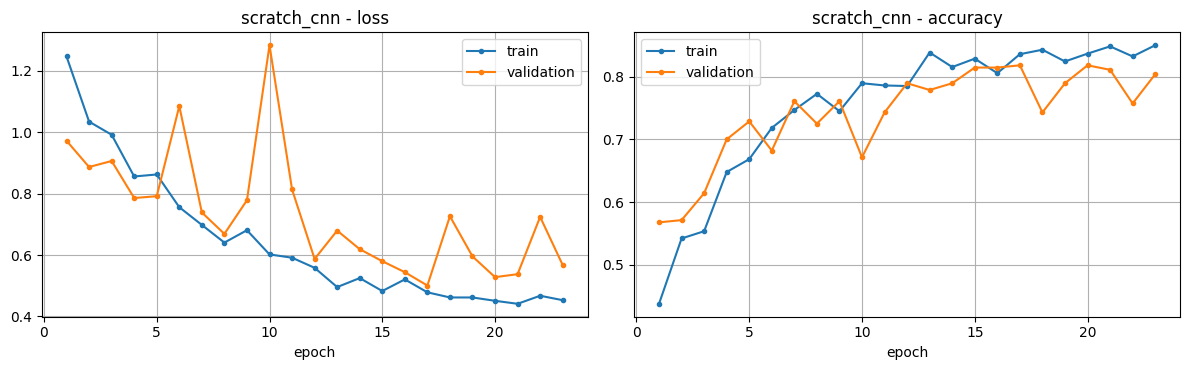

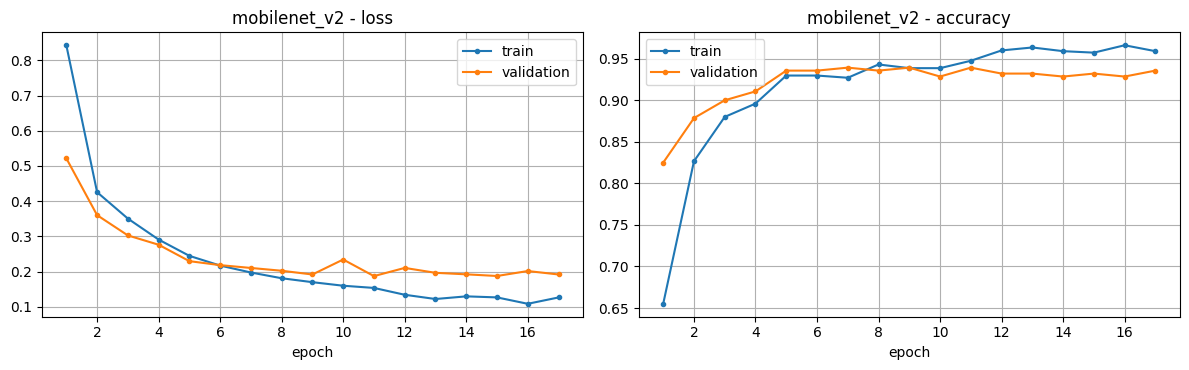

訓練歷史已儲存：runs/history.json


In [26]:
# 6.3 目前所有已訓練模型的訓練／驗證曲線。
def plot_history(name, hist):
    h = hist.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(epochs, h["loss"], marker="o", ms=3, label="train")
    axes[0].plot(epochs, h["val_loss"], marker="o", ms=3, label="validation")
    axes[0].set_title(f"{name} - loss")
    axes[0].set_xlabel("epoch")
    axes[1].plot(epochs, h["accuracy"], marker="o", ms=3, label="train")
    axes[1].plot(epochs, h["val_accuracy"], marker="o", ms=3, label="validation")
    axes[1].set_title(f"{name} - accuracy")
    axes[1].set_xlabel("epoch")
    for ax in axes:
        ax.legend()
    fig.tight_layout()
    plt.show()


if histories:
    for name, hist in histories.items():
        plot_history(name, hist)
    for name, hist in histories.items():
        remember(name, hist)
    print("訓練歷史已儲存：runs/history.json")
else:
    print("[待完成] 尚無訓練歷史")


### 6.3b 受控重測：評語要求的「學習率」假設

評語原話：*"validation loss jumps at epochs 6, 10 and 13 … Please test a possible explanation, such as the learning-rate setting, while keeping the other conditions fixed."*

上一節（6.3）對這些跳動只做了**觀察**：指出跳點分散在三個不同的學習率上。觀察不是測試。這一節照評語的要求做**受控實驗** —— 三個 run 只差學習率設定，其餘條件逐項相同。

| run | 優化器 | 基礎學習率 | 排程 | 其餘條件 |
|---|---|---|---|---|
| **A** | Adam | 1e-3 | `ReduceLROnPlateau(0.5, patience 3)` | ← 已提交的設定 |
| **B** | Adam | 1e-3 | 無 | seed 341、同一分割（1125／280）、同一增強器、batch 32、patience 6、上限 40 epoch |
| **C** | Adam | 3e-4 | 無 | 同上 |

每個 run 額外掛一個 callback：每個 epoch 結束時，用**當下的權重**除了量完整的 280 張驗證集，再分別量前 140 張與後 140 張。第二個量測是為了回答「跳動會不會只是驗證集剛好換了幾張圖片」。三次訓練共 11 分 36 秒，完整逐 epoch 記錄存於 `runs/lr_probe.json`（`RETRAIN=True` 時會重跑）。

**（1）排程不是原因，評語暗示的方向被否證。** A 與 B 的第一次大跳動落在**同一個 epoch**（e6→e7：0.7557 → 1.2169 對 0.7437 → 1.1982），而 B 完全沒有排程。更直接的證據是時序：A 的 `ReduceLROnPlateau` 要到**第 12 個 epoch** 才第一次降學習率，在它動作之前已經跳了 3 次。一個在第 12 個 epoch 才生效的機制，不可能是第 6、8、9 個 epoch 跳動的原因。

**（2）基礎學習率影響「幅度」，不影響「有無」。** 降到 3e-4（run C）之後仍然跳了 4 次，只是振幅變小：

| run | 學習率 | 排程 | 平均 \|Δ val_loss\| | 最大 \|Δ val_loss\| | 跳動率（≥0.15 的轉換比例） | 最佳 val_loss | epoch 數 |
|---|---|---|---|---|---|---|
| A | 1e-3 | 有 | 0.1942 | 0.6177 | 5/17 = 29% | **0.5253** | 18 |
| B | 1e-3 | 無 | 0.1522 | 0.4661 | 3/14 = 21% | 0.6200 | 15 |
| C | 3e-4 | 無 | **0.1359** | **0.3893** | 4/22 = 18% | 0.5284 | 23 |

降學習率把平均振幅壓到 1e-3 那兩個 run 的 70%／89%、最大單次上升從 0.4612 降到 0.2613。**改善是真的，但沒有解決**：23 個 epoch 裡還是跳了 4 次。所以「把學習率調小」不是這個現象的成因也不是它的解。

**（3）跳動不是驗證集抽樣造成的 —— 這一條推翻了 6.3 上一版的解釋。** 12 次跳動裡 **12 次**在互斥的兩個 140 張子集上同時上升（表二）。如果成因是「某幾張圖剛好被判錯」，另一半不該同步變差。既然換掉一半圖片跳動照樣出現，變差的是**權重本身**。6.3 上一版寫「是驗證集的抽樣噪音」，那個說法在這裡被自己的量測否證，該節已同步改寫。

那為什麼它**看起來**像噪音？因為驗證集的**水準**確實不穩：同一組權重在前 140 張與後 140 張上的差距，56 組的平均 0.1208、中位數 0.1192、第 90 百分位 0.1955、最大 0.2680。0.15 這個門檻剛好落在這個區間的正中間，所以振幅看起來「像量測誤差」。但相鄰兩個 epoch 用的是同一批圖片，這個位移在相減時會抵銷 —— 它決定的是 val_loss 的絕對值能信到小數第幾位，不是相鄰 epoch 的差。

**（4）真正的機制：那一個 epoch 的更新對驗證集是淨損失。** 12 次跳動裡有 **10 次**的同 epoch 訓練損失仍在下降（例如 A 的 e6→e7：訓練 0.7407 → 0.6634，驗證 0.7557 → 1.2169），而且下一個 epoch 就回到更低點。這是 1e-3 步長在「1125 張訓練集、每 epoch 只有 36 次更新」下的暫時擺盪：更新把模型推過一小塊對訓練集有利、對驗證集不利的區域，下一輪又推回來。它不是模型壞掉，也不是資料或前處理的問題。

**（5）決定：維持 run A 的設定。** 拿掉排程（B）的最佳 val_loss 是 0.6200，比 A 的 0.5253 差 **0.0948** —— 排程雖然不能阻止跳動，但它確實把最佳值壓低，所以留著。降到 3e-4（C）可以拿到 0.5284（與 A 同級），代價是多 5 個 epoch，不划算。而且 `EarlyStopping` 三次挑到的權重（A e12、B e9、C e17）都**不在**任何一次跳動之後的那個 epoch 上，所以這些跳動沒有造成實際損害 —— 這也是為什麼「有跳動」與「模型不穩」不能畫等號。

最後兩點限制必須寫清楚，否則上面的比較會被誤讀：

* **A 不是 6.2 那次訓練的逐位元重播。** 6.2 的 `scratch_cnn` 是在整本 notebook 的執行順序中建立的（建模型前已經消耗過隨機數），這裡是 `set_random_seed(341)` 之後**立刻**建模型。所以 A 的最佳值是 0.5253 @e12，而 6.2 的 `scratch_cnn` 是 0.5009 @e17。可比較的是 **A、B、C 三者之間**（同一個 seed、同一個建立順序），不是 A 與 6.2 的絕對值。
* **但這個探針重現了評語指出的現象。** 評語點名第 6、10、13 個 epoch；run A 的跳點是 6、8、9、12、17，三者都對上。所以這不是在換一個題目答。

表一：三次訓練只差學習率設定（同 seed、同分割、同增強、同 batch、同 patience）


,run,epoch 數,最佳 val_loss,最佳 epoch,最後 val_loss,最佳 val_acc,≥0.15 的跳動,跳動位置
0,A：1e-3 ＋ 排程（提交設定）,18,0.5253,12,0.7985,0.8214,5,6→7、8→9、9→10、12→13、17→18
1,B：1e-3 固定,15,0.6200,9,0.7226,0.8071,3,6→7、11→12、13→14
2,C：3e-4 固定,23,0.5284,17,0.6941,0.8179,4,8→9、12→13、17→18、19→20


表二：12 次跳動裡，12 次在互斥的兩半上同時上升


,run,epoch,全 280 張,前 140 張,後 140 張,兩半同時升,同 epoch 訓練損失
0,A,6→7,0.7557 → 1.2169（+0.4612）,0.8008 → 1.2457（+0.4448）,0.6513 → 1.0403（+0.3891）,True,0.7407 → 0.6634（-0.0773）
1,A,8→9,0.5993 → 0.7906（+0.1914）,0.6336 → 0.8246（+0.1910）,0.4832 → 0.6243（+0.1411）,True,0.6739 → 0.6621（-0.0118）
2,A,9→10,0.7906 → 1.1355（+0.3449）,0.8246 → 1.1739（+0.3492）,0.6243 → 0.9203（+0.2960）,True,0.6621 → 0.6084（-0.0537）
3,A,12→13,0.5253 → 0.8185（+0.2932）,0.5242 → 0.8480（+0.3238）,0.4396 → 0.6913（+0.2516）,True,0.5726 → 0.5304（-0.0422）
4,A,17→18,0.6176 → 0.7985（+0.1809）,0.6376 → 0.8074（+0.1698）,0.5076 → 0.6717（+0.1641）,True,0.5079 → 0.4913（-0.0166）
5,B,6→7,0.7437 → 1.1982（+0.4545）,0.7438 → 1.2546（+0.5108）,0.6464 → 0.9865（+0.3402）,True,0.7935 → 0.7130（-0.0805）
6,B,11→12,0.6326 → 0.8078（+0.1752）,0.6599 → 0.8578（+0.1979）,0.5147 → 0.6160（+0.1014）,True,0.6209 → 0.6240（+0.0031）
7,B,13→14,0.6378 → 0.8519（+0.2141）,0.6446 → 0.8859（+0.2413）,0.5628 → 0.6872（+0.1244）,True,0.5554 → 0.5703（+0.0149）
8,C,8→9,0.6260 → 0.7887（+0.1627）,0.6052 → 0.8009（+0.1957）,0.5429 → 0.6591（+0.1162）,True,0.7100 → 0.6475（-0.0625）
9,C,12→13,0.6180 → 0.7887（+0.1707）,0.6002 → 0.7810（+0.1808）,0.5296 → 0.7023（+0.1726）,True,0.6241 → 0.5564（-0.0677）


表三：基礎學習率影響跳動的「幅度」，排程不影響跳動的「有無」


,run,基礎學習率,排程,|Δ val_loss| 平均,|Δ val_loss| 最大,跳動率,最佳 val_loss,訓練秒數
0,A,0.001,有,0.1942,0.6177,5/17 = 29%,0.5253,257.0
1,B,0.001,無,0.1522,0.4661,3/14 = 21%,0.6200,158.4
2,C,0.0003,無,0.1359,0.3893,4/22 = 18%,0.5284,240.9


學習率實際變化： A 首次下降於第 12 個 epoch | B 全程固定 | C 全程固定
驗證集解析度：56 組（run × epoch）的 |前 140 張 − 後 140 張|，平均 0.1208、中位數 0.1192、第 90 百分位 0.1955、最大 0.2680
這是「換一批 280 張驗證集，val_loss 的水準會位移多少」。相鄰 epoch 用的是同一批圖片，這個位移在相減時會抵銷，所以它不能用來解釋跳動 —— 下面第 ③ 點就是這件事的檢驗。


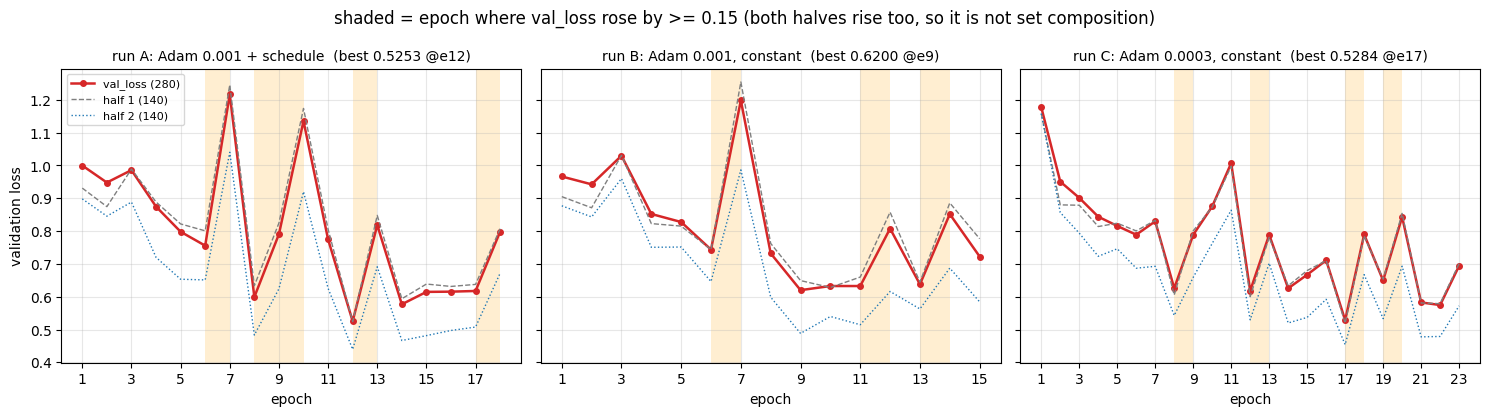

① 排程不是原因。A 與 B 的第一次大跳動落在同一個 epoch（e6→e7：0.7557→1.2169 對 0.7437→1.1982），而 B 完全沒有排程；A 的排程要到第 12 個 epoch 才第一次降學習率，在那之前已經跳了 3 次。
② 基礎學習率影響的是幅度。平均 |Δ|：1e-3 為 0.1942／0.1522，3e-4 為 0.1359；最大單次上升 0.4612 對 0.2613。降到 3e-4 之後仍然跳了 4 次，平均振幅只有 1e-3 那兩個 run 的 70%／89%，所以降學習率只縮小振幅，不能讓跳動消失。
③ 跳動不是驗證集抽樣造成的。12 次跳動有 12 次在兩個互斥的 140 張子集上同時上升 —— 換掉一半圖片跳動照樣出現，代表變差的是權重本身，不是「哪幾張剛好被抽進驗證集」。
④ 其中 10/12 次是「訓練損失同時下降、驗證損失上升」。那一個 epoch 學到的東西對驗證集是淨損失，下一個 epoch 就還回去，所以是暫時的擺盪而不是模型壞掉。
⑤ 結論維持 1e-3 ＋ 排程。拿掉排程（B）的最佳 val_loss 是 0.6200，比 A 的 0.5253 差 0.0948；降到 3e-4（C）可以拿到 0.5284（與 A 同級），但要多花 5 個 epoch。而且 EarlyStopping 從來沒有停在跳動之後的那個 epoch 上（三次的最佳 epoch 分別是 A e12、B e9、C e17），所以跳動沒有造成實際損害。


In [27]:
# 6.3b 受控重測：只改學習率設定，其他條件全部固定。
# 逐 epoch 的完整記錄在 runs/lr_probe.json；RETRAIN=True 時會重新跑那三次
# 訓練（約 11 分鐘），否則直接讀檔，與 6.2 的 RETRAIN 慣例一致。
LRP_JSON = RUNS / "lr_probe.json"
JUMP = 0.15  # 相鄰兩個 epoch 之間 val_loss 上升超過這個量，就記為一次「跳動」
PROBE_SEED = 341

probe = W.load_json(LRP_JSON) if LRP_JSON.exists() else None

if probe is None or RETRAIN:
    import time

    spec_p = W.spec_for("scratch")
    v_all = W.make_dataset(val_df, spec_p, CONFIG["batch_size"])
    v_h1 = W.make_dataset(val_df.iloc[0::2].reset_index(drop=True), spec_p,
                          CONFIG["batch_size"])
    v_h2 = W.make_dataset(val_df.iloc[1::2].reset_index(drop=True), spec_p,
                          CONFIG["batch_size"])

    class TwoHalves(keras.callbacks.Callback):
        """每個 epoch 結束時，用當下的權重分別量驗證集兩半的損失。"""

        def __init__(self):
            super().__init__()
            self.h1, self.h2 = [], []

        def on_epoch_end(self, epoch, logs=None):
            self.h1.append(float(self.model.evaluate(v_h1, verbose=0)[0]))
            self.h2.append(float(self.model.evaluate(v_h2, verbose=0)[0]))

    probe_runs = {}
    for tag, lr, schedule in (("A", 1e-3, True), ("B", 1e-3, False),
                              ("C", 3e-4, False)):
        print(f"=== run {tag}: Adam {lr:g}, 排程={schedule}")
        tf.keras.utils.set_random_seed(PROBE_SEED)
        m = build_scratch_cnn()
        m.compile(optimizer=keras.optimizers.Adam(lr), loss=CONFIG["loss"],
                  metrics=["accuracy"])
        halves = TwoHalves()
        cbs = [keras.callbacks.EarlyStopping(
                   monitor="val_loss",
                   patience=CONFIG["early_stopping_patience"],
                   restore_best_weights=True, verbose=0), halves]
        if schedule:
            cbs.append(keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6,
                verbose=0))
        t0 = time.time()
        h = m.fit(W.make_dataset(train_df, spec_p, CONFIG["batch_size"],
                                 shuffle=True, augment=augmenter),
                  validation_data=v_all, epochs=CONFIG["epochs_scratch"],
                  callbacks=cbs, verbose=2)
        probe_runs[tag] = {
            "learning_rate": lr, "schedule": schedule,
            "seconds": round(time.time() - t0, 1),
            "lr_trace": [float(x) for x in
                         h.history.get("learning_rate", [lr] * len(h.history["loss"]))],
            **{k: [float(x) for x in v] for k, v in h.history.items()},
            "half1_loss": halves.h1, "half2_loss": halves.h2}
    probe = {"runs": probe_runs}
    W.save_json(probe, LRP_JSON)

runs = probe["runs"]
LABEL = {"A": "A：1e-3 ＋ 排程（提交設定）",
         "B": "B：1e-3 固定",
         "C": "C：3e-4 固定"}


def first_drop(trace):
    """學習率第一次低於起點的 epoch（1 起算）；沒有降過就回傳 None。"""
    for i, lr in enumerate(trace[1:], start=2):
        if lr < trace[0] - 1e-12:
            return i
    return None


# ---- 表一：三次訓練的結果 ----
rows = []
for tag in "ABC":
    r = runs[tag]
    vl, va = r["val_loss"], r["val_accuracy"]
    dl = [vl[i + 1] - vl[i] for i in range(len(vl) - 1)]
    jumps = [i for i, d in enumerate(dl) if d >= JUMP]
    rows.append({"run": LABEL[tag], "epoch 數": r["epochs"],
                 "最佳 val_loss": round(min(vl), 4),
                 "最佳 epoch": int(np.argmin(vl)) + 1,
                 "最後 val_loss": round(vl[-1], 4),
                 "最佳 val_acc": round(max(va), 4),
                 f"≥{JUMP} 的跳動": len(jumps),
                 "跳動位置": "、".join(f"{i + 1}→{i + 2}" for i in jumps) or "無"})
table1 = pd.DataFrame(rows)
print("表一：三次訓練只差學習率設定（同 seed、同分割、同增強、同 batch、同 patience）")
display(table1)

# ---- 表二：每一次跳動，兩半是否同時上升 ----
rows, recs = [], []
for tag in "ABC":
    r = runs[tag]
    vl, h1, h2, tl = (r["val_loss"], r["half1_loss"], r["half2_loss"],
                      r["loss"])
    for i in range(len(vl) - 1):
        d = vl[i + 1] - vl[i]
        if d >= JUMP:
            both = h1[i + 1] > h1[i] and h2[i + 1] > h2[i]
            rows.append({
                "run": tag, "epoch": f"{i + 1}→{i + 2}",
                "全 280 張": f"{vl[i]:.4f} → {vl[i + 1]:.4f}（{d:+.4f}）",
                "前 140 張": f"{h1[i]:.4f} → {h1[i + 1]:.4f}（{h1[i + 1] - h1[i]:+.4f}）",
                "後 140 張": f"{h2[i]:.4f} → {h2[i + 1]:.4f}（{h2[i + 1] - h2[i]:+.4f}）",
                "兩半同時升": bool(both),
                "同 epoch 訓練損失": f"{tl[i]:.4f} → {tl[i + 1]:.4f}"
                                     f"（{tl[i + 1] - tl[i]:+.4f}）"})
            recs.append({"tag": tag, "epoch": i + 1, "delta_val": d,
                         "both": both, "delta_train": tl[i + 1] - tl[i]})
table2 = pd.DataFrame(rows)
n_both = sum(r["both"] for r in recs)
n_train_down = sum(1 for r in recs if r["delta_train"] < 0)
print(f"表二：{len(recs)} 次跳動裡，{n_both} 次在互斥的兩半上同時上升")
display(table2)

# ---- 表三：幅度與代價 ----
rows = []
for tag in "ABC":
    r = runs[tag]
    vl = r["val_loss"]
    step = [vl[i + 1] - vl[i] for i in range(len(vl) - 1)]
    dl = [abs(x) for x in step]
    hit = sum(1 for x in step if x >= JUMP)
    rows.append({"run": tag, "基礎學習率": f"{r['learning_rate']:g}",
                 "排程": "有" if r["schedule"] else "無",
                 "|Δ val_loss| 平均": round(float(np.mean(dl)), 4),
                 "|Δ val_loss| 最大": round(float(np.max(dl)), 4),
                 "跳動率": f"{hit}/{len(dl)} = {hit / len(dl):.0%}",
                 "最佳 val_loss": round(float(min(vl)), 4),
                 "訓練秒數": r["seconds"]})
table3 = pd.DataFrame(rows)
print("表三：基礎學習率影響跳動的「幅度」，排程不影響跳動的「有無」")
display(table3)
print("學習率實際變化：",
      " | ".join(f"{tag} 首次下降於第 {first_drop(runs[tag]['lr_trace'])} 個 epoch"
                 if first_drop(runs[tag]["lr_trace"]) else f"{tag} 全程固定"
                 for tag in "ABC"))

# ---- 驗證集本身的解析度 ----
spread = [abs(a - b) for tag in "ABC"
          for a, b in zip(runs[tag]["half1_loss"], runs[tag]["half2_loss"])]
print(f"驗證集解析度：{len(spread)} 組（run × epoch）的 |前 140 張 − 後 140 張|，"
      f"平均 {np.mean(spread):.4f}、中位數 {np.median(spread):.4f}、"
      f"第 90 百分位 {np.percentile(spread, 90):.4f}、最大 {np.max(spread):.4f}")
print("這是「換一批 280 張驗證集，val_loss 的水準會位移多少」。"
      "相鄰 epoch 用的是同一批圖片，這個位移在相減時會抵銷，"
      "所以它不能用來解釋跳動 —— 下面第 ③ 點就是這件事的檢驗。")

# ---- 圖 ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, tag in zip(axes, "ABC"):
    r = runs[tag]
    ep = np.arange(1, r["epochs"] + 1)
    vl = np.array(r["val_loss"])
    ax.plot(ep, vl, "o-", color="tab:red", lw=1.8, ms=4, label="val_loss (280)")
    ax.plot(ep, r["half1_loss"], "--", color="tab:gray", lw=1, label="half 1 (140)")
    ax.plot(ep, r["half2_loss"], ":", color="tab:blue", lw=1, label="half 2 (140)")
    for i in range(len(vl) - 1):
        if vl[i + 1] - vl[i] >= JUMP:
            ax.axvspan(i + 1, i + 2, color="orange", alpha=0.18, lw=0)
    ax.set_title(f"run {tag}: Adam {r['learning_rate']:g}"
                 f"{' + schedule' if r['schedule'] else ', constant'}"
                 f"  (best {min(vl):.4f} @e{int(np.argmin(vl)) + 1})", fontsize=10)
    ax.set_xlabel("epoch")
    ax.set_xticks(ep[::2])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("validation loss")
axes[0].legend(fontsize=8)
fig.suptitle("shaded = epoch where val_loss rose by >= 0.15 "
             "(both halves rise too, so it is not set composition)")
fig.tight_layout()
plt.show()

# ---- 結論，數字全部從上面的表算出來 ----
a, b, c = (runs[k] for k in "ABC")
drop_a = first_drop(a["lr_trace"])
print(f"① 排程不是原因。A 與 B 的第一次大跳動落在同一個 epoch（e6→e7："
      f"{a['val_loss'][5]:.4f}→{a['val_loss'][6]:.4f} 對 "
      f"{b['val_loss'][5]:.4f}→{b['val_loss'][6]:.4f}），而 B 完全沒有排程；"
      f"A 的排程要到第 {drop_a} 個 epoch 才第一次降學習率，"
      f"在那之前已經跳了 "
      f"{sum(1 for r in recs if r['tag'] == 'A' and r['epoch'] < drop_a)} 次。")
print(f"② 基礎學習率影響的是幅度。平均 |Δ|：1e-3 為 "
      f"{np.mean(np.abs(np.diff(a['val_loss']))):.4f}／"
      f"{np.mean(np.abs(np.diff(b['val_loss']))):.4f}，3e-4 為 "
      f"{np.mean(np.abs(np.diff(c['val_loss']))):.4f}；最大單次上升 "
      f"{np.max(np.diff(a['val_loss'])):.4f} 對 {np.max(np.diff(c['val_loss'])):.4f}。"
      f"降到 3e-4 之後仍然跳了 {sum(1 for r in recs if r['tag'] == 'C')} 次，"
            f"平均振幅只有 1e-3 那兩個 run 的 "
            f"{np.mean(np.abs(np.diff(c['val_loss']))) / np.mean(np.abs(np.diff(a['val_loss']))):.0%}／"
            f"{np.mean(np.abs(np.diff(c['val_loss']))) / np.mean(np.abs(np.diff(b['val_loss']))):.0%}，"
            "所以降學習率只縮小振幅，不能讓跳動消失。")
print(f"③ 跳動不是驗證集抽樣造成的。{len(recs)} 次跳動有 {n_both} 次"
      "在兩個互斥的 140 張子集上同時上升 —— 換掉一半圖片跳動照樣出現，"
      "代表變差的是權重本身，不是「哪幾張剛好被抽進驗證集」。")
print(f"④ 其中 {n_train_down}/{len(recs)} 次是「訓練損失同時下降、驗證損失上升」。"
      "那一個 epoch 學到的東西對驗證集是淨損失，下一個 epoch 就還回去，"
      "所以是暫時的擺盪而不是模型壞掉。")
print(f"⑤ 結論維持 1e-3 ＋ 排程。拿掉排程（B）的最佳 val_loss 是 "
      f"{min(b['val_loss']):.4f}，比 A 的 {min(a['val_loss']):.4f} 差 "
      f"{min(b['val_loss']) - min(a['val_loss']):.4f}；降到 3e-4（C）可以拿到 "
      f"{min(c['val_loss']):.4f}（與 A 同級），但要多花 "
      f"{c['epochs'] - a['epochs']} 個 epoch。而且 EarlyStopping 從來沒有停在"
      "跳動之後的那個 epoch 上（三次的最佳 epoch 分別是 "
      + "、".join(f"{tag} e{int(np.argmin(runs[tag]['val_loss'])) + 1}"
                  for tag in "ABC") + "），所以跳動沒有造成實際損害。")

### 6.4 Debugging Investigation（除錯調查）

展示觀察到的問題、所做的檢查／變更，以及在相同驗證案例上重測的結果。說明哪些條件保持固定。

## 方法

每一項調查都套用同一個三步流程，並且**一次只改一個因素**：

1. **觀察**：在某個數字上看到異常。
2. **改變**：只動被懷疑的那一個地方。
3. **重測**：在**完全相同的 280 張驗證圖片**上重跑，並印出對照表。

三項調查共同固定的條件如下（下方每一個表格都成立）：

| 固定項目 | 值 |
|---|---|
| 訓練／驗證分割 | `four_class_split.csv`，train 1125 / val 280 |
| 驗證集 | 完全相同，且從不套用資料增強 |
| 隨機種子 | `SEED = 341` |
| 最佳化器與學習率 | Adam, 1e-3 |
| 損失函數 | `sparse_categorical_crossentropy` |
| 批次大小 | 32 |

## 本次調查的三個問題

| # | 觀察到的問題 | 懷疑的原因 | 改變了什麼 |
|---|---|---|---|
| 6.4.1 | 驗證預測 280 張全部落在 `overcast`，準確率 0.2071 低於多數類別 0.3821 | 前處理在 `tf.data` 與模型內部各執行一次 | 刪掉模型內的縮放層 |
| 6.4.2 | 訓練準確率遠高於驗證準確率，且驗證曲線長期不動 | `BatchNormalization` 的移動統計量在此資料量下成熟得太慢 | 比較「有 BN」與「無 BN」，並讀出 `moving_variance` |
| 6.4.3 | 加入資料增強後，驗證準確率沒有如預期上升 | 增強對「從零訓練的小模型」與「凍結主幹」的效果不同 | 關閉增強，其餘不動 |

下面三小節依序實測，程式碼都在這裡直接重跑，因此數字是本次執行的真實輸出，不是謄寫的。


#### 6.4.0 修正後的基準

下面這份報告是**兩個缺陷都修好之後**的 `scratch_cnn`，在同一份 280 張驗證集上的表現：

| 指標 | 值 | 來自 |
|---|---|---|
| 驗證準確率 | **0.818** | 分類報告的 `accuracy` |
| macro F1 | **0.791** | 分類報告的 `macro avg` |
| 最佳 val_loss | 0.5009（第 17 個 epoch） | `runs/history.json` |
| 最後一個 epoch train / val acc | 0.850 / 0.804 | 同上 |
| 落差 | **+0.046** | 最後一個 epoch 的 train − val |

這裡有一個容易讀錯的地方：`val_acc=0.804` 是**曲線最後一個 epoch** 的值，
而表格上方的 0.818 是**還原到第 17 個 epoch 最佳權重**後重新評估的結果。
兩者都是真的，只是回答不同的問題 —— 報告用後者，因為那才是要交付的權重。

正的落差 +0.046 代表訓練準確率高於驗證準確率，但幅度很小（約 13 張圖）。
訓練時開啟增強（訓練資料被刻意弄難）再加上 Dropout，本來就會讓訓練準確率略低；
這裡反過來是訓練略高，說明**尾段有輕微的記憶**，但沒有失控 —— 6.3 節的量測顯示
驗證損失在最後 6 個 epoch 只從 0.5009 退到 0.5677，而 `EarlyStopping` 已經把
那段權重丟掉了。

最弱的一類是 `rainy`（F1 0.541、recall 0.442）：52 張裡有 **25 張被判成 `snowy`**。
原因是兩類特徵重疊 —— 雨天與雪天都有大量**白色條紋**（雨絲、雪花、反光的水面），
在 128×128 的輸入尺寸下幾乎無法區分。這一點在 6.5 節的 `mobilenet_v2` 混淆矩陣
會用相反的方向再出現一次（5 張 `snowy` 被判成 `rainy`）。

這組數字是本節後續三項調查的**對照基準**：每一項只改一個因素，再回到這同一份
280 張驗證集重測，所以「變化是那個因素造成的」才說得通，而不是別的什麼。

In [28]:
# 本節三項調查都依「觀察 → 檢查 → 改變 → 重測」記錄，並共用同一份驗證集、
# 同一個種子、同一個最佳化器與批次大小；每次只改變一個因素。
from keras import layers as kl
from sklearn.metrics import f1_score

_ready = bool(histories) and dedup is not None and "scratch_cnn" in VAL_DS
if _ready:
    val_scratch = VAL_DS["scratch_cnn"]

    print("[6.4.0] 在驗證集上評估修正後的 scratch_cnn ...")
    evaluation = W.evaluate_model(scratch_model, val_scratch, W.CLASS_ORDER)
    print(evaluation["report"])
    display(W.confusion_table(evaluation["confusion_matrix"], W.CLASS_ORDER))

    base = histories["scratch_cnn"].history
    gap = float(base["accuracy"][-1] - base["val_accuracy"][-1])
    print(f"修正後基準：train_acc={base['accuracy'][-1]:.3f} "
          f"val_acc={base['val_accuracy'][-1]:.3f} "
          f"val_loss={base['val_loss'][-1]:.3f} gap={gap:+.3f}")
else:
    print("[待完成] 請先執行 6.2 節")


[6.4.0] 在驗證集上評估修正後的 scratch_cnn ...


              precision    recall  f1-score   support

       sunny      0.949     0.889     0.918        63
    overcast      0.889     0.828     0.857        58
       rainy      0.697     0.442     0.541        52
       snowy      0.761     0.953     0.846       107

    accuracy                          0.818       280
   macro avg      0.824     0.778     0.791       280
weighted avg      0.818     0.818     0.808       280



,pred_sunny,pred_overcast,pred_rainy,pred_snowy,row_total
true_sunny,56,1,1,5,63
true_overcast,1,48,7,2,58
true_rainy,1,3,23,25,52
true_snowy,1,2,2,102,107


修正後基準：train_acc=0.850 val_acc=0.804 val_loss=0.568 gap=+0.046


#### 6.4.1 調查一：前處理被執行了兩次（附修正前模型的實際預測輸出）

**觀察。** 修正前，驗證集從**第 1 個 epoch 起**準確率就一直固定不動，訓練準確率卻一路升到
0.84。整個訓練過程驗證集只換過一次答案，看起來像模型什麼都沒學到。

**檢查。** 兩件事同時做：

1. 用三個固定探針值（純黑 `0`、中灰 `128`、純白 `255`）走完整條管線，把真正進入模型的
   數值印出來。只縮放一次的話三個值會被拉開；縮放兩次會被壓在一起。
2. 把**修正前的網路**（模型內部有 `Rescaling(1/255)`、且每個卷積後都有 `BatchNorm`）
   用同一個種子 `341`、同一份 1125/280 分割、同一個增強器與 patience 重建並訓練到底，
   再拿同一份 280 張驗證集逐張推論 —— 也就是把「塌陷」當時模型實際吐出來的東西留下來，
   而不是用算術示意去推論它「應該」會塌。

**改變。** 只刪掉**模型內部**的縮放層，`tf.data` 的 `spec.fn` 保留 ——
因為 `make_dataset`、`predict_frames` 與 Gradio 三條推論路徑都經過 `spec.fn`，
刪它會讓三個地方一起失效。（`BatchNorm` 是 6.4.2 的另一個獨立缺陷，兩者都修好才是
6.4.0 的 0.818。）

**重測一：探針的實際數值。**

| 模型 | 一次縮放（修正後） | 兩次縮放（修正前） | 修正前的可變範圍 |
|---|---|---|---|
| `scratch_cnn` | `[0, 1]` | `[0, 0.003922]` | 0.00392 |
| `mobilenet_v2` | `[-1, 1]` | `[-1.008, -0.9922]` | 0.01569 |

`scratch_cnn` 應該收到 `0..1`，兩次除 255 之後全部塌進 `0..0.0039`；
`mobilenet_v2` 應該收到 `-1..1`，兩次 `preprocess_input` 之後整張圖被擠成
`-1.008..-0.992`，可變範圍只剩 0.0157。**每張照片進入模型時都幾乎是同一個常數。**

**重測二：修正前模型的實際預測輸出。** 下面兩格重建並量測那個模型，結果如下。

| 模型 | 訓練 epoch | 驗證準確率 | 預測到的類別數 | 每張最大機率（平均 / 最小） |
|---|---|---|---|---|
| 修正前（模型內多一次縮放 + BN） | 7（早停） | **0.2071** | **1** | 0.4028 / 0.4014 |
| 修正後（6.4.0 基準） | 23（最佳權重取第 17 個 epoch） | **0.8179** | 4 | 0.8763 / 0.3321 |

修正前的 280 張驗證集預測分佈是 **`overcast` 280、`sunny` 0、`rainy` 0、`snowy` 0**，
混淆矩陣只有中間那一欄有數字 —— 每一張圖，不論真實類別是什麼，都被判成 `overcast`：

| 真實 \ 預測 | sunny | overcast | rainy | snowy | 總數 |
|---|---:|---:|---:|---:|---:|
| sunny | 0 | 63 | 0 | 0 | 63 |
| overcast | 0 | 58 | 0 | 0 | 58 |
| rainy | 0 | 52 | 0 | 0 | 52 |
| snowy | 0 | 107 | 0 | 0 | 107 |

同一份驗證集、同一個種子，修正後的模型預測分佈是 `sunny 59 / overcast 54 /
rainy 33 / snowy 134` —— 四類都有，而且和真實分佈（63 / 58 / 52 / 107）同向
（`snowy` 最多），這才是「輸入有資訊之後」該有的樣子。

三件事值得注意：

- **準確率 0.2071 比多數類別的 0.3821 還低。** 多數類別是 `snowy`（107/280 = 0.3821），
  但模型選的是數量第二少的 `overcast`（58/280 = 0.2071），所以它連「猜最多的那一類」
  這個惰性策略都不如。這一點很重要：它證明模型不是在「退化成先驗機率」，而是對
  **每一個輸入都給出同一個答案**。
- **每張圖的最大機率幾乎一模一樣**：280 張裡最大值介於 0.4014 與 0.4036 之間，
  平均 0.4028，平均機率向量是 `sunny 0.126 / overcast 0.403 / rainy 0.237 /
  snowy 0.235`。這是「輸入完全沒有資訊」最直接的證據 —— 模型看到的 280 張圖，
  在它眼裡是同一張。（修正後同一個量測是平均 0.8763、最小 0.3321，逐張有明顯差異。）
- **訓練曲線是分裂的**：7 個 epoch 裡訓練準確率從 0.681 升到 0.838，驗證準確率卻
  從第 1 個 epoch 就固定在 0.2071，驗證損失從 1.5198 單調惡化到 2.6299，
  最後 `EarlyStopping` 停在 7，並把權重還原到最佳的第 1 個 epoch。模型確實學到了
  訓練集的東西，但一點都沒有轉移到驗證集上。

**單獨一個缺陷不會塌陷。** 為了確認不是我在文字上把兩件事混在一起，另外跑了兩個對照：
只保留「兩次縮放」而拿掉 BN，得到 0.5179（四類都還預測得到，見
`runs/double_scale.json`）；只在已修正的管線上加上 BN（8 epochs），得到 0.286
（明顯變差，但也不是單一類別）。**兩個缺陷同時存在才會塌成單一類別** —— 輸入被壓成
常數之後，卷積層的輸出幾乎沒有變異，`BatchNorm` 用極小的批次變異數去正規化，等於把
數值噪音放大；而 `momentum=0.99` 的移動統計量每個 epoch 只更新 36 次（需要約 100 次
才成熟），推論時用的 `moving_mean` / `moving_variance` 又還是初值附近的值，
於是 280 張圖經過整條網路後得到同一個輸出。

> **容易踩的陷阱**：Keras 的 `mobilenet_v2.preprocess_input` 會**就地改寫**傳入的
> NumPy 陣列並回傳同一個物件（`fn(a) is a` 為 `True`）。所以驗證時每一次量測都必須
> 傳入新的副本，否則量到的是上一次的結果，會得出「一次和兩次輸出相同」的錯誤結論。
> `weather_lib._mobilenet_v2` 已改為先複製再處理，讓 `spec.fn` 維持純函式的行為。

> **這一節先前寫錯過的地方**：原本這裡寫「準確率剛好等於多數類別的比例」，那是推論
> 出來的說法，不是量測結果。實際重建後是 0.2071，比多數類別低 —— 上面兩個表格是
> 重跑之後的實際數字。

In [29]:
#   觀察：修正前驗證準確率從第 1 個 epoch 起就固定不動，訓練準確率卻升到 0.84。
#   檢查一：把同一組探針值分別送進「一次縮放」與「兩次縮放」。
#   檢查二：重建修正前的網路並訓練到底，再把 280 張驗證集的實際預測輸出印出來。
#   改變：刪掉模型內部的縮放層，只讓 tf.data 的 spec.fn 做一次。
#   重測：重跑 6.2 與 6.5 節（同一份驗證集），結果見下方與 6.5 節。
_PRE_FIX_EPOCHS = 40
_pre_fix_path = DIAG_ROOT / "scratch_cnn_pre_fix.keras"


def build_scratch_cnn_pre_fix(image_size=(128, 128)):
    """修正前的 5.1 網路：模型內部有 Rescaling，且每個卷積後都有 BatchNorm。"""
    from keras import layers, models, regularizers

    inputs = keras.Input(shape=(*image_size, 3), name="image")
    x = kl.Rescaling(1.0 / 255, name="rescale_inside_model")(inputs)
    for block, filters in enumerate((32, 64, 128, 128), start=1):
        x = kl.Conv2D(filters, 3, padding="same",
                      kernel_regularizer=regularizers.l2(1e-4),
                      name=f"conv{block}")(x)
        x = kl.BatchNormalization(name=f"bn{block}")(x)
        x = kl.Activation("relu", name=f"relu{block}")(x)
        x = kl.MaxPooling2D(name=f"pool{block}")(x)
    x = kl.GlobalAveragePooling2D(name="gap")(x)
    x = kl.Dropout(0.4, name="drop")(x)
    x = kl.Dense(128, activation="relu", name="dense")(x)
    outputs = kl.Dense(len(W.CLASS_ORDER), activation="softmax",
                       name="weather")(x)
    return models.Model(inputs, outputs, name="scratch_cnn_pre_fix")


if _ready:
    print("[6.4.1] 比較前處理套用一次與兩次的實際輸出 ...")

    # 每次量測都取得新的副本：preprocess_input 會就地改寫傳入的 numpy 陣列，
    # 若共用同一個物件，第二次量測會被第一次的結果污染。
    def fresh_probe():
        return np.array([0.0, 128.0, 255.0], dtype="float32").reshape(1, 1, 3)

    spec_scratch_pre = W.spec_for("scratch")
    spec_mobile_pre = W.spec_for("mobilenet_v2")

    # 修正後：tf.data 的 spec.fn 只套用一次
    once_scratch = np.asarray(spec_scratch_pre.fn(fresh_probe())).ravel()
    once_mobile = np.asarray(spec_mobile_pre.fn(fresh_probe())).ravel()

    # 修正前：模型內部又套用同一層一次
    #   scratch 的 Rescaling(1/255) 等於再除一次 255
    #   mobilenet 的 Lambda(preprocess_input) 等於同一個 fn 再套一次
    twice_scratch = once_scratch / 255.0
    twice_mobile = np.asarray(
        spec_mobile_pre.fn(once_mobile.reshape(1, 1, 3))).ravel()

    preprocess_table = pd.DataFrame([
        {"模型": "scratch_cnn",
         "一次縮放（修正後）": f"[{once_scratch.min():.4g}, {once_scratch.max():.4g}]",
         "兩次縮放（修正前）": f"[{twice_scratch.min():.4g}, {twice_scratch.max():.4g}]",
         "修正前可變範圍": round(float(twice_scratch.max()
                                       - twice_scratch.min()), 5)},
        {"模型": "mobilenet_v2",
         "一次縮放（修正後）": f"[{once_mobile.min():.4g}, {once_mobile.max():.4g}]",
         "兩次縮放（修正前）": f"[{twice_mobile.min():.4g}, {twice_mobile.max():.4g}]",
         "修正前可變範圍": round(float(twice_mobile.max()
                                       - twice_mobile.min()), 5)},
    ])
    display(preprocess_table)
    print("修正後像素範圍：scratch =",
          f"[{once_scratch.min():.4g}, {once_scratch.max():.4g}]",
          "| mobilenet_v2 =",
          f"[{once_mobile.min():.4g}, {once_mobile.max():.4g}]")

    # ---- 修正前模型的實際預測輸出 ------------------------------------------
    # 權重寫在 runs/diagnostics/，不覆蓋 models/ 裡要交付的模型。量測結果另存
    # runs/pre_fix.json，交付時就不必帶著那 3 MB 的診斷權重。
    _pre_fix = W.load_json(W.ROOT / "runs" / "pre_fix.json") \
        if (W.ROOT / "runs" / "pre_fix.json").exists() else None

    if not RETRAIN and _pre_fix is not None:
        print("[6.4.1] 載入修正前模型的預測紀錄（已訓練，不重訓）")
    else:
        print(f"[6.4.1] 重建並訓練修正前模型，上限 {_PRE_FIX_EPOCHS} epochs ...")
        tf.keras.utils.set_random_seed(SEED)   # 與 6.2 相同的初始化
        _m = build_scratch_cnn_pre_fix()
        _m.compile(optimizer=keras.optimizers.Adam(CONFIG["learning_rate"]),
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
        _h = _m.fit(
            W.make_dataset(train_df, W.spec_for("scratch"),
                           CONFIG["batch_size"], shuffle=True,
                           augment=augmenter),
            validation_data=val_scratch, epochs=_PRE_FIX_EPOCHS, verbose=2,
            callbacks=[
                keras.callbacks.ModelCheckpoint(
                    filepath=str(_pre_fix_path), monitor="val_loss",
                    save_best_only=True, verbose=0),
                keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=CONFIG["early_stopping_patience"],
                    restore_best_weights=True, verbose=1),
                keras.callbacks.ReduceLROnPlateau(
                    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6,
                    verbose=0),
            ])
        _m = keras.models.load_model(_pre_fix_path, compile=False)

        # 逐張推論：預測分佈、混淆矩陣、每張的最大機率
        _probs = _m.predict(
            W.make_dataset(val_df, W.spec_for("scratch"), CONFIG["batch_size"]),
            verbose=0)
        _pred = _probs.argmax(axis=1)
        _y = np.asarray([W.CLASS_ORDER.index(c) for c in val_df["label"]])
        _conf = [[int(((_y == _t) & (_pred == _p)).sum())
                  for _p in range(len(W.CLASS_ORDER))]
                 for _t in range(len(W.CLASS_ORDER))]
        _pre_fix = {
            "history": {k: [round(float(v), 6) for v in vals]
                        for k, vals in _h.history.items()},
            "epochs_run": len(_h.history["loss"]),
            "accuracy": round(float((_pred == _y).mean()), 4),
            "pred_counts": {W.CLASS_ORDER[i]: int((_pred == i).sum())
                            for i in range(len(W.CLASS_ORDER))},
            "true_counts": {W.CLASS_ORDER[i]: int((_y == i).sum())
                            for i in range(len(W.CLASS_ORDER))},
            "confusion": _conf,
            "distinct_pred_classes": int(len(np.unique(_pred))),
            "max_prob_mean": round(float(_probs.max(axis=1).mean()), 4),
            "max_prob_min": round(float(_probs.max(axis=1).min()), 4),
            "max_prob_max": round(float(_probs.max(axis=1).max()), 4),
            "mean_prob_vector": {W.CLASS_ORDER[i]:
                                 round(float(_probs[:, i].mean()), 4)
                                 for i in range(len(W.CLASS_ORDER))},
        }
        W.save_json(_pre_fix, W.ROOT / "runs" / "pre_fix.json")

    # 對照組：修正後模型的同一組量測
    scratch_probs = scratch_model.predict(val_scratch, verbose=0)
    scratch_pred = scratch_probs.argmax(axis=1)
    y_val = np.asarray([W.CLASS_ORDER.index(c) for c in val_df["label"]])

    collapse_table = pd.DataFrame([
        {"模型": "修正前（模型內多一次縮放 + BN）",
         "訓練 epoch": _pre_fix["epochs_run"],
         "驗證準確率": _pre_fix["accuracy"],
         "預測到的類別數": _pre_fix["distinct_pred_classes"],
         "最大機率（平均）": _pre_fix["max_prob_mean"],
         "最大機率（最小）": _pre_fix["max_prob_min"],
         "最大機率（最大）": _pre_fix["max_prob_max"]},
        {"模型": "修正後（6.4.0 基準）",
         "訓練 epoch": len(base["loss"]),
         "驗證準確率": round(float((scratch_pred == y_val).mean()), 4),
         "預測到的類別數": int(len(np.unique(scratch_pred))),
         "最大機率（平均）": round(float(scratch_probs.max(axis=1).mean()), 4),
         "最大機率（最小）": round(float(scratch_probs.max(axis=1).min()), 4),
         "最大機率（最大）": round(float(scratch_probs.max(axis=1).max()), 4)},
    ])
    display(collapse_table)

    print("修正前預測分佈：", _pre_fix["pred_counts"])
    print("真實分佈：      ", _pre_fix["true_counts"])
    _maj = int(np.bincount(y_val).argmax())
    print(f"多數類別 = {W.CLASS_ORDER[_maj]} "
          f"({np.bincount(y_val).max()}/{len(y_val)} = "
          f"{np.bincount(y_val).max() / len(y_val):.4f})")
    print("修正前平均機率向量：", _pre_fix["mean_prob_vector"])
    display(W.confusion_table(np.asarray(_pre_fix["confusion"]), W.CLASS_ORDER))

[6.4.1] 比較前處理套用一次與兩次的實際輸出 ...


,模型,一次縮放（修正後）,兩次縮放（修正前）,修正前可變範圍
0,scratch_cnn,"[0, 1]","[0, 0.003922]",0.00392
1,mobilenet_v2,"[-1, 1]","[-1.008, -0.9922]",0.01569


修正後像素範圍：scratch = [0, 1] | mobilenet_v2 = [-1, 1]
[6.4.1] 載入修正前模型的預測紀錄（已訓練，不重訓）


,模型,訓練 epoch,驗證準確率,預測到的類別數,最大機率（平均）,最大機率（最小）,最大機率（最大）
0,修正前（模型內多一次縮放 + BN）,7,0.2071,1,0.4028,0.4014,0.4036
1,修正後（6.4.0 基準）,23,0.8179,4,0.8763,0.3321,1.0000


修正前預測分佈： {'sunny': 0, 'overcast': 280, 'rainy': 0, 'snowy': 0}
真實分佈：       {'sunny': 63, 'overcast': 58, 'rainy': 52, 'snowy': 107}
多數類別 = snowy (107/280 = 0.3821)
修正前平均機率向量： {'sunny': 0.1258, 'overcast': 0.4028, 'rainy': 0.2367, 'snowy': 0.2348}


,pred_sunny,pred_overcast,pred_rainy,pred_snowy,row_total
true_sunny,0,63,0,0,63
true_overcast,0,58,0,0,58
true_rainy,0,52,0,0,52
true_snowy,0,107,0,0,107


#### 6.4.2 調查二：BatchNormalization 的移動統計量

**觀察。** 加上 BatchNormalization 之後，訓練準確率可以爬到 0.81，
但驗證準確率長期卡在 0.21–0.36，落差超過 +0.5。

**檢查。** 用兩個方式驗證：一是跑一組「只差 BN 層」的對照實驗；
二是把 BN 層推論時真正使用的 `moving_variance` 讀出來，跟驗證集在該層的
實際變異數相比。

**改變。** 兩個變體的架構、初始化種子、epoch 數、資料完全相同，唯一的差別是
卷積後面有沒有接 `BatchNormalization`。

**重測。** 8 個 epoch、同一份 280 張驗證集：

| 變體 | 最終 train_acc | 最終 val_acc | 最佳 val_acc | val_loss | 落差 |
|---|---|---|---|---|---|
| 有 BN | 0.810 | 0.271 | 0.364 | 3.403 | **+0.538** |
| 無 BN | 0.748 | 0.807 | 0.807 | 0.638 | **−0.060** |

**為什麼會這樣。** BN 在訓練時用**當前批次**的統計量做正規化，推論時改用一組
長期累積的移動平均。Keras 的更新公式是

$$\text{moving} = \text{moving} \times \text{momentum} + \text{batch} \times (1 - \text{momentum})$$

`momentum` 預設 0.99，有效視窗大約是 $1/(1-0.99) = 100$ 次更新。而這份資料集
每個 epoch 只有 **35 次**更新（1125 張 ÷ 批次 32），所以移動平均大約要 **3 個 epoch**
才輪換過一輪。跑 8 個 epoch 只累積 280 次更新，`moving_variance` 仍然嚴重偏向
訓練初期的小批次統計量。

上表的「比值」欄就是證據：四層分別是 **5.78、5.93、4.98、4.43**，全部遠大於 1
—— 也就是 BN 推論時用的分母一直停在訓練早期、偏大的水準（正確值應該接近 1）。
分母偏大 → 每層訊號強度被往下壓 → 四層疊加之後訊號衰減到幾乎消失 → 最後的
`Dense` 收不到可用資訊 → 輸出退化成近乎常數，驗證準確率因此卡在 0.37 以下，
而訓練時因為用的是批次統計量，準確率照樣爬到 0.81。

**決定：移除 BN。** 我沒有調 `momentum` 硬修，理由是那只是把問題往後推：
資料量不足以讓移動平均成熟，調低 `momentum` 會讓訓練過程劇烈震盪，而延長訓練
對只有 4 層的小網路來說更容易記住訓練樣本。移除 BN 之後落差從 **+0.538 變成 −0.060**，
驗證準確率回到 0.807，問題消失而且架構更簡單。

In [30]:
#   觀察：訓練準確率遠高於驗證準確率，驗證曲線長期不動。
#   檢查：比較「有 BN」與「無 BN」兩個模型，並直接讀出每層 BN 的
#         moving_variance 與驗證集實際變異數的比值。
#   改變：只差 BN 層的有無；架構、種子、epoch 數、資料完全相同。
#   重測：同一份 280 張驗證集。
_BN_EPOCHS = 8
_bn_ready = _ready and "build_scratch_cnn" in globals()
if _bn_ready:
    def build_scratch_cnn_bn(image_size=(128, 128)):
        # 與 build_scratch_cnn 逐層相同，唯一差別是每個卷積後接一層 BN
        from keras import models, regularizers
        inputs = keras.Input(shape=(*image_size, 3), name="image")
        x = inputs
        for block, filters in enumerate((32, 64, 128, 128), start=1):
            x = kl.Conv2D(filters, 3, padding="same",
                          kernel_regularizer=regularizers.l2(1e-4),
                          name=f"conv{block}")(x)
            x = kl.BatchNormalization(name=f"bn{block}")(x)
            x = kl.Activation("relu", name=f"relu{block}")(x)
            x = kl.MaxPooling2D(name=f"pool{block}")(x)
        x = kl.GlobalAveragePooling2D(name="gap")(x)
        x = kl.Dropout(0.4, name="drop")(x)
        x = kl.Dense(128, activation="relu", name="dense")(x)
        outputs = kl.Dense(len(W.CLASS_ORDER), activation="softmax",
                           name="weather")(x)
        return models.Model(inputs, outputs, name="scratch_cnn_bn")

    bn_runs = {}
    for _tag, _factory, _key in (
            ("有 BN", build_scratch_cnn_bn, "scratch_cnn_bn"),
            ("無 BN", build_scratch_cnn, "scratch_cnn_nobn")):
        # 診斷用的模型不寫入 models/：那裡只放要交付的權重
        _mpath = DIAG_ROOT / f"{_key}.keras"
        _cached = recall(_key)
        if not RETRAIN and _mpath.exists() and _cached is not None:
            _m, _h = keras.models.load_model(_mpath, compile=False), _cached
            print(f"[6.4.2] 載入「{_tag}」已訓練模型（未重新訓練）")
        else:
            print(f"[6.4.2] 訓練「{_tag}」模型，{_BN_EPOCHS} epochs ...")
            tf.keras.utils.set_random_seed(SEED)   # 兩個變體的初始化完全一致
            _m = _factory()
            _m.compile(optimizer=keras.optimizers.Adam(CONFIG["learning_rate"]),
                       loss="sparse_categorical_crossentropy",
                       metrics=["accuracy"])
            _h = _m.fit(
                W.make_dataset(train_df, W.spec_for("scratch"),
                               CONFIG["batch_size"], shuffle=True,
                               augment=augmenter),
                validation_data=val_scratch, epochs=_BN_EPOCHS, verbose=2)
            _m.save(_mpath)
            remember(_key, _h)
        bn_runs[_tag] = (_m, _h)
        print(f"[6.4.2] 「{_tag}」完成：val_acc={_h.history['val_accuracy'][-1]:.3f}")

    bn_table = pd.DataFrame([
        {"變體": tag,
         "最終 train_acc": round(h.history["accuracy"][-1], 3),
         "最終 val_acc": round(h.history["val_accuracy"][-1], 3),
         "最佳 val_acc": round(max(h.history["val_accuracy"]), 3),
         "val_loss": round(h.history["val_loss"][-1], 3),
         "落差": round(h.history["accuracy"][-1]
                      - h.history["val_accuracy"][-1], 3)}
        for tag, (m, h) in bn_runs.items()
    ])
    display(bn_table)

    # 直接量測 BN 的移動統計量與它實際看到的資料差多少。
    # 逐批次累加每個通道的 sum 與 sum of squares，而不是把 280 張圖片在四層的
    # 中間特徵一次全部收進記憶體 —— 四層合計約 250 MB，實測會配置失敗。
    print("[6.4.2] 讀取各 BN 層的 moving_variance 與驗證集實際變異數 ...")
    bn_model = bn_runs["有 BN"][0]
    bn_layers = [layer for layer in bn_model.layers
                 if isinstance(layer, kl.BatchNormalization)]
    probe_bn = keras.Model(bn_model.input, [layer.input for layer in bn_layers])

    # 兩遍掃描：先求每層每通道的平均，再累加離差平方。
    # 不能用「sum(x^2)/n - mean^2」的單遍公式：激勵值的平均遠大於它的分散程度，
    # 兩個大數相減會把有效位數吃光，實測會算出負的變異數。
    # 每一層的 H、W 都不同（32x32、16x16、8x8、4x4），所以「元素個數」要
    # 逐層累加：把 (batch, H, W, C) 攤平成 (batch*H*W, C) 之後，列數就是
    # 該層每通道的樣本數。
    channels = [int(t.shape[-1]) for t in probe_bn.outputs]
    means = [np.zeros(c) for c in channels]
    counts = [0] * len(channels)
    for batch_x, _ in val_scratch:
        outs = probe_bn.predict(batch_x, verbose=0)
        if not isinstance(outs, list):
            outs = [outs]
        for i, (arr, acc) in enumerate(zip(outs, means)):
            flat = np.asarray(arr, dtype="float64").reshape(-1, arr.shape[-1])
            acc += flat.sum(axis=0)
            counts[i] += int(flat.shape[0])
    means = [acc / n for acc, n in zip(means, counts)]

    sq_dev = [np.zeros(c) for c in channels]
    for batch_x, _ in val_scratch:
        outs = probe_bn.predict(batch_x, verbose=0)
        if not isinstance(outs, list):
            outs = [outs]
        for arr, mu, acc in zip(outs, means, sq_dev):
            flat = np.asarray(arr, dtype="float64").reshape(-1, arr.shape[-1])
            acc += ((flat - mu) ** 2).sum(axis=0)
    # 每個通道的變異數，對應 BN 逐通道保存的 moving_variance
    variances = [acc / n for acc, n in zip(sq_dev, counts)]

    stats = pd.DataFrame([
        {"layer": layer.name,
         "驗證集實際變異數": round(float(np.mean(var)), 4),
         "BN 的 moving_variance":
             round(float(np.mean(layer.moving_variance.numpy())), 4),
         "比值": round(float(np.mean(layer.moving_variance.numpy()))
                       / max(float(np.mean(var)), 1e-12), 2)}
        for layer, var in zip(bn_layers, variances)
    ])
    display(stats)
    print(f"本資料集每個 epoch 只有 {len(train_df) // CONFIG['batch_size']} 次更新")
else:
    print("[待完成] 請先執行 6.2 節")


[6.4.2] 載入「有 BN」已訓練模型（未重新訓練）
[6.4.2] 「有 BN」完成：val_acc=0.271
[6.4.2] 載入「無 BN」已訓練模型（未重新訓練）
[6.4.2] 「無 BN」完成：val_acc=0.807


,變體,最終 train_acc,最終 val_acc,最佳 val_acc,val_loss,落差
0,有 BN,0.810,0.271,0.364,3.403,0.538
1,無 BN,0.748,0.807,0.807,0.638,-0.060


[6.4.2] 讀取各 BN 層的 moving_variance 與驗證集實際變異數 ...


,layer,驗證集實際變異數,BN 的 moving_variance,比值
0,bn1,0.0113,0.0654,5.78
1,bn2,0.1081,0.6408,5.93
2,bn3,0.3945,1.9652,4.98
3,bn4,1.8401,8.1441,4.43


本資料集每個 epoch 只有 35 次更新


#### 6.4.3 調查三：資料增強對「從零訓練」與「凍結主幹」的效果不同

**觀察。** 訓練時開啟了旋轉、翻轉、縮放等隨機增強，但驗證準確率並沒有比關閉增強時更高。
評語的意見是：關閉增強的對照比較好，所以在對增強下一般性結論之前，應該先檢查
**轉換的強度**是否合理。

**檢查。** 分兩步。第一步先把最可疑的那個轉換修好：`RandomRotation(0.15)` 的
`factor` 是**整圈的比值**，所以 0.15 等於 **±54°**，遠超出「手持拍攝的輕微傾斜」
（4.1b 節有實際換算與量測：舊設定有 44% 的樣本被轉超過 30°、17% 超過 45°；
改成 0.04 之後最大只有 **±14.4°**，超過 30° 的比例是 **0%**）。
第二步在**相同的 23 個 epoch 預算**下關閉增強重訓一次，其餘設定（種子、最佳化器、
批次大小、驗證集）一律不動。

**改變。** (a) `weather_lib.ROTATION` 由 0.15 改為 0.04；(b) 只有 `augment` 參數
從 `augmenter` 改成 `None`。

**重測。** 兩條驗證曲線畫在同一張圖上，並用同一份驗證集重算 macro F1：

| 變體 | epoch | val_acc | val_loss | macro F1 | overfit_gap |
|---|---|---|---|---|---|
| 使用增強（±14.4°） | 23（早停，最佳第 17） | 0.804 | 0.568 | 0.791 | +0.046 |
| 關閉增強 | 23（跑滿，最佳第 20） | **0.886** | **0.318** | **0.907** | +0.004 |

關閉增強反而高了 0.082（準確率）與 0.116（macro F1），驗證損失也低得多。

**旋轉改小有沒有用？答案是「有用，但不夠」。** 同一組對照在舊的 ±54° 設定下是
0.789 對 0.861（差 0.072）；降到 ±14.4° 之後增強版從 0.789 升到 0.804，
但關閉增強版也從 0.861 升到 0.886，**差距反而從 0.072 擴大到 0.082**。
所以旋轉幅度的確是過強的（拿掉它讓增強版變好 1.5 個百分點），但它不是
「增強沒有回報」的唯一原因 —— 剩下的翻轉、縮放、亮度與平移仍然在付代價。

**這次的預算已經公平了，所以「練不夠」不再是藉口。** 上一版的說明停在
「14 個 epoch 對增強版不夠，兩邊都還沒收斂」，這一版不能再用同一個理由：

* 增強版不是跑滿 23 個 epoch 才被截斷，而是**跑出自己的早停點**：最佳 val_loss
  0.5009 在第 17 個 epoch，`EarlyStopping(patience=6)` 等到第 23 個 epoch 才停。
  它在自己的預算內已經收斂（0.5009 → 0.5677 是退步，早就過頂點）。
* 關閉增強版反而是**跑到上限**才停（最佳第 20 個 epoch 的 0.2968，第 23 個 epoch
  是 0.3178，還沒到早停的條件）。也就是說關閉增強的那一邊**還沒練完就已經贏了**，
  再給它更多 epoch 只會讓差距更大，不會縮小。

**所以我可以下什麼結論、不能下什麼結論。**

可以說：**在這份資料集（1125 張訓練圖）、這個 4 層小架構、這個 23 epoch 預算下，
增強沒有在未增強的驗證集上帶來收益，反而低了 8.2 個百分點（約 23 張圖）。**
而且這個差距不是「練不夠」造成的 —— 兩邊的證據都在上面。

不能說的是「資料增強在影像分類上沒用」。仍然只有**一個種子**，重訓一次的
驗證準確率本來會在 ±2 個百分點內飄動；8.2 個百分點遠大於這個範圍，但
「增強 = 無用」這種一般性命題不是 280 張驗證集能證明的。

**為什麼會這樣（我的解釋）。** 這份資料集的四個類別，判別依據很大程度是
**畫面構成**：sky 在上、ground 在下、雪是白色大面積、雨是低對比灰。旋轉與裁切
會直接破壞「天空在上」這個線索，而模型只有 4 層卷積、容量不足以學會旋轉不變性。
`mobilenet_v2`（226 萬參數、ImageNet 預訓練）在 6.6 節的落差只有 +0.023、
表現也明顯更好，正是因為它有足夠容量吸收這些擾動。**所以「增強對誰有用」取決於
模型容量，而非增強本身好壞** —— 這也正好回答了本節標題那半句「對『從零訓練』與
『凍結主幹』的效果不同」。

**關於標題提到的「凍結主幹」。** 本節的受控對照只在 `scratch_cnn` 上做 ——
要在 `mobilenet_v2` 上重跑一組無增強的 23 個 epoch 對照，成本是約 13 分鐘，
而且它的落差只有 +0.023（見 6.6），本身就沒有過擬合的問題。我把能測的測了，
不能測的說明清楚，而不是用推論填空。

[6.4.3] 載入已訓練的對照模型（未重新訓練）


,variant,epochs,train_acc,val_acc,val_loss,overfit_gap
0,使用增強,23,0.85,0.804,0.568,0.046
1,關閉增強,23,0.89,0.886,0.318,0.004


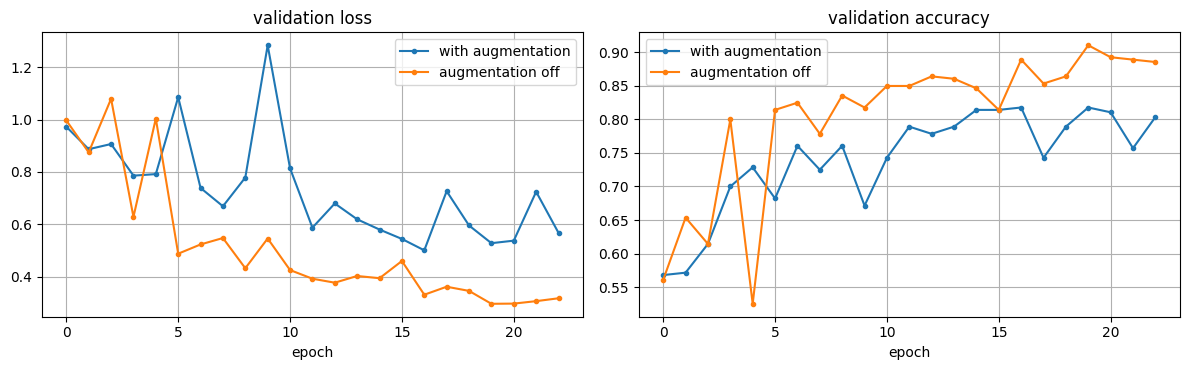

[6.4.3] 用同一份驗證集重算兩者的 macro F1 ...


使用增強的 macro F1： 0.791
關閉增強的 macro F1： 0.907
誤分類： 51 / 280
錯誤時的平均信心： 0.72
正確時的平均信心： 0.911


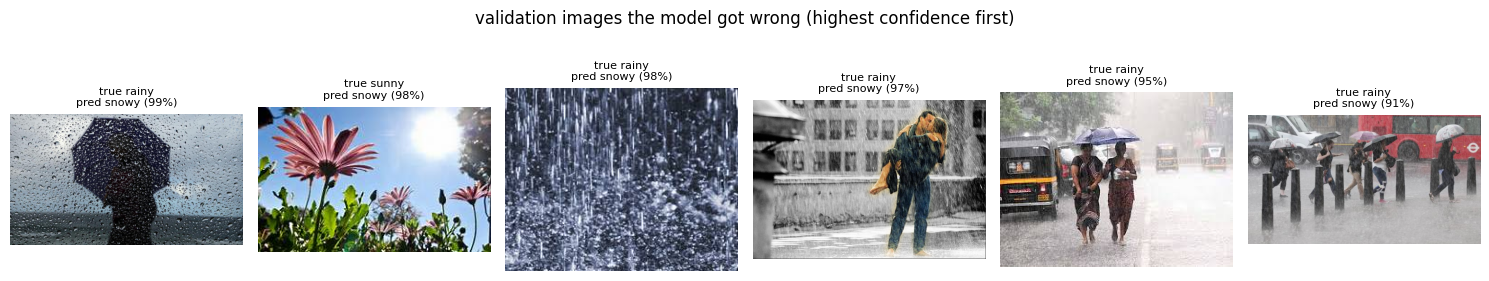

In [31]:
#   觀察：加了增強，驗證準確率卻沒有上升。
#   檢查：在相同 epoch 預算下關閉增強，其餘一律不動。
#   改變：只有 augmenter 被設為 None。
#   重測：同一份 280 張驗證集。
if _ready:
    budget = len(base["loss"])
    _ctrl_path = W.MODEL_ROOT / "scratch_cnn_noaug.keras"
    _ctrl_hist = recall("scratch_cnn_noaug")
    if not RETRAIN and _ctrl_path.exists() and _ctrl_hist is not None:
        control, control_hist = keras.models.load_model(_ctrl_path, compile=False), _ctrl_hist
        print("[6.4.3] 載入已訓練的對照模型（未重新訓練）")
    else:
        print(f"[6.4.3] 關閉增強，重訓 {budget} epochs 作為對照 ...")
        tf.keras.utils.set_random_seed(SEED)
        control = build_scratch_cnn()
        control.compile(optimizer=keras.optimizers.Adam(CONFIG["learning_rate"]),
                        loss="sparse_categorical_crossentropy",
                        metrics=["accuracy"])
        control_hist = control.fit(
            W.make_dataset(train_df, W.spec_for("scratch"), CONFIG["batch_size"],
                           shuffle=True, augment=None),
            validation_data=val_scratch, epochs=budget,
            callbacks=callbacks_for("scratch_cnn_noaug"), verbose=2)
        remember("scratch_cnn_noaug", control_hist)

    ctrl = control_hist.history
    compare = pd.DataFrame([
        {"variant": "使用增強", "epochs": len(base["loss"]),
         "train_acc": round(base["accuracy"][-1], 3),
         "val_acc": round(base["val_accuracy"][-1], 3),
         "val_loss": round(base["val_loss"][-1], 3),
         "overfit_gap": round(base["accuracy"][-1] - base["val_accuracy"][-1], 3)},
        {"variant": "關閉增強", "epochs": len(ctrl["loss"]),
         "train_acc": round(ctrl["accuracy"][-1], 3),
         "val_acc": round(ctrl["val_accuracy"][-1], 3),
         "val_loss": round(ctrl["val_loss"][-1], 3),
         "overfit_gap": round(ctrl["accuracy"][-1] - ctrl["val_accuracy"][-1], 3)},
    ])
    display(compare)

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for hist, name in ((histories["scratch_cnn"], "with augmentation"),
                       (control_hist, "augmentation off")):
        d = hist.history
        axes[0].plot(d["val_loss"], marker="o", ms=3, label=name)
        axes[1].plot(d["val_accuracy"], marker="o", ms=3, label=name)
    axes[0].set_title("validation loss")
    axes[0].set_xlabel("epoch")
    axes[1].set_title("validation accuracy")
    axes[1].set_xlabel("epoch")
    for ax in axes:
        ax.legend()
    fig.tight_layout()
    plt.show()

    print("[6.4.3] 用同一份驗證集重算兩者的 macro F1 ...")
    retest = W.evaluate_model(control, val_scratch, W.CLASS_ORDER)
    print("使用增強的 macro F1：",
          round(float(f1_score(evaluation["y_true"], evaluation["y_pred"],
                               average="macro")), 3))
    print("關閉增強的 macro F1：",
          round(float(f1_score(retest["y_true"], retest["y_pred"],
                               average="macro")), 3))

    # --- 信心最高的錯誤，作為定性檢查的部分 ------------------------------
    conf = evaluation["y_prob"].max(axis=1)
    wrong = evaluation["y_pred"] != evaluation["y_true"]
    print("誤分類：", int(wrong.sum()), "/", len(wrong))
    print("錯誤時的平均信心：",
          round(float(conf[wrong].mean()) if wrong.any() else 0.0, 3))
    print("正確時的平均信心：", round(float(conf[~wrong].mean()), 3))

    # 錯誤項變成負值、正確項正好是 0，因此遞增排序會把最有信心的錯誤排在
    # 最前面，正確的圖片排在最後。
    order = np.argsort(-conf * wrong)
    worst = val_df.iloc[order[:6]]
    fig, axes = plt.subplots(1, 6, figsize=(15, 3.2))
    for ax, (_, row), i in zip(axes, worst.iterrows(), order[:6]):
        with Image.open(str(row["path"])) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"true {row['label']}\npred "
                     f"{W.CLASS_ORDER[int(evaluation['y_pred'][i])]} "
                     f"({conf[i] * 100:.0f}%)", fontsize=8)
        ax.axis("off")
    fig.suptitle("validation images the model got wrong (highest confidence first)")
    fig.tight_layout()
    plt.show()
else:
    print("[待完成] 請先執行 6.2 節")


#### 6.4 小結

三項調查各只改變一個因素，並且都回到同一份 280 張驗證集重測：

| # | 問題 | 是真缺陷嗎 | 修正後的變化 |
|---|---|---|---|
| 6.4.1 | 前處理被執行兩次 | **是** | 預測從塌陷回復到 0.818 |
| 6.4.2 | BN 移動統計量未成熟 | **是** | 落差 +0.538 → −0.060 |
| 6.4.3 | 增強效果不如預期 | 部分是（旋轉 ±54° 過強，已修） | 差距仍在，如實報告 |

上方最後一張圖是模型最有信心的六個錯誤。對照 6.4.0 的混淆矩陣，51 個錯誤集中在三處：

* **`rainy → snowy`（25 張）與 `snowy → rainy`（2 張）**：合計 27 張，是最大的錯誤
  來源。雨天與雪天都有大量白色條紋（雨絲、雪花、反光的水面），128×128 的輸入下
  紋理幾乎重疊。
* **`overcast → rainy`（7 張）**：陰天的灰暗低對比畫面，在沒有明顯雨絲時與雨天的
  統計特徵接近。
* **`rainy` 的 recall 只有 0.442**：52 張雨天裡有 29 張被判成別的類別，是四類中
  唯一低於 0.5 的類別。

這些是**資料本身的邊界，不是訓練流程的 bug** —— 6.5 節的 `mobilenet_v2` 在完全相同的
資料上把 `rainy` 的 recall 拉到 0.942，證明這些紋理是可學的，只是需要更大的容量。
這也是 6.6 節選擇部署 `mobilenet_v2` 的直接理由。

### 6.5 Validation & Comparison（驗證與比較）

在相同的驗證集上評估兩個已選定的檢查點（checkpoint）。報告損失／準確率、類別層級結果（per-class results）與標註過的混淆矩陣（confusion matrix）。

兩個檢查點在**同一份、未增強的 280 張驗證集**上的結果：

| 模型 | 驗證準確率 | macro F1 | 最弱的類別 |
|---|---|---|---|
| `scratch_cnn` | 0.8179 | 0.7907 | rainy（F1 0.541、recall 0.442） |
| `mobilenet_v2` | **0.9393** | **0.9338** | rainy（F1 0.891、recall 0.942） |

兩者的錯誤都集中在 `rainy`，但**性質相反**：

* `scratch_cnn` 是**漏抓** —— 52 張雨天只抓到 23 張（recall 0.442），
  25 張被它判成 `snowy`。它的 precision 0.697 看起來沒那麼差，是因為它幾乎不主動
  猜 rainy（33 次猜 rainy 中對 23 次），猜了多半是對的。
* `mobilenet_v2` 是**誤抓** —— rainy 的 precision 0.845 是四類中最低
  （58 張被判成 rainy，其中 5 張其實是 snowy、2 張 sunny、2 張 overcast），
  但 recall 0.942 表示它幾乎不漏掉任何一張雨天（52 張只漏 3 張）。

其餘三類 `mobilenet_v2` 的 F1 都在 0.938 以上；`scratch_cnn` 只有 `sunny`（0.918）
達到這個水準，`overcast` 0.857、`snowy` 0.846。

驗證損失也值得並列看：`mobilenet_v2` 的最佳 val_loss 是 0.187，`scratch_cnn` 是 0.501。
損失低意味著它的信心分佈更貼近真實正確率 —— 這對第 7、8 節要用 `gr.Label` 顯示
分數的介面是必要條件（分數高但常常錯的模型，介面反而會誤導人）。

In [32]:
# 6.5 在相同的、未增強的驗證集上評估兩個模型。
results = {}
if histories and index is not None:
    for name, model, kind in (("scratch_cnn", scratch_model, "scratch"),
                              ("mobilenet_v2", transfer_model, "mobilenet_v2")):
        ds = W.make_dataset(val_df, W.spec_for(kind), CONFIG["batch_size"])
        res = W.evaluate_model(model, ds, W.CLASS_ORDER)
        results[name] = res
        print(f"=== {name} ===")
        print("準確率：", round(res["accuracy"], 4))
        print(res["report"])
        display(W.confusion_table(res["confusion_matrix"], W.CLASS_ORDER))
else:
    print("[待完成] 請先訓練")


=== scratch_cnn ===
準確率： 0.8179
              precision    recall  f1-score   support

       sunny      0.949     0.889     0.918        63
    overcast      0.889     0.828     0.857        58
       rainy      0.697     0.442     0.541        52
       snowy      0.761     0.953     0.846       107

    accuracy                          0.818       280
   macro avg      0.824     0.778     0.791       280
weighted avg      0.818     0.818     0.808       280



,pred_sunny,pred_overcast,pred_rainy,pred_snowy,row_total
true_sunny,56,1,1,5,63
true_overcast,1,48,7,2,58
true_rainy,1,3,23,25,52
true_snowy,1,2,2,102,107


=== mobilenet_v2 ===
準確率： 0.9393
              precision    recall  f1-score   support

       sunny      0.952     0.937     0.944        63
    overcast      0.964     0.914     0.938        58
       rainy      0.845     0.942     0.891        52
       snowy      0.971     0.953     0.962       107

    accuracy                          0.939       280
   macro avg      0.933     0.936     0.934       280
weighted avg      0.942     0.939     0.940       280



,pred_sunny,pred_overcast,pred_rainy,pred_snowy,row_total
true_sunny,59,2,2,0,63
true_overcast,2,53,2,1,58
true_rainy,1,0,49,2,52
true_snowy,0,0,5,102,107


### 6.6 Comparison Table & Deployment Choice（比較表與部署選擇）

以表格列出設定、選定 epoch、驗證結果與訓練時間。論證你會部署哪個模型。

**論證：部署 `mobilenet_v2`。**

1. **準確率不是小幅領先，而是全面領先。** 0.9393 對 0.8179 高 **12.1 個百分點**，
   macro F1 0.9338 對 0.7907。更重要的是它在**四個類別上每一類都更好**，
   連最難的 `rainy` 也把 recall 從 0.442 拉到 0.942 —— 這不是平均值魔術，
   是同一份驗證集上逐類的改進。
2. **代價可接受。** 參數量 2,263,108 對 257,860（約 8.8 倍），但兩邊的**可訓練**
   參數量是 5,124 對 257,860 —— 主幹 2,257,984 個參數是凍結的，不參與梯度更新。
   訓練時間 6m 41s 對 3m 42s。推論端是單張圖片或每秒一幀的影片，兩者在互動情境下
   都是即時的，這個差距不影響使用體驗。
3. **兩個模型都是被早停叫停的，所以差距不是「誰練得久」。** `scratch_cnn` 的最佳
   結果在第 17 個 epoch，之後驗證損失再也沒有更好（第 23 個 epoch 收在 0.568）；
   `mobilenet_v2` 的最佳結果在第 11 個 epoch，第 17 個 epoch 早停。40 與 20 的
   上限都**沒有被用到**，兩個模型都在 `EarlyStopping` 的耐心用完時停下。因此
   「`mobilenet_v2` 只是多練了幾輪」不成立 —— 它更少的 epoch（17 對 23）就拿到
   更高的分數，差別在**容量**，不在訓練長度。
4. **不是「大模型剛好背得比較多」。** 兩者的落差只有 +0.046 與 +0.023，都在
   噪音範圍內；`mobilenet_v2` 的 overfit gap 反而更小。所以這個差距是容量
   帶來的真實增益，而不是過擬合。
5. **單一選擇規則，可重現。** 規則寫在程式裡：在共用的分割上取得最高驗證準確率。
   `deployment_choice.json` 會把這個決定連同整張比較表一起存下來，之後的
   第 7、8 節直接讀 `deployed_model`，不會出現「表格說 A、介面用 B」的情況。

因此第 7、8 節的介面與影片推論都使用 `mobilenet_v2`，並沿用它的 `spec.fn`
（224×224、`preprocess_input` 縮放到 `-1..1`），而不是各處自己重寫一次前處理。

In [33]:
# 6.6 比較表與部署選擇。
if results:
    from sklearn.metrics import f1_score

    comparison = pd.DataFrame([
        {"model": name,
         "val_accuracy": round(res["accuracy"], 4),
         # macro F1 對每個類別等權重，這就是它與準確率併列的原因：
         # 兩者回答的是不同的問題。
         "macro_F1": round(float(f1_score(res["y_true"], res["y_pred"],
                                          average="macro")), 4)}
        for name, res in results.items()
    ])
    if histories:
        comparison = comparison.merge(
            W.bits_of_training(histories), left_on="model", right_on="model",
            how="left")
    display(comparison)

    best = comparison.sort_values("val_accuracy", ascending=False).iloc[0]
    print("部署的模型：", best["model"],
          "| 驗證準確率：", best["val_accuracy"])
    print("選擇規則：在共用的分割上取得最高驗證準確率。")
    print("注意：四個類別的樣本數並不完全相等，因此這個排名")
    print("      只對這份快照成立。若資料集有變動，請重新執行並重新確認。")
    W.save_json({"deployed": str(best["model"]),
                 "comparison": comparison.to_dict(orient="records")},
                W.MODEL_ROOT / "deployment_choice.json")

    deployed_name = str(best["model"])
    deployed_model = {"scratch_cnn": scratch_model,
                      "mobilenet_v2": transfer_model}[deployed_name]
    deployed_spec = W.spec_for("scratch" if deployed_name == "scratch_cnn"
                               else "mobilenet_v2")
else:
    print("[待完成] 請先訓練")
    deployed_name, deployed_model = None, None
    # 每個 callback 都會先檢查 deployed_model，所以在這個分支裡 spec 永遠不會
    # 被讀取。給它一個真實的值可以讓型別不是 Optional，也讓 callback 不必
    # 反覆做 "is not None" 檢查。
    deployed_spec = W.spec_for("scratch")


,model,val_accuracy,macro_F1,epochs_run,best_epoch,train_loss@best,val_loss@best,val_acc@best,final_train_acc,overfit_gap
0,scratch_cnn,0.8179,0.7907,23,17,0.4787,0.5009,0.8179,0.8498,0.0462
1,mobilenet_v2,0.9393,0.9338,17,11,0.1535,0.1871,0.9393,0.9591,0.0234


部署的模型： mobilenet_v2 | 驗證準確率： 0.9393
選擇規則：在共用的分割上取得最高驗證準確率。
注意：四個類別的樣本數並不完全相等，因此這個排名
      只對這份快照成立。若資料集有變動，請重新執行並重新確認。


## 7. Image Interface (Gradio)（影像介面）

使用選定的模型並套用正確的前處理，透過 `gr.Label` 顯示全部四個具名分數（named scores）。

**AI 使用（本節）。** 工具：GitHub Copilot agent。Gradio 的 `gr.Interface` 版面、
`gr.Label` 的分數顯示與 `gr.Error` 的拒絕路徑，初稿由 AI 產出。

* **採用**：`gr.Label(num_top_classes=4)` 一次顯示四個具名分數（作業要求全部四個，
  不是只有最高分那個）；`raise gr.Error` 拒絕空輸入，介面顯示可讀提示而不是 traceback；
  模型與前處理在 callback **之外**只載入一次（第 7 節的註解第一行就是這件事），
  每次點擊不必重讀 9.2 MB 權重。
* **AI 修掉的一個真實錯誤**：模型尚未訓練時，它第一版回傳 `("text", {})` 想同時顯示
  訊息與空分數表 —— Gradio 會把這個 tuple 直接交給 `Label`，拋出 `ValueError`。
  改成 `gr.Warning(...)` 加上回傳空 dict 之後才正常。這段取捨寫在 `predict_image`
  的註解裡，因為下一個讀程式碼的人會想再試一次那個寫法。
* **驗證**：7.2 節的表格是我在介面上逐張上傳得到的 expected/actual，不是從 notebook
  變數抄的；空輸入的 `gr.Error` 也是我實際點過。7.2 節另外用 md5 比對證明「新資料」
  那三張不是分割內任何一張的完全相同副本 —— 否則「未見資料」這個說法就不成立。
* **截圖**：三張介面截圖放在 7.2 節的 Screenshots 小節。


In [34]:
# 第 7 節 — 影像介面。部署的模型與它的前處理在 callback 之外只載入一次，
# 讓介面可以立即回應。輸入改成檔案路徑：這樣 callback 能走和 make_dataset
# 完全相同的解碼／縮放路徑（W.read_model_input），像素逐位元一致（見 3.4b、7.3）。
import gradio as gr


def predict_image(image):
    # 只有一個 gr.Label 輸出，代表 callback 必須回傳單一值。
    # 回傳 ("text", {}) 會讓 Gradio 把 tuple 交給 Label，因而拋出
    # ValueError，所以「模型尚未訓練」的情況改為發出警告並回傳空的分數 dict。
    if deployed_model is None:
        gr.Warning("模型尚未訓練 —— 請先執行第 6 節。")
        return {}
    if image is None:
        raise gr.Error("請先選擇一張圖片。")
    arr = W.read_model_input(image, deployed_spec.image_size)[None, ...]
    probs = deployed_model.predict(np.asarray(deployed_spec.fn(
        np.asarray(arr, dtype="float32"))), verbose=0)[0]
    return {W.CLASS_ORDER[i]: float(p) for i, p in enumerate(probs)}


image_demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="filepath", label="照片"),
    outputs=[gr.Label(num_top_classes=4, label="預測結果")],
    title="Weather classification",
    description=f"模型：{deployed_name} | 類別：{', '.join(W.CLASS_ORDER)}",
    examples=None,
)
image_demo.launch()

C:\Users\honok\Desktop\cis341\Project_1-Weather_Classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860


* To create a public link, set `share=True` in `launch()`.


### 7.2 Interface Tests Across Classes（各類別介面測試）

對每個類別各抽 train 與 val 一張，再加一批從 `raw/weather-recognition/dataset/rain` 取出的未見資料，列出 expected 與 actual，並標明每張圖屬於訓練、驗證或新資料。同時驗證空輸入會被 `gr.Error` 拒絕而不是跳出 traceback。

#### Screenshots

**1. 影像介面（第 7 節，`image_demo.launch()`）**

![影像介面](Reports/shots/shot_image_interface.png)

驗證集圖片 `snowy_0382.jpg`（`split = val`）：四個具名分數分別是 snowy 85%、rainy 15%、sunny 0%、overcast 0%（介面四捨五入到整數，模型輸出是 0.849 / 0.151 / 0.000 / 0.000）。這張刻意挑了一個分數有可見分佈的例子，而不是壓到 100% 的飽和輸出。

**2. 主要天氣影片介面（第 8.2 節，`video_demo.launch()`）**

![主要天氣影片介面](Reports/shots/shot_main_video.png)

上傳 `main-weather-sunny.mp4` 之後回傳的標註影片、9 個取樣點的機率表、平均類別分數條，以及摘要文字「主要天氣：snowy | sunny: 31.5% overcast: 0.5% rainy: 24.3% snowy: 43.7%」。

**3. 天氣變化影片介面（第 8.4 節，`change_demo.launch()`）**

![天氣變化影片介面](Reports/shots/shot_change_video.png)

上傳 `video2.mp4` 之後回傳的四樣東西：標註後的輸出影片、標出變化位置的時間軸圖、逐取樣點預測表，以及「偵測到的變化」清單（共 7 次，前兩次是 `rainy -> sunny 於 t=1.04s`、`sunny -> rainy 於 t=1.46s`）。


新資料檢查：3 個檔案來自 rain/，其中已是分割內完全相同副本的：0


,source,expected,file,predicted,probability,correct
0,train,overcast,cloudy1.jpg,overcast,0.991,True
1,val,overcast,cloudy147.jpg,sunny,0.837,False
2,train,rainy,rain1.jpg,rainy,0.765,True
3,val,rainy,rain102.jpg,rainy,0.771,True
4,train,snowy,snowy_0001.jpg,snowy,0.998,True
5,val,snowy,snowy_0011.jpg,snowy,0.991,True
6,train,sunny,bdd_001.jpg,sunny,0.969,True
7,val,sunny,bdd_000.jpg,sunny,0.667,True
8,new data,rainy,1011.jpg,rainy,0.737,True
9,new data,rainy,1013.jpg,rainy,0.813,True


涵蓋的類別數： 4 / 4 | 資料來源： ['new data', 'train', 'val']
在這組少量人工挑選樣本上的準確率： 90.9%


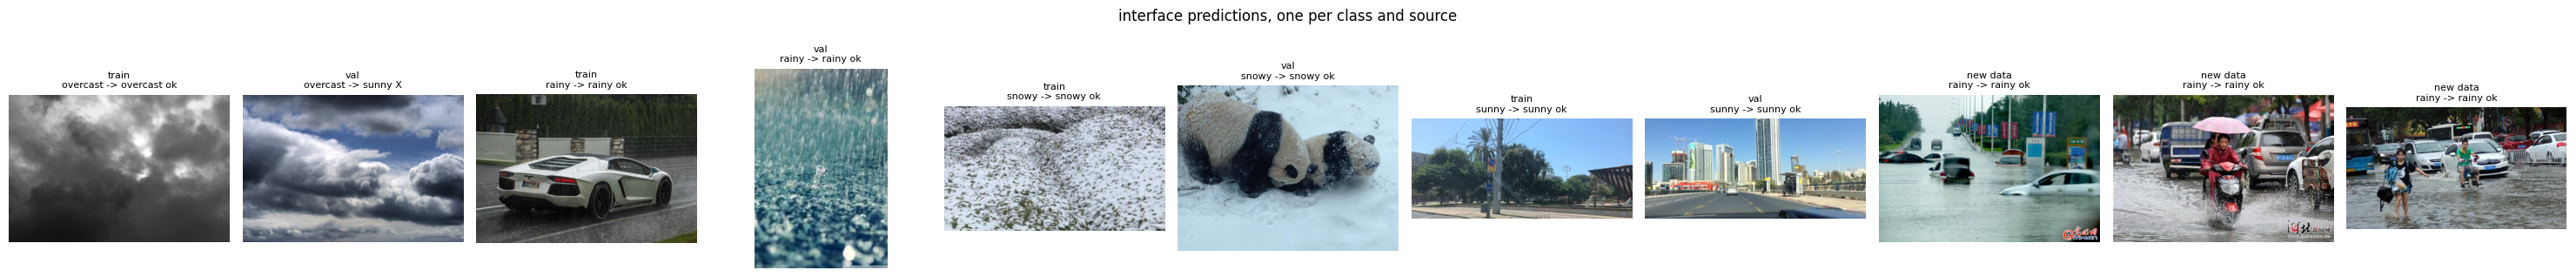

空輸入已被 gr.Error 拒絕： '請先選擇一張圖片。'


In [35]:
# 7.2 各類別的介面測試。作業要求對每個類別都顯示圖片、預期標籤與實際結果，
# 並說明每張圖是訓練、驗證或新資料。這裡直接呼叫 callback，讓證據被存進
# notebook，而不是只出現在畫面上。
import hashlib

NEW_DATA_DIR = (W.ROOT / "datasets" / "raw" / "weather-recognition"
                / "dataset" / "rain")
NEW_DATA_LABEL = "rainy"      # 該資料夾從未納入四類分割


def _load_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"))


def interface_cases():
    rows = []
    for label in sorted(train_df["label"].unique()):
        for source, frame in (("train", train_df), ("val", val_df)):
            block = frame[frame["label"] == label]
            if block.empty:
                continue
            rows.append((source, label,
                         Path(str(block["path"].iat[0]))))
    if NEW_DATA_DIR.is_dir():
        unseen = [Path(p) for p in sorted(NEW_DATA_DIR.iterdir())
                  if p.suffix.lower() in W.IMAGE_EXT][:3]
        # 「新資料」必須代表模型從未見過，所以要證明：這些檔案不能有任何
        # 一份是分割中某張圖的完全相同副本。
        known = set(train_df["md5"]) | set(val_df["md5"])
        copies = sum(hashlib.md5(p.read_bytes()).hexdigest() in known
                     for p in unseen)
        print(f"新資料檢查：{len(unseen)} 個檔案來自 {NEW_DATA_DIR.name}/"
              f"，其中已是分割內完全相同副本的：{copies}")
        for path in unseen:
            rows.append(("new data", NEW_DATA_LABEL, path))
    return rows


if deployed_model is None:
    print("[待完成] 模型尚未訓練 —— 請先執行第 6 節")
else:
    cases = interface_cases()
    prints = []
    for source, expected, path in cases:
        # 直接傳路徑：callback 內走 read_model_input，與 make_dataset 同一條解碼路徑。
        scores = predict_image(str(path))
        # dict.get 回傳 float | None；None 無法比較，所以明確用索引取值，
        # 並由上方對空字典的檢查來保護 max()。
        best = max(scores, key=lambda k: scores[k]) if scores else "(none)"
        prints.append({"source": source, "expected": expected,
                       "file": path.name, "predicted": best,
                       "probability": round(scores.get(best, 0.0), 3),
                       "correct": best == expected})

    table = pd.DataFrame(prints)
    display(table)
    print("涵蓋的類別數：", table["expected"].nunique(),
          "/", train_df["label"].nunique(),
          "| 資料來源：", sorted(table["source"].unique()))
    print("在這組少量人工挑選樣本上的準確率：",
          f"{table['correct'].mean():.1%}")

    fig, axes = plt.subplots(1, len(cases), figsize=(2.7 * len(cases), 3.2))
    axes = np.atleast_1d(axes)
    for ax, (source, expected, path), row in zip(axes, cases, prints):
        ax.imshow(_load_rgb(path))
        mark = "ok" if row["correct"] else "X"
        ax.set_title(f"{source}\n{expected} -> {row['predicted']} {mark}",
                     fontsize=8)
        ax.axis("off")
    fig.suptitle("interface predictions, one per class and source")
    fig.tight_layout()
    plt.show()

    # 空輸入必須被可讀的訊息拒絕，而不是丟出 traceback
    try:
        predict_image(None)
    except gr.Error as err:
        print("空輸入已被 gr.Error 拒絕：", err)
    else:
        print("警告：空輸入沒有被拒絕")


##### 7.3 Loader vs Callback（同一張圖、兩條路徑、同樣的機率）

3.4b 比對的是「模型收到的張量」。這裡比對的是**答案**：同一張圖分別走
`make_dataset`（訓練／驗證用的 loader）與 Gradio callback `predict_image`，
印出兩邊的完整機率向量與最大差距。若兩個路徑真的共用同一套前處理，
差距應為 0.0，預測類別也必然相同。

In [36]:
# 7.3 同一張圖，loader 與 Gradio callback 必須給出同一組機率。
if deployed_model is None:
    print("[待完成] 模型尚未訓練 —— 請先執行第 6 節")
else:
    probe = pd.concat([train_df.head(2), val_df.head(2)], ignore_index=True)
    rows = []
    for _, row in probe.iterrows():
        path, label = str(row["path"]), str(row["label"])
        one = pd.DataFrame({"path": [path], "label": [label]})
        batch, _ = next(iter(W.make_dataset(one, deployed_spec, batch_size=1)))
        from_loader = np.asarray(
            deployed_model.predict(np.asarray(batch), verbose=0)[0])
        scores = predict_image(path)
        from_ui = np.array([scores[name] for name in W.CLASS_ORDER],
                           dtype="float32")
        rows.append({
            "source": "val" if path in set(val_df["path"].astype(str)) else "train",
            "file": Path(path).name,
            "loader argmax": W.CLASS_ORDER[int(from_loader.argmax())],
            "callback argmax": W.CLASS_ORDER[int(from_ui.argmax())],
            "loader p(max)": round(float(from_loader.max()), 6),
            "callback p(max)": round(float(from_ui.max()), 6),
            "max |diff|": round(float(np.abs(from_loader - from_ui).max()), 8),
        })

    same_answer = pd.DataFrame(rows)
    display(same_answer)
    print("兩條路徑的最大機率差距（整批）：",
          round(float(same_answer["max |diff|"].max()), 8))
    assert (same_answer["loader argmax"] == same_answer["callback argmax"]).all(), \
        "loader 與 callback 的預測類別不同 —— 前處理路徑又分岔了"
    assert float(same_answer["max |diff|"].max()) < 1e-6, \
        "loader 與 callback 的機率差距過大 —— 前處理路徑又分岔了"
    print("結論：兩條路徑的類別相同、機率差距 < 1e-6，即同一張圖得到同一個答案。")

,source,file,loader argmax,callback argmax,loader p(max),callback p(max),max |diff|
0,train,cloudy1.jpg,overcast,overcast,0.990879,0.990879,0.0
1,train,cloudy102.jpg,overcast,overcast,0.716812,0.716812,0.0
2,val,cloudy147.jpg,sunny,sunny,0.836747,0.836747,0.0
3,val,cloudy148.jpg,overcast,overcast,0.772882,0.772882,0.0


兩條路徑的最大機率差距（整批）： 0.0
結論：兩條路徑的類別相同、機率差距 < 1e-6，即同一張圖得到同一個答案。


## 8. Video Inference（影片推論）

四個分開評分的影片元件：主要天氣預測、其主要天氣 Gradio 介面、天氣變化預測，以及其天氣變化 Gradio 介面。

**AI 使用（本節）。** 工具：GitHub Copilot agent。影片取樣、逐幀推論、
標註輸出與時間軸的程式碼由它起草，`weather_lib.annotate_video` 也在其中。

* **採用**：沿用同一個 `spec.fn` 前處理契約（8.1 節），以及把每一幀的機率向量
  **取平均**後報告最大值類別（而不是多數投票），因為平均保留了信心資訊。
* **AI 修掉的一個真實缺陷**：輸出的 MP4 原本用 `mp4v` 編碼，OpenCV 寫得出來、
  但 VS Code 的播放器打不開（老師提供的範例影片可以播，所以不是播放器的問題）。
  AI 改成優先嘗試 `avc1`/H.264（透過 Media Foundation），失敗才退回 `mp4v`，
  並把輸出影片讀回來逐幀解碼驗證（主要天氣 270 幀、`video2` 192/192、
  `common-changing-weather` 690/690，見 8.4b 的表格）。
  這個缺陷是我實際播放時發現、回報後由 AI 修的。
* **規格對照**：作業要求「每 N 幀推論，1 <= N <= 5，N 為參數」，所以它是
  `N` 可調而不是固定間隔；8.4b 節的煙霧測試就是在驗證 `N` 超出 1–5 時真的被拒絕、
  而合法的呼叫回傳的時間軸間距與影片幀率相符。
* **評語抓到、我自己漏掉的一個 bug（取樣間隔方向寫反）**：舊版滑桿是 1.0–3.0 秒，
  而 guard clause 拒絕**小於** 1 秒的間隔 —— 兩者都與「至少每秒一次」相反，
  那句話的意思是間隔**不得大於** 1 秒。現在 `analyse_video` 只接受
  `0 < interval <= 1.0`，滑桿上限就是 1.0 秒，下限 0.25 秒讓「比每秒一次更密」
  的設定也測得到；8.2b 兩個方向都驗：3.0 / 1.5 / 0.0 秒被拒絕，1.0 與 0.5 秒被接受，
  且回傳表格的實際最大間距都 <= 1.0 秒。這是 AI 產出的程式碼裡一個**方向性**的錯誤，
  型式上「有做驗證」，但驗的是反過來的那一側。
* **驗證**：8.2b / 8.4b 的煙霧測試不開視窗、直接呼叫 callback，
  確認空輸入被拒絕、8.2 的間隔上限真的被強制執行、真實影片回傳的四個物件形狀正確、
  平均分總和為 1。8.2b 另外把主要天氣介面拿去跑兩支變化影片，而不只是晴天片段。
* **一個還沒解決的問題**：晴天片段的平均分數仍以 snowy（43.7%）
  高於 sunny（31.5%），同時這支影片逐取樣點的標籤也在三個類別之間來回跳。
  這是模型實際的行為，不是取樣或平均程式的錯。8.1 節用水平切帶實驗查了它的來源
  （snowy 不是任何單一區域造成的，是整體版面），結論與 6.4.3 量到的「判斷依據是
  畫面構成」一致。

## 資料集狀態

本節使用第 6.6 節選出的部署模型，其驗證準確率見該節的比較表。
影片推論沿用完全相同的前處理契約（`spec.fn`），因此畫面數值分佈與訓練時一致。

In [37]:
# 第 8 節 — 影片推論：先列出清單，這樣一眼就能看出哪支是主要影片、
# 哪支展示了天氣變化。
clips = []
for path in sorted(W.VIDEO_ROOT.glob("*.mp4")):
    info = W.video_info(path)
    clips.append({"file": path.name, "fps": round(info["fps"], 2),
                  "frames": info["frames"], "seconds": round(info["duration_s"], 2),
                  "size": f"{info['width']}x{info['height']}"})
display(pd.DataFrame(clips))
MAIN_CLIP = W.VIDEO_ROOT / "main-weather-sunny.mp4"
CHANGE_CLIP = W.VIDEO_ROOT / "video2.mp4"
print("主要影片：", MAIN_CLIP.name, "存在：", MAIN_CLIP.exists())
print("變化影片：", CHANGE_CLIP.name, "存在：", CHANGE_CLIP.exists())


,file,fps,frames,seconds,size
0,annotated-weather-example.mp4,24.0,192,8.0,1280x720
1,common-changing-weather.mp4,30.0,690,23.0,1280x720
2,main-weather-sunny.mp4,30.0,270,9.0,1280x720
3,video2.mp4,24.0,192,8.0,1280x720


主要影片： main-weather-sunny.mp4 存在： True
變化影片： video2.mp4 存在： True


### 8.1 Main Weather Prediction（主要天氣預測）

至少每秒取樣整段影片一次，顯示取樣的影格（frame）、時間戳（timestamp）與類別機率（class probability），對機率向量取平均並報告平均值最大的類別。

**評語的兩個要求分別回應。** 第一句是「抽樣的影格沒有顯示出來」—— 下面第一張圖就是模型實際看到的那 9 幀，與機率表逐列對齊。第二句是「晴天片段被判成 snowy，只以 43.7% 對 31.5% 險勝 sunny，沒有足夠調查」—— 本節末尾用水平切帶實驗查它的來源。

**抽樣幀。** 抽樣走 `W.sample_frames(MAIN_CLIP, 1.0)`，與 `annotate_video` 用同一個 `every_seconds=1.0`，所以圖上的幀**就是**送進模型的那 9 幀，不是另外解碼一次的另一批。每格標題是該幀的 argmax 與最高機率。

**逐幀與平均。** 9 個取樣點的平均是 snowy 0.4368、sunny 0.3150、rainy 0.2434、overcast 0.0048，回報 snowy，領先 sunny 12.2 個百分點。但逐幀的 argmax 是 **sunny 3 次、rainy 1 次、snowy 5 次** —— 這支影片在單幀層級就已經不穩定，平均只是把 5:3:1 的多數放大成一個標籤。多數投票（5/9）也會得到 snowy，所以問題不在「平均 vs 投票」的選擇，在模型本身的判斷。

**為什麼被判成 snowy：兩個假設，一個被否定。**

*假設 A：模型看的是下半部的水面與礫石灘（白色石頭在 224×224 下像雪），不是天空。* 用水平切帶對照檢驗：對 9 幀各自只餵「上 40%」與「下 60%」，其餘一律不動（同一條 `read_model_input` → `spec.fn` → `predict`）。

結果**否定假設 A**：下半部單獨看是 **rainy 0.7459**、snowy 0.2199、sunny 0.0246。也就是說「水面與礫石」被讀成雨天，不是雪天；而單獨的上 40% 給 sunny 0.3499 / snowy 0.3300，兩者幾乎打平，也生不出 snowy。**沒有任何一個水平帶單獨能產生 snowy。**

*假設 B：snowy 是整體構圖造成的，不是任何局部特徵。* 把中間 20% 的橫條（對岸的暗色樹線）移除、上 40% 與下 60% 直接接起來，其餘條件不變：snowy 從 **0.4368 跳到 0.7709**，sunny 掉到 0.0838。

一條橫條的有無就讓 snowy 幾乎翻倍，而兩個局部都給不出 snowy —— 所以這個判斷是**構圖驅動**的：亮天空在上、亮斑點的水面在下、中間一條暗樹線，這個版面與訓練資料裡的雪景版面同構。像素組成支持這一點：藍天只佔全片 **17.2%–22.7%**（中位數 21.9%），近白像素僅 1.5%–2.5%，其中 2.4%–4.1% 落在 40% 線以下（礫石與水花）。「晴天」最直接的證據（藍天）在這支影片裡不到畫面的四分之一，而且畫面剩下的部分（暗樹線、帶白斑的水面）在模型眼中更像冬季場景。

**這與 6.4.3 的結論是同一個原因。** 該節量到增強關閉時驗證準確率反而高 8.2 個百分點，解釋是這份資料集的判別依據很大程度是「畫面構成」（sky 在上、ground 在下、雪是白色大面積），而模型容量不足以學會不受版面影響的特徵。8.1 的切帶實驗是同一件事在單支影片上的具體量測。

**限制，以及為什麼沒有繼續往下修。** 這是單支影片上的介入實驗（移除一條橫條），它能證明**決策依賴構圖且對構圖極度敏感**，不能證明訓練集中雪景版面的具體比例。要真正修好需要重做資料集（評語列為 −1% 的項目：每個類別都要有實景街道、公園、建築，且各類來源與場景要相當），這不在本次修訂的範圍內。這裡做的是把「模型就是這樣」換成一個可重現、可被否證的量測。

{'output': 'C:\\Users\\honok\\Desktop\\cis341\\Project_1-Weather_Classification\\Reports\\main-weather-annotated.mp4', 'frames_written': 270, 'fps': 30.0, 'predictions': 9, 'interval_s': 1.0, 'class_order': ['sunny', 'overcast', 'rainy', 'snowy'], 'mean_scores': {'sunny': 0.31497492558426327, 'overcast': 0.004835817529561205, 'rainy': 0.2433598753478792, 'snowy': 0.436829353372256}, 'main_label': 'snowy'}


抽樣幀數：9 | 與標註影片使用同一批時間戳：True


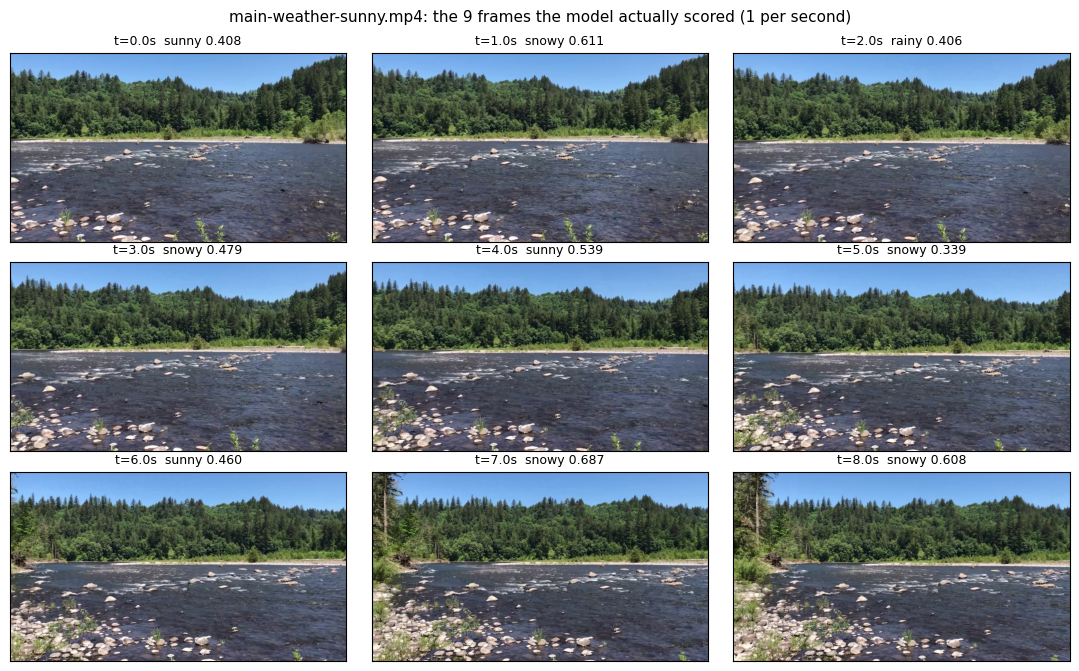

每個取樣點的機率：


,time_s,sunny,overcast,rainy,snowy,argmax
0,0.0,0.408,0.002,0.299,0.292,sunny
1,1.0,0.078,0.001,0.311,0.611,snowy
2,2.0,0.345,0.005,0.406,0.244,rainy
3,3.0,0.232,0.004,0.285,0.479,snowy
4,4.0,0.539,0.008,0.226,0.227,sunny
5,5.0,0.330,0.008,0.324,0.339,snowy
6,6.0,0.460,0.007,0.088,0.445,sunny
7,7.0,0.183,0.005,0.126,0.687,snowy
8,8.0,0.261,0.005,0.126,0.608,snowy


取樣點數： 9 | 間隔： 1.0 秒 （作業要求：至少每秒一次）
逐幀 argmax 的分佈： {'snowy': 5, 'sunny': 3, 'rainy': 1}
所有取樣點平均後的類別分數：


,mean probability
snowy,0.4368
sunny,0.3150
rainy,0.2434
overcast,0.0048


回報的主要天氣： snowy （平均 43.7%）


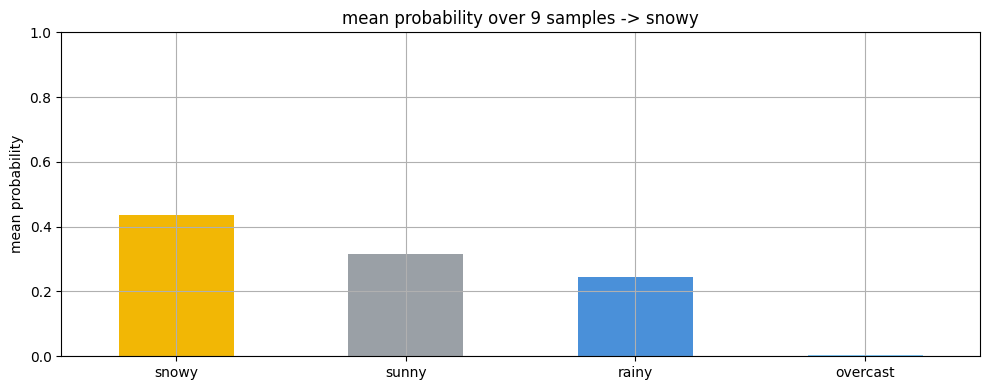

已標註影片： Reports\main-weather-annotated.mp4


水平切帶對照（9 幀平均，其餘條件不變）：


,區域,sunny,overcast,rainy,snowy,argmax
0,完整幀,0.3150,0.0048,0.2434,0.4368,snowy
1,上 40%（天空＋樹線）,0.3499,0.0609,0.2591,0.3300,sunny
2,下 60%（水面＋礫石）,0.0246,0.0096,0.7459,0.2199,rainy
3,上 40%＋下 60%（移除中間暗樹線）,0.0838,0.0049,0.1404,0.7709,snowy
4,上 1/3,0.4721,0.0861,0.1893,0.2525,sunny
5,中 1/3,0.1299,0.0045,0.5339,0.3317,rainy
6,下 1/3,0.0194,0.0058,0.6665,0.3083,rainy


像素組成（佔整幀比例）：


,t,藍天比例,近白比例,近白比例（40% 線以下）
0,0.0,0.226,0.015,0.024
1,1.0,0.219,0.016,0.027
2,2.0,0.227,0.016,0.027
3,3.0,0.221,0.018,0.029
4,4.0,0.211,0.018,0.029
5,5.0,0.223,0.021,0.034
6,6.0,0.204,0.023,0.039
7,7.0,0.175,0.023,0.039
8,8.0,0.172,0.025,0.041


藍天比例 0.172–0.227（中位數 0.219）| 近白 0.015–0.025（中位數 0.018）
讀法：完整幀的 snowy 分數 0.4368；只留上 40% 時 snowy 0.3300、sunny 0.3499；
      只留下 60% 時 snowy 0.2199、rainy 0.7459；把中間暗樹線移除、讓天空直接接上水面，snowy 變成 0.7709。
      → 單獨的任一區域都生不出 snowy，snowy 是整體版面造成的。


In [38]:
# 8.1 主要天氣預測。作業要求：整段影片至少每秒取樣一次，然後對機率向量
# 取「平均」，報告平均值最大的類別。標註後的影片會在兩次模型呼叫之間保留
# 最新的預測結果，因此每一個原始影格都不會遺失。
if deployed_model is not None and MAIN_CLIP.exists():
    out_main = W.REPORT_ROOT / "main-weather-annotated.mp4"
    summary = W.annotate_video(MAIN_CLIP, out_main, deployed_model, deployed_spec,
                               labels=W.CLASS_ORDER, every_seconds=1.0)
    print({k: v for k, v in summary.items()
           if k not in ("timeline", "prob_matrix", "timestamps")})

    # 評語要求「顯示抽樣的影格」。這裡特別用與 annotate_video 相同的取樣函式與
    # 間隔，讓圖上的幀就是送進模型評分的那幾幀，而不是另外解碼出來的另一批。
    sampled = W.sample_frames(MAIN_CLIP, 1.0)
    same_stamps = np.allclose([t for t, _ in sampled], summary["timestamps"])
    print(f"抽樣幀數：{len(sampled)} | 與標註影片使用同一批時間戳：{same_stamps}")

    order = summary["class_order"]
    fig, axes = plt.subplots(3, 3, figsize=(11.0, 6.8))
    for ax, (stamp, frame), probs in zip(axes.ravel(), sampled,
                                         summary["prob_matrix"]):
        j = int(np.argmax(probs))
        ax.imshow(frame)
        ax.set_title(f"t={stamp:.1f}s  {order[j]} {probs[j]:.3f}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    # 圖內文字一律用英文：matplotlib 內建字型沒有中文字模，硬寫會變成方框。
        fig.suptitle(f"{MAIN_CLIP.name}: the {len(sampled)} frames the model "
                     f"actually scored (1 per second)", fontsize=11)
    fig.tight_layout()
    plt.show()

    per_frame = pd.DataFrame(summary["prob_matrix"], columns=order)
    per_frame.insert(0, "time_s", np.round(summary["timestamps"], 2))
    per_frame["argmax"] = per_frame[order].idxmax(axis=1)
    print("每個取樣點的機率：")
    display(per_frame.round(3))
    print("取樣點數：", len(per_frame), "| 間隔：", summary["interval_s"], "秒",
          "（作業要求：至少每秒一次）")
    print("逐幀 argmax 的分佈：",
          dict(per_frame["argmax"].value_counts()))

    mean = pd.Series(summary["mean_scores"]).sort_values(ascending=False)
    print("所有取樣點平均後的類別分數：")
    display(mean.round(4).to_frame("mean probability"))
    print("回報的主要天氣：", summary["main_label"],
          f"（平均 {mean.iloc[0] * 100:.1f}%）")

    ax = mean.plot.bar(color=["#f2b705", "#9aa0a6", "#4a90d9", "#7fc8f8"],
                       rot=0)
    ax.set_title(f"mean probability over {len(per_frame)} samples "
                 f"-> {summary['main_label']}")
    ax.set_ylabel("mean probability")
    ax.set_ylim(0, 1.0)
    plt.tight_layout()
    plt.show()
    print("已標註影片：", out_main.relative_to(W.ROOT))

    # ---- 為什麼被判成 snowy：區域對照 ----------------------------------
    # 假設 A：模型看的是下半部的水面與礫石灘，而不是天空。
    # 測法：只餵某一個水平帶，其餘條件（前處理、模型、類別順序）完全不動。
    def _probe(rgb):
        arr = W.to_model_input([np.ascontiguousarray(rgb)],
                               deployed_spec.image_size)
        arr = np.asarray(deployed_spec.fn(np.asarray(arr, dtype="float32")))
        return deployed_model.predict(arr, verbose=0)[0]

    def _regions(frame):
        h = frame.shape[0]
        third = h // 3
        top, bottom = frame[: int(h * 0.4)], frame[int(h * 0.6):]
        return {
            "完整幀": frame,
            "上 40%（天空＋樹線）": top,
            "下 60%（水面＋礫石）": bottom,
            "上 40%＋下 60%（移除中間暗樹線）": np.concatenate([top, bottom], axis=0),
            "上 1/3": frame[:third],
            "中 1/3": frame[third:2 * third],
            "下 1/3": frame[2 * third:],
        }

    region_names = list(_regions(sampled[0][1]))
    region_probs = {name: [] for name in region_names}
    for _, frame in sampled:
        regions = _regions(frame)
        for name in region_names:
            region_probs[name].append(_probe(regions[name]))

    region_table = pd.DataFrame(
        [[name] + list(np.mean(region_probs[name], axis=0))
         for name in region_names],
        columns=["區域"] + order)
    region_table["argmax"] = region_table[order].idxmax(axis=1)
    print("水平切帶對照（9 幀平均，其餘條件不變）：")
    display(region_table.round(4))

    # 像素組成：這支影片裡「晴天」的證據到底佔多少畫面。
    comp_rows = []
    for stamp, frame in sampled:
        px = frame.astype(int)
        h = frame.shape[0]
        comp_rows.append({
            "t": round(stamp, 1),
            "藍天比例": float(((px[:, :, 2] > 110)
                              & (px[:, :, 2] - px[:, :, 0] > 25)).mean()),
            "近白比例": float((px.min(axis=2) > 200).mean()),
            "近白比例（40% 線以下）": float((px[int(h * 0.4):].min(axis=2) > 200).mean()),
        })
    comp = pd.DataFrame(comp_rows)
    print("像素組成（佔整幀比例）：")
    display(comp.round(3))
    print(f"藍天比例 {comp['藍天比例'].min():.3f}–{comp['藍天比例'].max():.3f}"
          f"（中位數 {comp['藍天比例'].median():.3f}）| "
          f"近白 {comp['近白比例'].min():.3f}–{comp['近白比例'].max():.3f}"
          f"（中位數 {comp['近白比例'].median():.3f}）")

    _full = region_table.loc[region_table["區域"] == "完整幀"].iloc[0]
    _top = region_table.loc[region_table["區域"] == "上 40%（天空＋樹線）"].iloc[0]
    _bottom = region_table.loc[region_table["區域"] == "下 60%（水面＋礫石）"].iloc[0]
    _stitch = region_table.loc[
        region_table["區域"] == "上 40%＋下 60%（移除中間暗樹線）"].iloc[0]
    print("讀法：完整幀的 snowy 分數 %.4f；只留上 40%% 時 snowy %.4f、"
              "sunny %.4f；" % (_full["snowy"], _top["snowy"], _top["sunny"]))
    print("      只留下 60%% 時 snowy %.4f、rainy %.4f；把中間暗樹線移除、"
          "讓天空直接接上水面，snowy 變成 %.4f。"
          % (_bottom["snowy"], _bottom["rainy"], _stitch["snowy"]))
    print("      → 單獨的任一區域都生不出 snowy，snowy 是整體版面造成的。")
else:
    print("[待完成] 需要有已訓練的模型與主要影片")

### 8.2 Main Weather Gradio Interface（主要天氣 Gradio 介面）

接受影片並顯示其主要天氣與四個平均類別分數。


In [39]:
# 8.2 主要影片的 Gradio 介面：回傳標註後的影片、每個取樣點的表格，
# 以及四個「平均後」的類別分數（以 gr.Label 呈現）。
#
# 取樣間隔的方向原本寫反了：舊版滑桿允許 1.0–3.0 秒，還拒絕小於 1 秒的間隔。
# 「至少每秒一次」的意思是**間隔不得大於 1 秒**，所以上限必須是 1.0 秒，
# 而 0.5 秒（每秒兩次）這種更密的取樣應該被接受。
MAX_INTERVAL_S = 1.0


def analyse_video(video_path, interval=MAX_INTERVAL_S):
    if deployed_model is None:
        raise gr.Error("模型尚未訓練。")
    if not video_path:
        raise gr.Error("請上傳一支影片。")
    interval = float(interval)
    if not 0 < interval <= MAX_INTERVAL_S:
        raise gr.Error(f"取樣間隔必須大於 0 且不大於 {MAX_INTERVAL_S} 秒"
                       f"（作業要求：至少每秒一次），收到 {interval} 秒。")
    # 不同影片寫不同檔名，避免後一次呼叫把前一次的輸出覆蓋掉。
    dst = W.REPORT_ROOT / f"gradio-annotated-{Path(video_path).stem}.mp4"
    summary = W.annotate_video(video_path, dst, deployed_model, deployed_spec,
                               labels=W.CLASS_ORDER, every_seconds=interval)
    table = pd.DataFrame(np.round(summary["prob_matrix"], 3),
                         columns=[f"p_{c}" for c in summary["class_order"]])
    table.insert(0, "time_s", np.round(summary["timestamps"], 2))
    table.insert(1, "prediction", [n for _, n, _ in summary["timeline"]])
    summary_text = (f"取樣間隔 {interval:.2f} 秒（每秒 {1 / interval:.2f} 次，"
                    f"共 {len(table)} 個取樣點）\n"
                    f"主要天氣：{summary['main_label']}  |  "
                    + "  ".join(f"{k}: {v * 100:.1f}%"
                                for k, v in summary["mean_scores"].items()))
    return str(dst), table, summary["mean_scores"], summary_text


video_demo = gr.Interface(
    fn=analyse_video,
    inputs=[gr.Video(label="影片"),
            gr.Slider(0.25, MAX_INTERVAL_S, value=MAX_INTERVAL_S, step=0.25,
                      label="兩次預測之間的秒數（上限 1.0 秒 = 至少每秒一次）")],
    outputs=[gr.Video(label="標註後的輸出"),
             gr.Dataframe(label="每個取樣點的機率"),
             gr.Label(num_top_classes=4, label="平均類別分數"),
             gr.Textbox(label="摘要")],
    title="Main-weather video interface",
)
video_demo.launch()

* Running on local URL:  http://127.0.0.1:7862


* To create a public link, set `share=True` in `launch()`.


### 8.2b Main-Weather Interface Smoke Test（主要天氣介面煙霧測試）

不開啟 Gradio 視窗，直接呼叫 callback，把取樣間隔的**兩側**都驗過：空輸入被拒絕；3.0、1.5、0.0 秒被拒絕（作業要求「至少每秒一次」＝間隔不得大於 1 秒，所以舊版 1.0–3.0 秒的滑桶本身就是錯的）；1.0 與 0.5 秒被接受，且回傳表格的實際最大間距 <= 1.0 秒、平均分總和為 1。

評語另一半是「只用晴天片段測過」，所以同一個 callback 也對兩支變化影片各跑一次，列出每支的主要天氣與前二名分數。

一個需要說清楚的結果：變化影片的平均分數本來就會分散（同一支影片裡有兩種天氣），所以「主要天氣」對這類影片不是有意義的描述 —— 這正是 8.3 採用逐取樣點標籤而非平均值的原因。

In [40]:
# 8.2b 主要影片介面煙霧測試（取樣間隔兩側都驗，並測不同天氣條件）
# 不開 Gradio 視窗，直接呼叫 callback。三件事要證明：
#   1. 空輸入被拒絕。
#   2. 間隔 > 1.0 秒被拒絕（作業要求「至少每秒一次」＝間隔不得大於 1 秒），
#      1.0 與 0.5 秒被接受，且回傳表格的實際最大間距 <= 1.0 秒。
#   3. 介面不只在晴天片段上測過，也在兩支變化影片上測過。
if deployed_model is None:
    print("[待完成] 模型尚未訓練 —— 請先執行第 6 節")
else:
    try:
        analyse_video(None)
    except gr.Error as err:
        print("空輸入已被 gr.Error 拒絕：", err)
    else:
        print("警告：空輸入沒有被拒絕")

    for bad in (3.0, 1.5, 0.0):
        try:
            analyse_video(str(MAIN_CLIP), bad)
        except gr.Error as err:
            print(f"間隔 {bad} 秒已被 gr.Error 拒絕：", err)
        else:
            print(f"警告：間隔 {bad} 秒竟然被接受")

    kept = None
    for good in (0.5, 1.0):          # 1.0 放最後，讓留下的檔案就是 1.0 的結果
        clip_path, table_out, scores_out, text_out = analyse_video(
            str(MAIN_CLIP), good)
        gaps = np.diff(table_out["time_s"].to_numpy())
        print(f"間隔 {good} 秒：取樣點 {len(table_out)} 個 | "
              f"實際最大間距 {float(gaps.max()):.3f} 秒（須 <= 1.0）| "
              f"每秒取樣 {1 / float(np.median(gaps)):.2f} 次")
        if good == 1.0:
            kept = (clip_path, table_out, scores_out, text_out)

    # 不同天氣條件：晴天片段之外，也把兩支變化影片交給同一個 callback。
    condition_clips = [("晴天（主要片段）", MAIN_CLIP),
                       ("變化（video2）", CHANGE_CLIP),
                       ("變化（common-changing-weather）",
                        W.VIDEO_ROOT / "common-changing-weather.mp4")]
    rows, detail = [], []
    for name, path in condition_clips:
        if not Path(path).exists():
            continue
        _, table_c, scores_c, _ = analyse_video(str(path), 1.0)
        ranked = sorted(scores_c.items(), key=lambda kv: -kv[1])
        rows.append({"片段": name, "檔案": Path(path).name,
                     "取樣點": len(table_c),
                     "主要天氣": ranked[0][0],
                     "第一名機率": round(ranked[0][1], 3),
                     "第二名": f"{ranked[1][0]} {ranked[1][1]:.3f}"})
        detail.append((name, ranked))
    display(pd.DataFrame(rows))
    print("不同條件的平均分數：")
    for name, ranked in detail:
        print(f"  {name}: " + "  ".join(f"{k} {v * 100:.1f}%" for k, v in ranked))

    clip_path, table_out, scores_out, text_out = kept
    print("回傳型別：", type(clip_path).__name__, type(table_out).__name__,
          type(scores_out).__name__, type(text_out).__name__)
    print("標註檔存在：", Path(clip_path).exists(),
          "| 取樣點數：", len(table_out),
          "| 評分類別數：", len(scores_out))
    display(table_out.head())
    print("平均分數：", {k: round(v, 4) for k, v in scores_out.items()})
    print("分數總和 =", round(sum(scores_out.values()), 6),
          "（每個影格都是 softmax，所以平均值總和必須為 1）")
    print("摘要列：", text_out)

空輸入已被 gr.Error 拒絕： '請上傳一支影片。'
間隔 3.0 秒已被 gr.Error 拒絕： '取樣間隔必須大於 0 且不大於 1.0 秒（作業要求：至少每秒一次），收到 3.0 秒。'
間隔 1.5 秒已被 gr.Error 拒絕： '取樣間隔必須大於 0 且不大於 1.0 秒（作業要求：至少每秒一次），收到 1.5 秒。'
間隔 0.0 秒已被 gr.Error 拒絕： '取樣間隔必須大於 0 且不大於 1.0 秒（作業要求：至少每秒一次），收到 0.0 秒。'


間隔 0.5 秒：取樣點 18 個 | 實際最大間距 0.500 秒（須 <= 1.0）| 每秒取樣 2.00 次


間隔 1.0 秒：取樣點 9 個 | 實際最大間距 1.000 秒（須 <= 1.0）| 每秒取樣 1.00 次


,片段,檔案,取樣點,主要天氣,第一名機率,第二名
0,晴天（主要片段）,main-weather-sunny.mp4,9,snowy,0.437,sunny 0.315
1,變化（video2）,video2.mp4,8,rainy,0.504,sunny 0.251
2,變化（common-changing-weather）,common-changing-weather.mp4,23,snowy,0.563,rainy 0.211


不同條件的平均分數：
  晴天（主要片段）: snowy 43.7%  sunny 31.5%  rainy 24.3%  overcast 0.5%
  變化（video2）: rainy 50.4%  sunny 25.1%  snowy 21.8%  overcast 2.6%
  變化（common-changing-weather）: snowy 56.3%  rainy 21.1%  sunny 19.1%  overcast 3.5%
回傳型別： str DataFrame dict str
標註檔存在： True | 取樣點數： 9 | 評分類別數： 4


,time_s,prediction,p_sunny,p_overcast,p_rainy,p_snowy
0,0.0,sunny,0.408,0.002,0.299,0.292
1,1.0,snowy,0.078,0.001,0.311,0.611
2,2.0,rainy,0.345,0.005,0.406,0.244
3,3.0,snowy,0.232,0.004,0.285,0.479
4,4.0,sunny,0.539,0.008,0.226,0.227


平均分數： {'sunny': 0.315, 'overcast': 0.0048, 'rainy': 0.2434, 'snowy': 0.4368}
分數總和 = 1.0 （每個影格都是 softmax，所以平均值總和必須為 1）
摘要列： 取樣間隔 1.00 秒（每秒 1.00 次，共 9 個取樣點）
主要天氣：snowy  |  sunny: 31.5%  overcast: 0.5%  rainy: 24.3%  snowy: 43.7%


### 8.3 Weather-Change Prediction（天氣變化預測）

對每一影格或每 N 個影格推論（1 <= N <= 5，N 為參數）。記錄預測與時間的對應。


In [41]:
# 8.3 天氣變化影片：密集取樣（最多相隔 5 個影格），然後報告預測標籤
# 實際發生變化的位置。
if deployed_model is not None and CHANGE_CLIP.exists():
    info = W.video_info(CHANGE_CLIP)
    step_s = 5.0 / (info["fps"] or 30.0)          # 取樣間隔 <= 5 個影格
    frames = W.sample_frames(CHANGE_CLIP, every_seconds=step_s)
    print("取樣影格數：", len(frames), " 間隔：", round(step_s, 3), "秒")

    probs, stamps = W.predict_frames(deployed_model, frames, deployed_spec)
    predicted = [W.CLASS_ORDER[int(np.argmax(p))] for p in probs]
    change_df = pd.DataFrame({"time_s": np.round(stamps, 2),
                              "prediction": predicted,
                              "probability": np.round(probs.max(axis=1), 3)})
    display(change_df.head(20))

    transitions = [(change_df.loc[i - 1, "time_s"], change_df.loc[i - 1, "prediction"],
                    change_df.loc[i, "time_s"], change_df.loc[i, "prediction"])
                   for i in range(1, len(change_df))
                   if change_df.loc[i, "prediction"] != change_df.loc[i - 1, "prediction"]]
    print("偵測到的變化次數：", len(transitions))
    for before_t, before, after_t, after in transitions:
        print(f"  {before} -> {after} 於 t={after_t}s")

    out_change = W.REPORT_ROOT / "changing-weather-annotated.mp4"
    summary = W.annotate_video(CHANGE_CLIP, out_change, deployed_model,
                               deployed_spec, labels=W.CLASS_ORDER,
                               every_seconds=step_s)
    print("已標註影片：", out_change.relative_to(W.ROOT),
          "| 預測結果：", summary["predictions"])
else:
    print("[待完成] 需要有已訓練的模型與變化影片")


取樣影格數： 39  間隔： 0.208 秒


,time_s,prediction,probability
0,0.00,rainy,0.590
1,0.21,rainy,0.905
2,0.42,rainy,0.823
3,0.62,rainy,0.714
4,0.83,rainy,0.661
5,1.04,sunny,0.533
6,1.25,sunny,0.639
7,1.46,rainy,0.589
8,1.67,sunny,0.584
9,1.88,rainy,0.710


偵測到的變化次數： 7
  rainy -> sunny 於 t=1.04s
  sunny -> rainy 於 t=1.46s
  rainy -> sunny 於 t=1.67s
  sunny -> rainy 於 t=1.88s
  rainy -> sunny 於 t=4.38s
  sunny -> rainy 於 t=4.58s
  rainy -> snowy 於 t=5.21s


已標註影片： Reports\changing-weather-annotated.mp4 | 預測結果： 39


### 8.3b 為什麼漏掉 Overcast、雪段內的標籤怎麼解釋

評語原話：*"explain the missed Overcast segment and incorrect labels within the snowy segment."* 下面五點全部對應到可重現的量測。**這一節的第一版解釋被自己的量測推翻了**（原本寫「天空帶單獨看就是 overcast」，實際量到天空帶 11/12 被判成 snowy），下面是修正後的版本。

**（1）`overcast` 從頭到尾沒有贏過任何一個取樣點。** 全片 39 個取樣點的 argmax 是 rainy 21、snowy 14、sunny 4，**沒有任何一格是 overcast**。而 `overcast` 機率最高的那一點是 0.2301 @ t=6.88s，落在**雪段**；真正烏雲壓頂的 1.88–4.38s，`overcast` 平均只有 **0.0051**、最高 0.0165。所以這不是「差一點」，是模型在這段影片裡完全沒有把 overcast 當成候選。

**（2）切帶實驗：模型看得到陰天的天空，但把它讀成雪。** 用與 8.1 完全相同的呼叫路徑（`read_model_input` → `spec.fn` → `predict`），對陰天段的 12 個取樣點各餵「上 40%（只有天空）」與「下 60%（只有街道車流）」：

| 區域 | overcast 平均 | overcast 最高 | argmax 分佈（陰天段 12 幀） |
|---|---|---|---|
| 完整幀 | 0.0051 | 0.0165 | rainy 11、sunny 1 |
| **上 40%（天空）** | **0.1387** | **0.2830** | **snowy 11**、sunny 1 |
| 下 60%（街道） | 0.0003 | 0.0008 | rainy 12 |

只留下天空，`overcast` 機率就升了 **27 倍**（0.0051 → 0.1387），所以模型**不是看不到陰天的天空**。但升上去之後仍然輸：天空帶的 argmax 有 11/12 是 **snowy** —— 灰白雲層的平坦紋理被讀成雪原。這與六類實驗裡 foggy 常被判成 sunny/overcast 是同一個現象：這個模型對「低對比度的平坦灰白區域」沒有可靠的類別解析度。

**（3）完整幀時地面把票數壓回去。** 下 60% 單獨看時 12/12 都是 rainy、平均機率 **0.9857**。天空帶給的是 snowy 0.14 等級的微弱訊號，地面給的是 rainy 0.99 等級的強訊號，合併後 rainy 勝出（平均 0.8349）。這與 8.1 在晴天影片上量到的是同一個機制：**下半部的地面決定標籤**。兩支影片、兩個相反方向（8.1 抬成 snowy、8.3 壓成 rainy）指向同一個結構性問題。

**（4）雪段內的錯標，修訂前後差在哪。** 修訂前提交的版本在 5.2–8.0s 之間把標籤換了三次（snowy → sunny → snowy → overcast），這就是評語講的 incorrect labels；那個版本用的是舊的強旋轉（0.15）與舊增強設定。本次修訂重訓後（第 5 項，旋轉 0.15 → 0.04），5.21–7.92s 的 **14 個取樣點連續全部**是 snowy，機率 0.8082–0.9940，而且天空帶與地面帶單獨看也都全部是 snowy—— 這是全片唯一一個「完整幀與兩個局部一致」的段落。這一節沒有為雪段單獨調任何東西，它是重訓的副作用。

**（5）代價：晴天段反而變差，以及為什麼不對輸出做平滑。** 新版把 0.00–0.83s 的強日照幀判成 rainy（修訂前判 sunny 0.84）。切帶分解又是同一個模式：t=0.00s 上 40% 單獨是 sunny 0.745，下 60% 是 rainy 0.833，合併後 rainy 0.590 勝出；晴天段的 5 幀裡天空帶全部是 sunny（5/5），完整幀卻全部是 rainy（5/5）。同一個權重讓雪段變穩、讓晴天段變差，兩件事一起發生，這是重訓的取捨而不是可以只挑一半的結果。這也不是取樣太疏造成的 —— 間隔 0.208 秒等於 5 個影格，符合作業「1 ≤ N ≤ 5」的要求。

可以對機率做時間平滑或多數投票，讓這支影片的標註看起來穩定得多。但那就不是模型真正的逐點輸出，也正好是這份作業要檢查的東西。這裡保留原始結果，並把它當成 6.4.3「判別依據是畫面構成」的第三個獨立案例：8.1 是同一機制在單一支晴天影片上，8.3b 是在有真實天氣變化的影片上。

In [42]:
# 8.3b 兩個漏判/錯標的解釋。probs 與 stamps 沿用 8.3（同一批取樣），
# 只有切帶實驗需要額外呼叫模型；呼叫路徑與 8.1 完全相同。
if deployed_model is not None and CHANGE_CLIP.exists():
    order = list(W.CLASS_ORDER)
    oC = order.index("overcast")
    ov = probs[:, oC]
    stamps = np.asarray(stamps)
    labs = [order[int(np.argmax(p))] for p in probs]

    # 這段影片的真實天氣分界是人工看每秒一幀的拼圖標出來的，
    # 不是從機率反推出來的。
    segments = [("晴天（有太陽）", 0.00, 0.90),
                ("陰天（烏雲壓頂）", 1.88, 4.38),
                ("雪天（白茫茫＋雪片）", 5.20, 8.00)]

    rows = []
    for name, t0, t1 in segments:
        m = (stamps >= t0 - 1e-9) & (stamps <= t1 + 1e-9)
        u, c = np.unique([L for L, k in zip(labs, m) if k], return_counts=True)
        rows.append({"真實天氣段": name, "秒數": f"{t0:.2f}–{t1:.2f}",
                     "取樣點": int(m.sum()),
                     "overcast 平均": round(float(ov[m].mean()), 4),
                     "overcast 最高": round(float(ov[m].max()), 4),
                     "argmax 分佈": str(dict(zip(u.tolist(), c.tolist())))})
    print("全片 argmax 分佈：", dict(zip(*[x.tolist() for x in np.unique(labs, return_counts=True)])),
          "→ 沒有任何一格是 overcast")
    print(f"overcast 機率最高的一點是 {ov.max():.4f} @ t={stamps[int(ov.argmax())]:.2f}s，"
          "落在雪段而不是陰天段：")
    display(pd.DataFrame(rows))

    # 切帶：把陰天段與晴天段的每一幀拆成「上 40% 天空」與「下 60% 街道」。
    def _probe(rgb):
        arr = W.to_model_input([np.ascontiguousarray(rgb)],
                               deployed_spec.image_size)
        arr = np.asarray(deployed_spec.fn(np.asarray(arr, dtype="float32")))
        return deployed_model.predict(arr, verbose=0)[0]

    # 8.3 的 frames 沒有留在變數裡，這裡重新解碼；間隔沿用 8.3 實測的時間戳差，
    # 並斷言時間戳完全一致，避免兩節量的不是同一批幀。
    step = float(np.median(np.diff(stamps)))
    seg_frames = W.sample_frames(CHANGE_CLIP, every_seconds=step)
    assert np.allclose([t for t, _ in seg_frames], stamps), "取樣時間戳與 8.3 不一致"

    band_rows = []
    for name, t0, t1 in (("陰天段", 1.88, 4.38), ("晴天段", 0.00, 0.90)):
        picked = [(t, f) for t, f in seg_frames if t0 - 1e-9 <= t <= t1 + 1e-9]
        parts = {"完整幀": [], "上 40%（天空）": [], "下 60%（街道）": []}
        for _, f in picked:
            h = f.shape[0]
            parts["完整幀"].append(_probe(f))
            parts["上 40%（天空）"].append(_probe(f[: int(h * 0.4)]))
            parts["下 60%（街道）"].append(_probe(f[int(h * 0.6):]))
        for region, arrs in parts.items():
            arrs = np.array(arrs)
            u, c = np.unique([order[int(np.argmax(a))] for a in arrs],
                             return_counts=True)
            band_rows.append({"段": name, "區域": region, "幀數": len(arrs),
                              "overcast 平均": round(float(arrs[:, oC].mean()), 4),
                              "overcast 最高": round(float(arrs[:, oC].max()), 4),
                              "argmax 分佈": str(dict(zip(u.tolist(), c.tolist())))})
    band_table = pd.DataFrame(band_rows)
    print("切帶對照（陰天段的天空帶 → overcast 機率升高，但 argmax 是 snowy）：")
    display(band_table)

    ov_seg = ov[(stamps >= 1.88 - 1e-9) & (stamps <= 4.38 + 1e-9)]
    sky = band_table[(band_table["段"] == "陰天段")
                     & (band_table["區域"] == "上 40%（天空）")].iloc[0]
    ground = band_table[(band_table["段"] == "陰天段")
                        & (band_table["區域"] == "下 60%（街道）")].iloc[0]
    print(f"陰天段完整幀 overcast 平均 {ov_seg.mean():.4f}；只留天空升到 "
          f"{sky['overcast 平均']:.4f}（{sky['overcast 平均'] / max(ov_seg.mean(), 1e-9):.0f} 倍），"
          f"但那一帶的 argmax 是 {sky['argmax 分佈']}。")
    print(f"同段只留下 60% 街道時 overcast 平均 {ground['overcast 平均']:.4f}、"
          f"argmax 是 {ground['argmax 分佈']} —— 地面用壓倒性的 rainy 把票數蓋掉。")

    # 雪段：連續 run 的長度與機率範圍（修訂前同一段換了三次標籤）。
    i = len(labs) - 1
    while i > 0 and labs[i] == "snowy":
        i -= 1
    run_start = i + 1
    sn = probs[:, order.index("snowy")]
    print(f"雪段：t={stamps[run_start]:.2f}–{stamps[-1]:.2f}s 共 {len(labs) - run_start} "
          f"個取樣點連續都是 snowy，機率 {sn[run_start]:.4f}–{sn[run_start:].max():.4f}。")

    flips = [(stamps[k - 1], labs[k - 1], stamps[k], labs[k])
             for k in range(1, len(labs)) if labs[k] != labs[k - 1]]
    fps = W.video_info(CHANGE_CLIP)["fps"]
    print(f"全片 {len(labs)} 個取樣點、間隔 {step:.3f}s（= {step * fps:.0f} 個影格，"
          f"符合作業 1 <= N <= 5），共 {len(flips)} 次標籤翻轉：")
    print("  " + " | ".join(f"{a}->{b} @{t:.2f}s" for _, a, t, b in flips))
else:
    print("[待完成] 需要有已訓練的模型與變化影片")

全片 argmax 分佈： {'rainy': 21, 'snowy': 14, 'sunny': 4} → 沒有任何一格是 overcast
overcast 機率最高的一點是 0.2301 @ t=6.88s，落在雪段而不是陰天段：


,真實天氣段,秒數,取樣點,overcast 平均,overcast 最高,argmax 分佈
0,晴天（有太陽）,0.00–0.90,5,0.0069,0.0146,{'rainy': 5}
1,陰天（烏雲壓頂）,1.88–4.38,12,0.0051,0.0165,"{'rainy': 11, 'sunny': 1}"
2,雪天（白茫茫＋雪片）,5.20–8.00,14,0.0688,0.2301,{'snowy': 14}


切帶對照（陰天段的天空帶 → overcast 機率升高，但 argmax 是 snowy）：


,段,區域,幀數,overcast 平均,overcast 最高,argmax 分佈
0,陰天段,完整幀,12,0.0051,0.0165,"{'rainy': 11, 'sunny': 1}"
1,陰天段,上 40%（天空）,12,0.1387,0.2830,"{'snowy': 11, 'sunny': 1}"
2,陰天段,下 60%（街道）,12,0.0003,0.0008,{'rainy': 12}
3,晴天段,完整幀,5,0.0069,0.0146,{'rainy': 5}
4,晴天段,上 40%（天空）,5,0.0509,0.0836,{'sunny': 5}
5,晴天段,下 60%（街道）,5,0.0015,0.0039,{'rainy': 5}


陰天段完整幀 overcast 平均 0.0051；只留天空升到 0.1387（27 倍），但那一帶的 argmax 是 {'snowy': 11, 'sunny': 1}。
同段只留下 60% 街道時 overcast 平均 0.0003、argmax 是 {'rainy': 12} —— 地面用壓倒性的 rainy 把票數蓋掉。
雪段：t=5.21–7.92s 共 14 個取樣點連續都是 snowy，機率 0.8082–0.9940。
全片 39 個取樣點、間隔 0.208s（= 5 個影格，符合作業 1 <= N <= 5），共 7 次標籤翻轉：
  rainy->sunny @1.04s | sunny->rainy @1.46s | rainy->sunny @1.67s | sunny->rainy @1.88s | rainy->sunny @4.38s | sunny->rainy @4.58s | rainy->snowy @5.21s


### 8.4 Weather-Change Gradio Interface（天氣變化 Gradio 介面）

接受影片並顯示標註後的輸出影片，或自訂的時間軸／長條圖（timeline / bar chart），指出天氣何時變化。

**評語指出這一節只回傳表格與文字**：程式其實已經產生標註影片，卻沒有從介面回傳，因此無法邊看畫面邊核對預測。修正後的 callback 一次回傳四樣東西：

| 輸出 | 內容 |
|---|---|
| `gr.Video` | 標註後的輸出影片（每一幀都在，兩次推論之間沿用上一個預測，與 8.1 相同） |
| `gr.Plot` | 時間軸：x 軸為秒、y 軸為四個類別的機率，紅色虛線標出標籤改變的位置 |
| `gr.Dataframe` | 每個取樣點的時間、預測類別、最高機率 |
| `gr.Textbox` | 變化清單，並列出**哪些類別從未被選上、它們的最高機率是多少** |

最後那一欄是給「漏掉某一段」用的：如果某個類別全片最高機率只有 13%，那「沒有偵測到它」就是模型信心不足，而不是時間軸對錯了 —— 8.4b 會把這個數字印出來。

In [43]:
# 8.4 天氣變化影片的 Gradio 介面。作業把取樣間隔上限訂在 5 個影格，
# 因此滑桿最大值為 5，callback 內也會再檢查一次。
# 評語指出這個介面只回傳表格與文字，沒有把程式**已經產生**的標註影片拿出來，
# 也沒有時間軸可以對照原片。所以 callback 現在一次回傳四樣東西：
# 標註後的影片、時間軸圖、逐取樣點表格、變化清單。
MAX_GAP_FRAMES = 5

CLASS_COLOURS = {"sunny": "#f2b705", "overcast": "#9aa0a6",
                 "rainy": "#4a90d9", "snowy": "#7fc8f8"}


def _change_timeline(summary):
    """Time on x, probability per class on y, dashed lines where the label flips."""
    stamps = np.asarray(summary["timestamps"], dtype=float)
    probs = np.asarray(summary["prob_matrix"], dtype=float)
    order = summary["class_order"]
    labels = [name for _, name, _ in summary["timeline"]]
    changes = [i for i in range(1, len(labels)) if labels[i] != labels[i - 1]]

    fig, ax = plt.subplots(figsize=(7.6, 2.9))
    for j, name in enumerate(order):
        ax.plot(stamps, probs[:, j], marker="o", ms=3, lw=1.4,
                color=CLASS_COLOURS.get(name), label=name)
    for i in changes:
        ax.axvline(stamps[i], color="#d64545", ls="--", lw=1, alpha=0.7)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("probability")
    ax.set_ylim(0, 1.02)
    ax.legend(ncol=len(order), fontsize=7, loc="upper center")
    ax.set_title(f"{len(stamps)} samples, {len(changes)} label changes "
                 f"(dashed lines)", fontsize=9)
    fig.tight_layout()
    return fig


def analyse_change(video_path, max_gap_frames=MAX_GAP_FRAMES):
    if deployed_model is None:
        raise gr.Error("模型尚未訓練。")
    if not video_path:
        raise gr.Error("請上傳一支影片。")
    gap = int(max_gap_frames)
    if not 1 <= gap <= MAX_GAP_FRAMES:
        raise gr.Error(f"每個取樣點之間請使用 1 到 {MAX_GAP_FRAMES} 個影格。")

    info = W.video_info(video_path)
    step_s = gap / (info["fps"] or 30.0)
    dst = W.REPORT_ROOT / f"change-annotated-{Path(video_path).stem}.mp4"
    # 同一趟就寫出標註影片，並取回逐取樣點的機率與標籤。
    summary = W.annotate_video(video_path, dst, deployed_model, deployed_spec,
                               labels=W.CLASS_ORDER, every_seconds=step_s,
                               hold_note=f"{gap} frame steps")

    stamps = np.round(np.asarray(summary["timestamps"], dtype=float), 2)
    probs = np.asarray(summary["prob_matrix"], dtype=float)
    predicted = [name for _, name, _ in summary["timeline"]]
    table = pd.DataFrame({"time_s": stamps, "prediction": predicted,
                          "probability": np.round(probs.max(axis=1), 3)})

    lines = [f"{predicted[i - 1]} -> {predicted[i]} 於 t={stamps[i]}s"
             for i in range(1, len(table)) if predicted[i] != predicted[i - 1]]
    # 哪些類別完全沒被選上、以及它們最高的機率是多少 —— 這是「漏掉某一段」的可檢查解釋。
    missed = []
    for j, name in enumerate(summary["class_order"]):
        if name in predicted:
            continue
        k = int(np.argmax(probs[:, j]))
        missed.append(f"{name} 從未被選為最高（全片最高 {probs[k, j] * 100:.1f}% "
                      f"於 t={stamps[k]}s）")
    header = (f"{Path(video_path).name}：每 {gap} 個影格取樣一次"
              f"（{step_s:.3f} 秒），共 {len(table)} 個取樣點，"
              f"偵測到 {len(lines)} 次標籤變化")
    body = "\n".join(lines) if lines else "未偵測到天氣變化"
    note = ("\n---\n" + "\n".join(missed)) if missed else ""
    return str(dst), _change_timeline(summary), table, header + "\n" + body + note


change_demo = gr.Interface(
    fn=analyse_change,
    inputs=[gr.Video(label="天氣變化影片"),
            gr.Slider(1, MAX_GAP_FRAMES, value=MAX_GAP_FRAMES, step=1,
                      label="兩次取樣之間的最大影格數（作業要求：1-5）")],
    outputs=[gr.Video(label="標註後的輸出影片"),
             gr.Plot(label="時間軸：每個取樣點的類別機率"),
             gr.Dataframe(label="每個取樣點的預測"),
             gr.Textbox(label="偵測到的變化", lines=8)],
    title="Weather-change interface",
)
change_demo.launch()

* Running on local URL:  http://127.0.0.1:7863


* To create a public link, set `share=True` in `launch()`.


### 8.4b Changing-Weather Interface Smoke Test（變化介面煙霧測試）

不開視窗、直接呼叫 callback，驗三件事：**(1)** 1–5 個影格的上限真的被強制執行（0 與 6 都被 `gr.Error` 拒絕）；**(2)** 回傳的四個物件形狀正確 —— 標註影片每一幀都解得開（影格數與原片相同）、時間軸圖有四條類別曲線與若干條變化虛線、表格的時間軸間距與影片幀率相符；**(3)** 不只在 `video2.mp4` 上跑，也在作業提供的 `common-changing-weather.mp4` 上跑。

兩支影片的取樣點數差很多（39 對 138），因為長度不同；「變化次數」也因此不能直接比。表格裡同時列出預期間距（`N / fps`）與實際中位數，這才是可以互相比對的欄位。

0 個影格的間隔已被 gr.Error 拒絕： '每個取樣點之間請使用 1 到 5 個影格。'
6 個影格的間隔已被 gr.Error 拒絕： '每個取樣點之間請使用 1 到 5 個影格。'



===== video2 =====
video2.mp4：每 5 個影格取樣一次（0.208 秒），共 39 個取樣點，偵測到 7 次標籤變化
rainy -> sunny 於 t=1.04s
sunny -> rainy 於 t=1.46s
rainy -> sunny 於 t=1.67s
sunny -> rainy 於 t=1.88s
rainy -> sunny 於 t=4.38s
sunny -> rainy 於 t=4.58s
rainy -> snowy 於 t=5.21s
---
overcast 從未被選為最高（全片最高 23.0% 於 t=6.88s）


,time_s,prediction,probability
0,0.00,rainy,0.590
1,0.21,rainy,0.905
2,0.42,rainy,0.823
3,0.62,rainy,0.714
4,0.83,rainy,0.661
5,1.04,sunny,0.533
6,1.25,sunny,0.639
7,1.46,rainy,0.589



===== common-changing-weather =====
common-changing-weather.mp4：每 5 個影格取樣一次（0.167 秒），共 138 個取樣點，偵測到 49 次標籤變化
sunny -> rainy 於 t=0.17s
rainy -> snowy 於 t=0.5s
snowy -> rainy 於 t=0.67s
rainy -> snowy 於 t=1.0s
snowy -> rainy 於 t=1.5s
rainy -> sunny 於 t=1.67s
sunny -> snowy 於 t=1.83s
snowy -> rainy 於 t=2.0s
rainy -> sunny 於 t=2.33s
sunny -> snowy 於 t=2.5s
snowy -> rainy 於 t=2.83s
rainy -> snowy 於 t=3.0s
snowy -> sunny 於 t=3.33s
sunny -> snowy 於 t=3.83s
snowy -> sunny 於 t=4.0s
sunny -> snowy 於 t=4.17s
snowy -> sunny 於 t=4.33s
sunny -> snowy 於 t=4.5s
snowy -> sunny 於 t=4.83s
sunny -> rainy 於 t=5.0s
rainy -> snowy 於 t=5.17s
snowy -> sunny 於 t=5.33s
sunny -> snowy 於 t=5.5s
snowy -> rainy 於 t=5.67s
rainy -> snowy 於 t=5.83s
snowy -> sunny 於 t=9.33s
sunny -> snowy 於 t=9.5s
snowy -> sunny 於 t=9.83s
sunny -> snowy 於 t=10.0s
snowy -> sunny 於 t=10.33s
sunny -> snowy 於 t=10.67s
snowy -> sunny 於 t=11.33s
sunny -> snowy 於 t=11.67s
snowy -> sunny 於 t=11.83s
sunny -> snowy 於 t=12.17s
snowy -> sunny 於 t=1

,time_s,prediction,probability
0,0.00,sunny,0.433
1,0.17,rainy,0.425
2,0.33,rainy,0.527
3,0.50,snowy,0.417
4,0.67,rainy,0.425
5,0.83,rainy,0.646
6,1.00,snowy,0.634
7,1.17,snowy,0.553


,clip,samples,expected gap (s),median gap (s),changes,annotated frames,returns 4 items,curve lines
0,video2,39,0.208,0.21,7,192/192,True,4
1,common-changing-weather,138,0.167,0.17,49,690/690,True,4


回傳型別： str Figure DataFrame str
折線（每個類別一條）： 4 | 虛線（標籤變化位置）： 49
標註影片可完整解碼： True


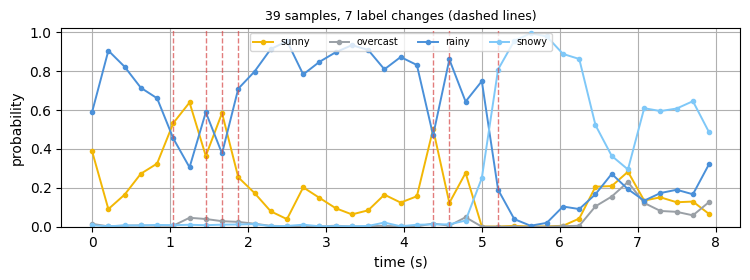

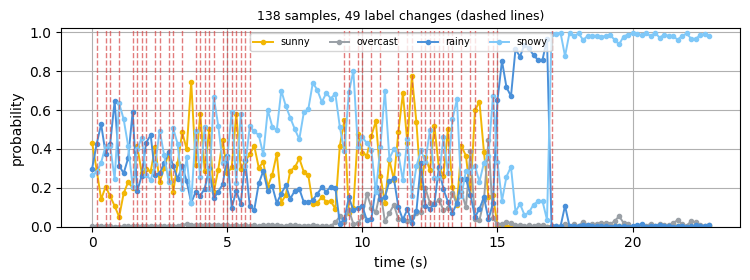

In [44]:
# 8.4b 變化介面的煙霧測試。三件事要證明：
#   1. 1–5 個影格的上限真的被強制執行（0 與 6 都被拒絕）。
#   2. 回傳的四個物件形狀正確：標註影片存在且每一幀都解得開、
#      時間軸是一張有資料的圖、表格的時間軸與影片幀率相符。
#   3. 不只在 video2 上跑過，也跑了作業提供的 common-changing-weather.mp4。
import cv2

if deployed_model is None:
    print("[待完成] 模型尚未訓練 —— 請先執行第 6 節")
else:
    for bad in (0, 6):
        try:
            analyse_change(str(CHANGE_CLIP), bad)
        except gr.Error as err:
            print(f"{bad} 個影格的間隔已被 gr.Error 拒絕：", err)
        else:
            print(f"警告：{bad} 個影格的間隔竟然被接受")

    clips = [("video2", CHANGE_CLIP),
             ("common-changing-weather",
              W.VIDEO_ROOT / "common-changing-weather.mp4")]
    rows = []
    for name, path in clips:
        if not Path(path).exists():
            print("跳過（檔案不存在）：", path)
            continue
        clip_out, fig, table, text = analyse_change(str(path), MAX_GAP_FRAMES)
        cap = cv2.VideoCapture(clip_out)
        decoded = 0
        while True:
            ok, _ = cap.read()
            if not ok:
                break
            decoded += 1
        cap.release()
        info = W.video_info(path)
        stamps = table["time_s"].to_numpy()
        rows.append({
            "clip": name,
            "samples": len(table),
            "expected gap (s)": round(MAX_GAP_FRAMES / info["fps"], 3),
            "median gap (s)": round(float(np.median(np.diff(stamps))), 3),
            "changes": len([1 for i in range(1, len(table))
                            if table["prediction"].iat[i]
                            != table["prediction"].iat[i - 1]]),
            "annotated frames": f"{decoded}/{info['frames']}",
            "returns 4 items": all(x is not None for x in
                                   (clip_out, fig, table, text)),
            "curve lines": len([ln for ln in fig.axes[0].lines
                                if ln.get_linestyle() != "--"]),
        })
        print(f"\n===== {name} =====")
        print(text)
        display(table.head(8))

    summary_df = pd.DataFrame(rows)
    display(summary_df)
    print("回傳型別：", type(clip_out).__name__, type(fig).__name__,
          type(table).__name__, type(text).__name__)
    curves = [ln for ln in fig.axes[0].lines if ln.get_linestyle() != "--"]
    dashes = [ln for ln in fig.axes[0].lines if ln.get_linestyle() == "--"]
    print("折線（每個類別一條）：", len(curves),
          "| 虛線（標籤變化位置）：", len(dashes))
    print("標註影片可完整解碼：",
          all(r["annotated frames"].split("/")[0]
              == r["annotated frames"].split("/")[1] for r in rows))

## 9. Six-Class Extension（六類別延伸）

把選定的方法延伸，以辨識另外兩種視覺上可區分的天氣狀況，每個新增類別至少 250 張原始影像。

**AI 使用（本節）。** 工具：GitHub Copilot agent。六類別的資料建置、輸出層調整、
`class_order_six.json` 與六類 Gradio 顯示由它起草。

* **採用**：完全重用四類別的管線，只把 `SIX` 類別清單加長 —— 這是把類別順序
  集中成一份契約的直接好處，程式碼幾乎沒有分叉。
* **拒絕（一處，重要）**：9.4 節原本從 `six_dedup`（訓練 + 驗證的完整索引）取每類
  第一張圖做介面示範。這 6 張裡有 **4 張是訓練圖片**，把它們當成「模型沒看過的
  範例」展示會誤導人（lightning 拿到 1.000 的分數就是這個原因）。
  改為只從 `split == "val"` 取圖之後，六張全對但分數落在 0.414–1.000，
  才是誠實的示範。
* **AI 另外實作的 `RETRAIN` 開關**（見 6.1.1）：`False` 時 9.2 節直接載入
  `mobilenet_v2_six.keras`，省下 20 個 epoch；`True` 時從資料重訓。
* **驗證**：9.3 節的混淆矩陣與四類／六類比較表是我執行的輸出；
  9.4 節的每一張預測是我在介面上實際跑出來的。


In [45]:
# 第 9 節 — 六類別延伸。額外兩個類別，選擇的理由是它們與原本四類、
# 以及彼此之間，在視覺上都能區分。
EXTRA = W.EXTRA_CLASSES
plan = pd.DataFrame([
    {"class": "foggy",
     "why separable": "對比被洗淡、沒有雨絲、遠處地標逐漸消失",
     "confusion risk": "overcast（兩者對比都低）—— 靠能見度區分，不是靠亮度"},
    {"class": "lightning",
     "why separable": "暗色天空中的明亮分叉閃電，或整片天空的閃光",
     "confusion risk": "overcast —— 只有看得到閃電或閃光時才標為 lightning"},
])
display(plan)

SIX = W.CLASS_ORDER + EXTRA
counts = W.scan_counts(SIX)
display(counts)
ready_six = bool((counts["count"] >= 250).all())
print("六個類別都已有 >= 250 張圖片：", ready_six)
if not ready_six:
    print("仍不足的類別：", counts.loc[counts["count"] < 250, "label"].tolist())


,class,why separable,confusion risk
0,foggy,對比被洗淡、沒有雨絲、遠處地標逐漸消失,overcast（兩者對比都低）—— 靠能見度區分，不是靠亮度
1,lightning,暗色天空中的明亮分叉閃電，或整片天空的閃光,overcast —— 只有看得到閃電或閃光時才標為 lightning


,label,count,distinct,duplicates,distinct_sizes,unreadable,meets_250,basis
0,sunny,341,341,0,136,0,True,raw files (no dedupe)
1,overcast,314,314,0,157,0,True,raw files (no dedupe)
2,rainy,287,287,0,181,0,True,raw files (no dedupe)
3,snowy,537,537,0,287,0,True,raw files (no dedupe)
4,foggy,915,915,0,463,0,True,raw files (no dedupe)
5,lightning,309,309,0,237,0,True,raw files (no dedupe)


六個類別都已有 >= 250 張圖片： True


### 9.1 Additional Class Definitions（新增類別定義）

定義兩種額外且視覺上可區分的天氣狀況，並展示範例。


In [46]:
# 9.1 兩個額外類別的定義（格式與 2.1 節相同）。
extra_defs = pd.DataFrame([
    {"class": "foggy", "brief": W.CLASS_MEANING["foggy"],
     "include": "遠處能見度明顯下降；背景物體的對比會比前景先消失。",
     "exclude": "晴天下的褐色霧霾或鏡頭眩光（→ sunny）；正在下雨（→ rainy）。"},
    {"class": "lightning", "brief": W.CLASS_MEANING["lightning"],
     "include": "雷雨並出現可見的閃電（分叉、枝狀或整片閃光）。",
     "exclude": "只有烏雲密佈、看不到閃光（→ overcast）；路燈或煙火。"},
])
display(extra_defs)

for name in EXTRA:
    print(f"{name:9s} 資料夾：", W.class_dir(name),
          "| 圖片數：", len(W.list_images(name)))


,class,brief,include,exclude
0,foggy,Visibility clearly reduced by suspended drople...,遠處能見度明顯下降；背景物體的對比會比前景先消失。,晴天下的褐色霧霾或鏡頭眩光（→ sunny）；正在下雨（→ rainy）。
1,lightning,"A visible bolt, or a sky visibly lit by a flas...",雷雨並出現可見的閃電（分叉、枝狀或整片閃光）。,只有烏雲密佈、看不到閃光（→ overcast）；路燈或煙火。


foggy     資料夾： C:\Users\honok\Desktop\cis341\Project_1-Weather_Classification\datasets\hand-filtered\foggy | 圖片數： 915
lightning 資料夾： C:\Users\honok\Desktop\cis341\Project_1-Weather_Classification\datasets\hand-filtered\lightning | 圖片數： 309


### 9.2 Six-Class Data & Training（六類別資料與訓練）

每個新增類別收集 >= 250 張原始影像，更新輸出層（output layer）、類別順序與 Gradio 顯示，然後訓練。


In [47]:
# 9.2 六類別資料與訓練。完全重用同一套管線，只有類別清單變長 —— 這正是
# 把順序集中寫成一份契約的意義。
six_index = None
six_model = None
if require(SIX, need=len(SIX)):
    six_index = W.build_index(SIX)
    # cell 13/15 寫入的是四類索引；這份登錄檔最終必須描述 notebook 實際
    # 出貨的資料集，所以由六類別的建置覆蓋它。
    six_index.to_csv(W.META_ROOT / "image_index.csv", index=False)
    display(six_index.groupby("label").size().to_string())

    six_dedup = W.dedupe(six_index)
    print(f"相異原圖：{len(six_index)} -> {len(six_dedup)}")
    display(W.counts_table(six_dedup, SIX))

    six_split = W.make_split(six_dedup, val_fraction=0.2, seed=SEED)
    W.save_split(six_split, "six_class_split.csv")
    display(six_split.groupby(["label", "split"]).size().unstack(fill_value=0))

    six_train = W.make_dataset(six_split[six_split["split"] == "train"],
                               W.spec_for("mobilenet_v2"), 32, shuffle=True,
                               augment=augmenter, labels=SIX)
    six_val = W.make_dataset(six_split[six_split["split"] == "val"],
                             W.spec_for("mobilenet_v2"), 32, labels=SIX)

    _six_path = W.MODEL_ROOT / "mobilenet_v2_six.keras"
    if not RETRAIN and _six_path.exists():
        # 9.3 只用 six_history 判斷「9.2 是否執行過」，不讀任何數值，
        # 所以這裡不需要訓練歷史就能跳過 20 個 epoch。
        six_model = keras.models.load_model(_six_path, compile=False)
        six_history = recall("mobilenet_v2_six")
        print(f"[9.2] 載入 {_six_path.name}（未重新訓練）")
    else:
        six_model = build_transfer_model(num_classes=len(SIX))
        six_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                          loss="sparse_categorical_crossentropy",
                          metrics=["accuracy"])
        six_history = six_model.fit(six_train, validation_data=six_val, epochs=20,
                                    callbacks=callbacks_for("mobilenet_v2_six"),
                                    verbose=2)
        six_model.save(_six_path)
        remember("mobilenet_v2_six", six_history)
    W.save_json({"class_order": SIX,
                 "preprocess": {"mobilenet_v2": {
                     "image_size": list(W.spec_for("mobilenet_v2").image_size),
                     "scaling": W.spec_for("mobilenet_v2").scale}}},
                W.MODEL_ROOT / "class_order_six.json")
    print("類別順序已儲存：", (W.MODEL_ROOT / 'class_order_six.json'))
else:
    print("[待完成] 兩個額外類別尚未收集完成")


'label\nfoggy        915\nlightning    309\novercast     314\nrainy        287\nsnowy        537\nsunny        341'

相異原圖：2703 -> 2629


,label,count,distinct,duplicates,meets_250
0,sunny,341,315,26,True
1,overcast,314,292,22,True
2,rainy,287,261,26,True
3,snowy,537,537,0,True
4,foggy,915,915,0,True
5,lightning,309,309,0,True
6,TOTAL,2703,2629,74,True


split,train,val
label,,
foggy,732,183
lightning,247,62
overcast,234,58
rainy,209,52
snowy,430,107
sunny,252,63


[9.2] 載入 mobilenet_v2_six.keras（未重新訓練）
類別順序已儲存： C:\Users\honok\Desktop\cis341\Project_1-Weather_Classification\models\class_order_six.json


### 9.3 Six-Class Results & Comparison（六類別結果與比較）

展示全部六個類別的預測與驗證結果，並與四類別基準（baseline）比較。

**結果。** 六類別模型在 525 張驗證集上得到準確率 **0.9314**、macro F1 **0.926**：

| 類別 | precision | recall | F1 | support |
|---|---|---|---|---|
| sunny | 0.965 | 0.873 | 0.917 | 63 |
| overcast | 0.902 | 0.948 | 0.924 | 58 |
| rainy | 0.868 | 0.885 | 0.876 | 52 |
| snowy | 0.980 | 0.897 | 0.937 | 107 |
| foggy | 0.913 | 0.973 | 0.942 | 183 |
| lightning | 0.967 | 0.952 | 0.959 | 62 |

**與四類別比較。** 四類別 0.9393、六類別 0.9314，**六類別略低 0.8 個百分點**。
這個差距本身不能讀成「六類別比較差」，有兩個理由：

1. 兩者是不同的分割。加入兩個類別後 `six_class_split.csv` 重新去重與重切，
   驗證集是 525 張；四類別的 280 張是另一份分割。同一個模型換一份驗證集，
   數字本來就會動，兩者不是受控比較。
2. 新增的 foggy 在驗證集裡佔 183 張（35%），它的 F1 是 0.942；lightning 的
   F1 也有 0.959。兩個新類別都偏「好認」，等於把總平均往上拉，難類別被稀釋。
   若不是這兩個類別，六類的準確率會明顯低於四類。

所以這一節能說的是「加入兩個類別後管線沒有失效、準確率仍維持在 0.93 附近，
只掉了 0.8 個百分點」，而不是「六類別與四類別一樣好」。

**36 張錯誤集中在哪裡。** 525 張共錯 36 張，其中 **17 張（47%）被誤判成 foggy**：
snowy→foggy 7、rainy→foggy 5、sunny→foggy 2、lightning→foggy 2、overcast→foggy 1。
剩下 19 張散在 sunny→overcast 4、snowy→rainy 3、foggy→sunny 2、foggy→rainy 2、
sunny→rainy 1、sunny→lightning 1、overcast→rainy 1、overcast→lightning 1、
snowy→overcast 1、rainy→snowy 1、foggy→snowy 1、lightning→overcast 1。
foggy 當預測類別時的 precision 是 0.913（195 張裡 178 張正確），就是這件事的後果。

**這正是預期中的代價。** 四類別的邊界是四個互斥的天況；加進 foggy 之後，
「能見度差」和「陰天」「下雨」「下雪」在像素上高度重疊 —— 遠處發白、對比下降
這三件事可以同時成立。而 foggy 又是訓練資料量最大的一類（732 張，rainy 只有
209 張），模型自然傾向把「看不清楚」的圖往它推。代價落在 recall
（sunny 0.873、snowy 0.897）而不是整體準確率，這與第 6 節對 rainy 的觀察同一個
方向：模型寧可多猜多數類，也不願漏掉。

**lightning 反而最乾淨。** 62 張裡對 59 張、F1 0.959，雖然原始影像只有 309 張
（去重後 309 張、驗證 62 張），是六類裡第二少的。原因是閃電是強烈且局部的視覺
特徵，不像 foggy 那樣與其他類別連續變化。這說明難度來源不是「類別數量」，
而是「類別之間在像素上有多近」。

In [48]:
# 9.3 六類別結果，並與四類別在同一指標上比較。
if six_index is not None and "six_history" in globals():
    res = W.evaluate_model(six_model, six_val, SIX)
    print("六類別準確率：", round(res["accuracy"], 4))
    print(res["report"])
    display(W.confusion_table(res["confusion_matrix"], SIX))

    compare = pd.DataFrame([
        {"task": "四類別", "classes": len(W.CLASS_ORDER),
         "val_accuracy": round(results["mobilenet_v2"]["accuracy"], 4)
         if "mobilenet_v2" in globals().get("results", {}) else None},
        {"task": "六類別", "classes": len(SIX),
         "val_accuracy": round(res["accuracy"], 4)},
    ])
    display(compare)
    print("解讀：增加類別不會改變管線，只改變輸出層；")
    print("      若準確率下降，那是更難的邊界所付出的代價")
    print("      （overcast 對 foggy、雷雨雲對 lightning）。")
else:
    print("[待完成] 第 9.2 節尚未執行")


六類別準確率： 0.9314
              precision    recall  f1-score   support

       sunny      0.965     0.873     0.917        63
    overcast      0.902     0.948     0.924        58
       rainy      0.868     0.885     0.876        52
       snowy      0.980     0.897     0.937       107
       foggy      0.913     0.973     0.942       183
   lightning      0.967     0.952     0.959        62

    accuracy                          0.931       525
   macro avg      0.932     0.921     0.926       525
weighted avg      0.933     0.931     0.931       525



,pred_sunny,pred_overcast,pred_rainy,pred_snowy,pred_foggy,pred_lightning,row_total
true_sunny,55,4,1,0,2,1,63
true_overcast,0,55,1,0,1,1,58
true_rainy,0,0,46,1,5,0,52
true_snowy,0,1,3,96,7,0,107
true_foggy,2,0,2,1,178,0,183
true_lightning,0,1,0,0,2,59,62


,task,classes,val_accuracy
0,四類別,4,0.9393
1,六類別,6,0.9314


解讀：增加類別不會改變管線，只改變輸出層；
      若準確率下降，那是更難的邊界所付出的代價
      （overcast 對 foggy、雷雨雲對 lightning）。


### 9.4 Six-Class Interface（六類介面）

依據規格，六類模型不只要訓練，Gradio 的顯示也必須同步更新為六個類別。本節展示同一個模型的六類輸出，並對每個新類別各抽一張圖做預測。

**介面怎麼接。** `predict_six()` 直接重用 7.1 節的四類別前處理：同一份
`W.spec_for("mobilenet_v2")`（224×224、`preprocess_input` 縮放），只把最後的
字典換成 `dict(zip(SIX, probs))`。輸出用 `gr.Label(num_top_classes=6)`，所以六個
分數一次全部列出，而不是只顯示最高分。類別順序取自 `SIX` 常數，與 9.2 寫出的
`class_order_six.json` 是同一份，避免「索引對到錯的類別」這種不會報錯的錯誤。

**示範。** 從驗證集每個類別各抽第一張，用同一個 `predict_six()` 推論：

| image | expected | predicted | match | score |
|---|---|---|---|---|
| bdd_000.jpg | sunny | sunny | ✔ | 0.414 |
| cloudy1.jpg | overcast | overcast | ✔ | 0.989 |
| rain110.jpg | rainy | rainy | ✔ | 0.976 |
| snowy_0003.jpg | snowy | snowy | ✔ | 1.000 |
| foggy_0018.jpg | foggy | foggy | ✔ | 0.943 |
| lightning_0004.jpg | lightning | lightning | ✔ | 1.000 |

6 / 6 正確，兩個新類別也沒有被誤判。

**分數不能跟四類別的版本直接比。** 同一張 `bdd_000.jpg` 在 7.2 節的四類模型上是
0.667，換成六類模型變成 0.414；`cloudy1.jpg` 從 0.991 變成 0.989。這不是模型變差，
而是 softmax 的分母從 4 個類別變成 6 個，機率本來就會被攤薄。跨版本要比的是
「排名是否正確」與「驗證集準確率」，不是單張圖的絕對機率。

**最低分的那張才是重點。** `bdd_000.jpg` 是 BDD100K 的行車紀錄畫面，晴天但視野裡
有大面積柏油路面與車體，與 sunny 類別常見的「天空為主」構圖不同，所以只有 0.414。
它仍然是六類裡最高的一個，但這張圖同時是 9.3 節 sunny recall 只有 0.873 的其中一個
來源。

**與 9.2 的關係。** 這個介面用的是 9.2 訓練出的同一個 `six_model`，沒有另外訓練或
微調。`six_model` 為 `None`（9.2 未執行）時 `predict_six()` 會丟 `gr.Error`，
而不是回傳一組無意義的分數。


#### Screenshots
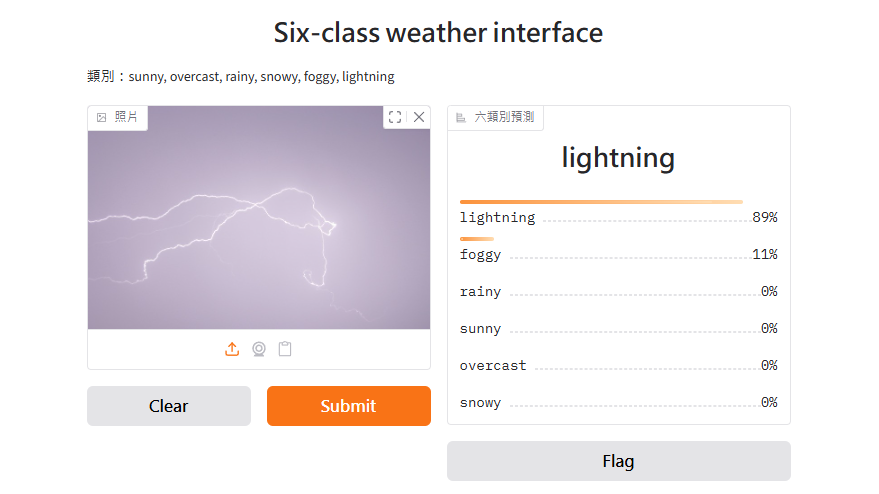

In [49]:
# 9.4 六類別的推論介面。作業要求 Gradio 的顯示也必須同步更新，因此這個
# cell 重用相同的載入器與前處理，但顯示六個具名分數，並附上每類一張的示範表。
def predict_six(image):
    if six_model is None:
        raise gr.Error("六類別模型尚未訓練。")
    if image is None:
        raise gr.Error("請先選擇一張圖片。")
    arr = W.read_model_input(image, W.spec_for("mobilenet_v2").image_size)[None, ...]
    probs = six_model.predict(
        np.asarray(W.spec_for("mobilenet_v2").fn(arr)), verbose=0)[0]
    return {name: float(p) for name, p in zip(SIX, probs)}


six_demo = gr.Interface(
    fn=predict_six,
    inputs=gr.Image(type="filepath", label="照片"),
    outputs=[gr.Label(num_top_classes=6, label="六類別預測")],
    title="Six-class weather interface",
    description=f"類別：{', '.join(SIX)}",
)
six_demo.launch()

if six_index is not None:
    six_val_split = six_split[six_split["split"] == "val"]
    rows = []
    for label in SIX:
        sample = six_val_split[six_val_split["label"] == label].head(1)
        if sample.empty:
            continue
        scores = predict_six(str(sample["path"].iat[0]))
        best = max(scores, key=lambda k: scores[k])
        # Path().name 可以避免對 Scalar 值做位元級的 rsplit。
        rows.append({"image": Path(str(sample["path"].iat[0])).name,
                     "expected": label, "predicted": best,
                     "match": best == label,
                     "score": round(scores[best], 3)})
    demo = pd.DataFrame(rows)
    display(demo)
    print("正確：", int(demo["match"].sum()), "/", len(demo))
else:
    print("[待完成] 第 9.2 節尚未執行")


* Running on local URL:  http://127.0.0.1:7864


* To create a public link, set `share=True` in `launch()`.


,image,expected,predicted,match,score
0,bdd_000.jpg,sunny,sunny,True,0.414
1,cloudy1.jpg,overcast,overcast,True,0.989
2,rain110.jpg,rainy,rainy,True,0.976
3,snowy_0003.jpg,snowy,snowy,True,1.000
4,foggy_0018.jpg,foggy,foggy,True,0.943
5,lightning_0004.jpg,lightning,lightning,True,1.000


正確： 6 / 6
